# SPX 0DTE Iron Condor, 10-wide, 20 tranches: the strategy, built one setting at a time

**The trade.** An SPX iron condor expiring the same day: a short call spread and a short put spread, each 10 points wide, opened
every 20 minutes (the export has 20 entries a day from 09:32) and held to the close. It makes money when SPX stays between the
short strikes until 16:00. Inside the strategy each condor collects about **$326** (median $325: $175 call side, $145 put side), with
short strikes a median 11.4 points (call) and 12.9 points (put) from spot.

**The strategy: every setting used**, in the order the greedy cascade adds them (Section 2).

| step | setting | value |
|---|---|---|
| 1 | weekdays | **Monday, Tuesday, Wednesday, Friday** (no Thursdays) |
| 2 | max SPX move up | **max 0%**: SPX at or below its 09:30 open at entry |
| 3 | trend | **above the 10-day SMA**: SPX at entry against the average of the last 9 closes and the entry price |
| 4 | term structure | **VIX9D/VIX: min 0.87, max 1.02**, read at each trade's entry minute |
| 5 | entry times | **7 tranches: 11:33 AM, 11:53 AM, 12:13 PM, 1:13 PM, 1:53 PM, 2:13 PM, 2:53 PM** (the first seven forward selection adds) |
| 6 | short/long ratio | **max 4** for the whole condor: the two short prices over the two long prices |
| | exit | **none: every condor held to expiry**. The 400% call stop is studied in Section 9 (why it isn't used), not as a step |
| | always | 0DTE, exact strike offsets, 10-wide wings; 1 contract per trade; $0.97 per contract to open and to close, $0.05 entry slippage |

**How this notebook works: a greedy cascade.** It starts from the raw export (every condor, every session, held to expiry). At each step
it **tries every setting not yet added on the book built so far, and adds the one that raises Sharpe the most**, until all six are in.
The order comes from the data, not from a choice. **Each setting is then studied on the book built so far**: the earlier settings on,
the later ones off. Every chart title gives the step's **trades, P/L and Sharpe before -> after** the setting is added. The last sections
show why there is no stop, check each threshold again with everything on, look at the drawdowns by tranche, rank the settings against
other features, and test the 10-day SMA against the 20-day.

| § | |
|---|---|
| 2 | The greedy search, and the cascade it builds: trades, P/L and Sharpe at each step |
| 3-8 | One section per step, in the greedy order: what the setting does to the book built so far, why, and where its threshold sits |
| 9 | The call and put stops: why the strategy uses neither |
| 10 | With everything on: is each threshold still at its best? |
| 11 | Drawdowns by tranche: where the losses come from, and whether to cut the 7 further |
| 12 | Feature ranking and correlation |
| 13 | A/B with everything on: above the 10-day SMA vs the 20-day |
| 14 | The 2026 drawdown, in the backtester's own log (past the end of the export) |
| 15 | Summary |

**How to read the numbers.**

- **The baseline is the raw export**: every condor on every session, held to expiry. It loses money: **-$7.5k at Sharpe -0.12**.
- **One trade = one vertical spread**, as the backtester counts (a condor is two trades). **P/L** is per condor unless it says per
  session.
- **Every version is scored on all 998 sessions** (2022-05 to 2026-05); days it doesn't trade count as zero.
- **Sharpe is the backtester's**: daily P/L over the $200k starting capital, less a 4% risk-free rate, annualised. Because of the
  risk-free rate, **a version that trades less pays the hurdle on more idle days**, so cutting trades lowers Sharpe unless the trades
  cut were genuinely bad.
- **Every rule is measured the backtester's way** (VIX9D/VIX at entry, the condor's short/long ratio, SPX at entry against its
  SMA) and **every condor is held to expiry**, as the strategy trades it. The call stop in Section 9 is replayed from each spread's
  worst intraday loss (never on the settlement print), filled where the SPXW option chain crossed it.
- **2022-2024 vs 2025-2026**: each version is also scored on the two halves, as a stability check.
- **Everything is in-sample**, apart from the walk-forward checks in Sections 7 and 11. Intervals are 95% session-bootstrap intervals.

## 1. Setup and data

| file | what it is |
|---|---|
| `data/strategy/ic_strat/spx/raw_baseline/IC-20-Tranche-10-Baseline.csv` | the Option Omega export (`ic 20 tranch 10 spread.csv`), one row per vertical spread, every spread held to expiry, all 20 entry times. A call and a put row with the same date and time make one condor (one unmatched leg is dropped). Each row carries its legs and prices, `Max Loss` (its worst intraday loss), the 16:00 `Closing Price` and the opening gap. |
| `data/market/vix/ohlc/VIX9D_<date>_1m.parquet`, `VIX_<date>_1m.parquet` | 1-minute VIX9D and VIX bars: the term structure at each entry minute |
| `data/market/spx/options_ohlc/SPXW_<date>_ohlc.parquet` | the SPXW 0DTE option chain, 1-minute prices, 739 of the 998 sessions: where a call stop would have filled (Section 9) |
| `data/market/vix/term_structure_daily.csv`, `data/market/vvix/vvix_daily_cboe.csv` | daily VIX family and VVIX, for the features in Section 12 |

None of these are in git (`data/` is git-ignored; see "Data" in the root README). The 10-day SMA needs 9 closes before each session,
so the export's first 9 sessions (to 2022-05-26) can't pass the SMA step.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[2]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from strategies.ic_strat.analysis.ic_analysis import DEFAULT_CSV
from strategies.ic_strat.analysis import final_version as fv
from strategies.ic_strat.analysis import cascade as cs
from strategies.ic_strat.analysis import tranche_drawdown as td
from strategies.ic_strat.analysis import thursday as th
from strategies.ic_strat.analysis import log_2026 as lg
from strategies.ic_strat.analysis.notebook_display import compact_figures

compact_figures()   # charts as compact PNGs, so GitHub renders the notebook

study = fv.compute_final_study(DEFAULT_CSV)   # ~2 min: the panel, the stop replay, the ranking
panel = study.panel
casc = cs.compute(panel)                      # the greedy search and every step of the cascade
ct = casc.table
print(f"{len(panel):,} condors over {panel.date.nunique()} sessions, {panel.date.min():%Y-%m-%d} to {panel.date.max():%Y-%m-%d}")
print(f"greedy order: {' -> '.join(casc.greedy.attrs['order'])} (matches the sections below: {casc.greedy.attrs['matches']})")

19,847 condors over 998 sessions, 2022-05-16 to 2026-05-07
greedy order: thursday -> move -> sma10 -> band -> tranches -> ratio (matches the sections below: True)


## 2. The greedy search, and the cascade it builds

**The search.** Each row is one step. Every setting not yet added is tried on the book built so far; the cell is the Sharpe the book would
have with it. The highest (highlighted) is added, and the next row starts from that book.

In [2]:
display(cs.greedy_view(casc.greedy))

,picked,VIX9D/VIX 0.87-1.02 at entry,max move up 0%,above the 10-day SMA,short/long ratio <= 4,no Thursdays,7 forward-selected tranches
step,,,,,,,
1,no Thursdays,-0.11,0.37,0.35,-0.00,0.44,0.12
2,max move up 0%,0.66,0.97,0.71,0.59,,0.56
3,above the 10-day SMA,1.39,,1.50,1.15,,1.03
4,VIX9D/VIX 0.87-1.02 at entry,2.25,,,1.74,,1.66
5,7 forward-selected tranches,,,,2.40,,2.48
6,short/long ratio <= 4,,,,2.60,,


| step | settings tried: Sharpe if added | added |
|---|---|---|
| 1 (raw book) | **no Thursdays 0.44**, max move 0.37, SMA10 0.35, tranches 0.12, ratio 0.00, band -0.11 | **no Thursdays** |
| 2 | **max move 0.97**, SMA10 0.71, band 0.66, ratio 0.59, tranches 0.56 | **max move 0%** |
| 3 | **SMA10 1.50**, band 1.39, ratio 1.15, tranches 1.03 | **above the 10-day SMA** |
| 4 | **band 2.25**, ratio 1.74, tranches 1.66 | **VIX9D/VIX band** |
| 5 | **tranches 2.48**, ratio 2.40 | **the 7 tranches** |
| 6 | **ratio 2.60** | **short/long ratio <= 4** |

- **No Thursdays wins step 1** because Thursdays are where the raw book loses its money (Section 3); max move and the 10-day SMA are close
  behind (0.37, 0.35).
- **The band only pays once the move and trend filters are on:** on the raw book it scores -0.11 (the worst of the entry filters); at step 4
  it adds the most of any step (+0.75).
- **The tranche step is the fixed set of 7**; Section 7 shows they are the first seven forward selection picks at that point, and what a
  selection by drawdown picks on its own.

**The cascade it builds.** Each bar is a full version scored on all 998 sessions.

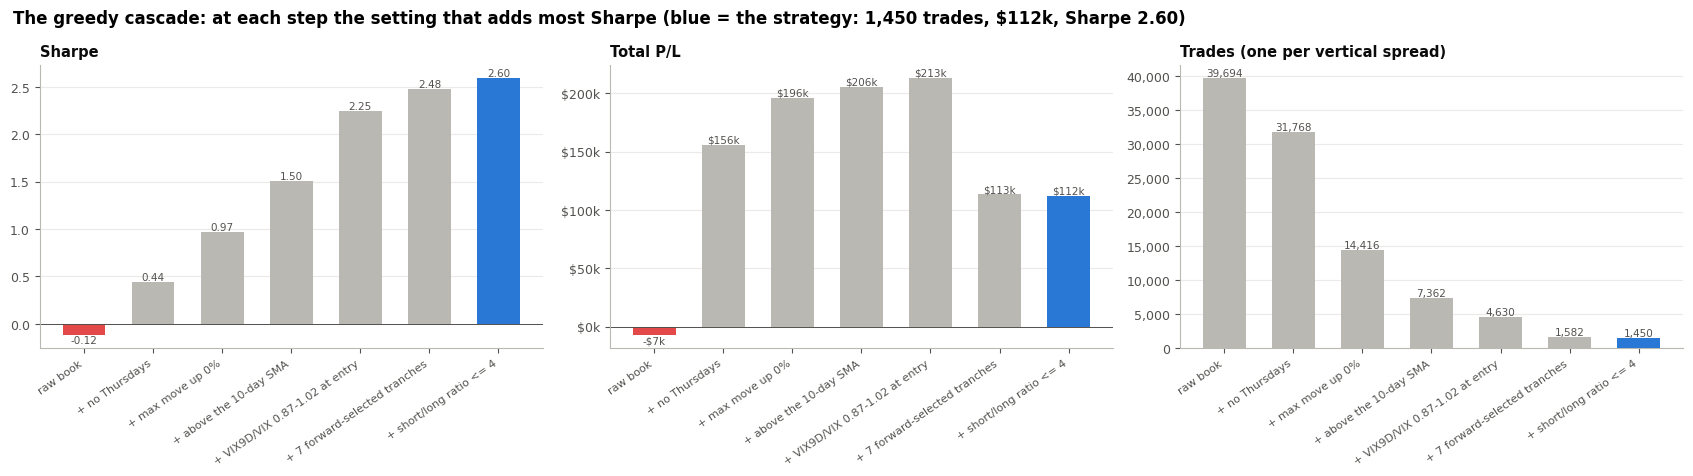

,trades,sessions,total_pl,sharpe,sharpe_to_2024,sharpe_from_2025,max_drawdown,win_rate_trade,win_rate_condor,avg_pl_condor,trades_change,total_pl_change,sharpe_change
step,,,,,,,,,,,,,
raw book,39694.0,998.0,-7464.36,-0.12,-0.09,-0.20,-113337.60,79.47,66.09,-0.38,NaN,NaN,NaN
1. + no Thursdays,31768.0,799.0,155558.08,0.44,0.58,0.13,-67902.08,79.86,67.04,9.79,-7926.0,163022.44,0.56
2. + max move up 0%,14416.0,656.0,195906.96,0.97,1.05,0.80,-33625.72,81.65,69.71,27.18,-17352.0,40348.88,0.53
3. + above the 10-day SMA,7362.0,404.0,205624.72,1.50,1.54,1.43,-22504.00,81.87,70.80,55.86,-7054.0,9717.76,0.53
4. + VIX9D/VIX 0.87-1.02 at entry,4630.0,294.0,213278.80,2.25,2.16,2.48,-15130.04,83.39,73.95,92.13,-2732.0,7654.08,0.75
5. + 7 forward-selected tranches,1582.0,188.0,113370.92,2.48,2.33,2.83,-4888.92,85.65,79.14,143.33,-3048.0,-99907.88,0.23
6. + short/long ratio <= 4,1450.0,187.0,112044.00,2.60,2.44,2.92,-3808.68,87.38,80.97,154.54,-132.0,-1326.92,0.12


In [3]:
cs.fig_cascade(ct); plt.show()
display(ct.round(2))

| step | trades | total P/L | Sharpe | 2022-24 / 2025-26 | max drawdown | win per trade |
|---|---|---|---|---|---|---|
| raw book | 39,694 | -$7.5k | -0.12 | -0.09 / -0.20 | -$113.3k | 79.5% |
| 1. + no Thursdays | 31,768 | $155.6k | 0.44 | 0.58 / 0.13 | -$67.9k | 79.9% |
| 2. + max move up 0% | 14,416 | $195.9k | 0.97 | 1.05 / 0.80 | -$33.6k | 81.7% |
| 3. + above the 10-day SMA | 7,362 | $205.6k | 1.50 | 1.54 / 1.43 | -$22.5k | 81.9% |
| 4. + VIX9D/VIX 0.87-1.02 | 4,630 | **$213.3k** | 2.25 | 2.16 / 2.48 | -$15.1k | 83.4% |
| 5. + 7 forward-selected tranches | 1,582 | $113.4k | 2.48 | 2.33 / 2.83 | -$4.9k | 85.7% |
| **6. + short/long ratio <= 4** | **1,450** | **$112.0k** | **2.60** | **2.44 / 2.92** | **-$3.8k** | **87.4%** |

**The raw book is a coin flip that loses slowly:** a condor wins 66% of the time, but an average win (+$254) is half an average loss
(-$497), so the book drifts to -$7.5k with a -$113k drawdown.

- **The first four steps build the money:** no Thursdays alone turns -$7.5k into +$155.6k; max move, the 10-day SMA and the band each add
  +0.5 to +0.75 Sharpe, and P/L peaks at $213.3k with the band.
- **The 7 tranches and the ratio cap trade money for steadiness:** they cost $101.2k between them but take Sharpe from 2.25 to 2.60 and the
  drawdown from -$15.1k to -$3.8k.

**The strategy: 1,450 trades, $112.0k, Sharpe 2.60, -$3.8k drawdown, 87.4% of trades winning**, held to expiry; +$599 on an average trading
day (76% of days positive), an average win of $285 a condor against an average loss of $399.

## 3. Step 1: no Thursdays, on the raw book

Each step's section shows the step's setting on **the book built so far**; here, the raw book (every condor, held to expiry).

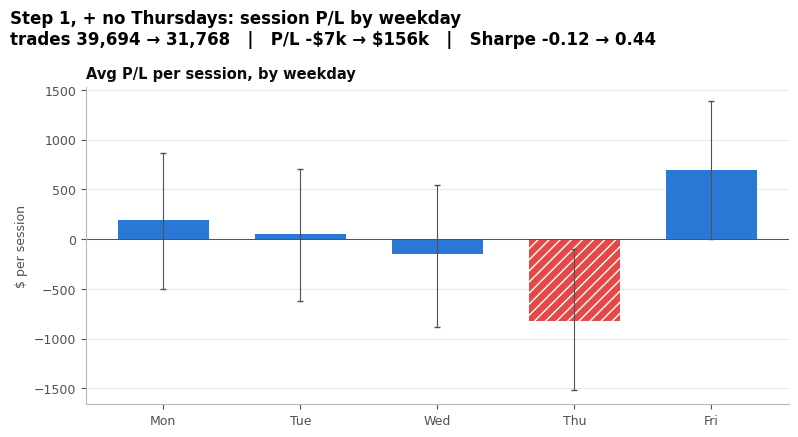

,sessions,trades,avg_session_pl,ci_low,ci_high,winning_sessions_pct,total_pl
weekday,,,,,,,
Monday,185,7356,191.0,-498.8,871.9,63.8,35336.4
Tuesday,207,8262,51.3,-619.7,710.4,60.4,10627.7
Wednesday,205,8154,-146.7,-880.1,549.8,59.5,-30074.8
Thursday,199,7926,-819.2,-1514.5,-98.0,52.8,-163022.4
Friday,202,7996,691.4,-0.6,1389.1,68.3,139668.8


In [4]:
fv.fig_calendar(casc.weekdays, note=cs.note(ct, "thursday", "session P/L by weekday")); plt.show()
display(casc.weekdays.round(1))

| weekday (raw book) | sessions | trades | avg P/L per session | 95% interval | winning sessions | total P/L |
|---|---|---|---|---|---|---|
| Monday | 185 | 7,356 | +$191 | -$499 to +$872 | 64% | +$35.3k |
| Tuesday | 207 | 8,262 | +$51 | -$620 to +$710 | 60% | +$10.6k |
| Wednesday | 205 | 8,154 | -$147 | -$880 to +$550 | 60% | -$30.1k |
| **Thursday** | 199 | 7,926 | **-$819** | **-$1,515 to -$98** | **53%** | **-$163.0k** |
| Friday | 202 | 7,996 | **+$691** | -$1 to +$1,389 | 68% | +$139.7k |

- **Thursday is where the raw book loses its money:** -$163.0k over 199 sessions, the only weekday whose interval sits wholly below zero.
  Without Thursdays the raw book goes from -$7.5k to **+$155.6k** (Sharpe -0.12 -> 0.44).
- **The other days differ too** (Friday +$691 a session, Wednesday -$147), but only Thursday is clearly negative.

### What drives the Thursday loss?

Three questions, first on the raw book (where the greedy search drops Thursdays) and then on the finished strategy with Thursdays allowed
back in:

1. **Are Thursday markets different when the condor is opened?** VIX, VIX9D/VIX, the trend, the move since the open, the gap.
2. **Or does the market move differently after entry?** Each side's P/L, the session's range, and the range against the move VIX implied
   at the open (VIX / sqrt(252)): above the other days means Thursdays move more than VIX priced.
3. **Is it a few days or every Thursday?** The worst sessions' share, and Thursday by year.

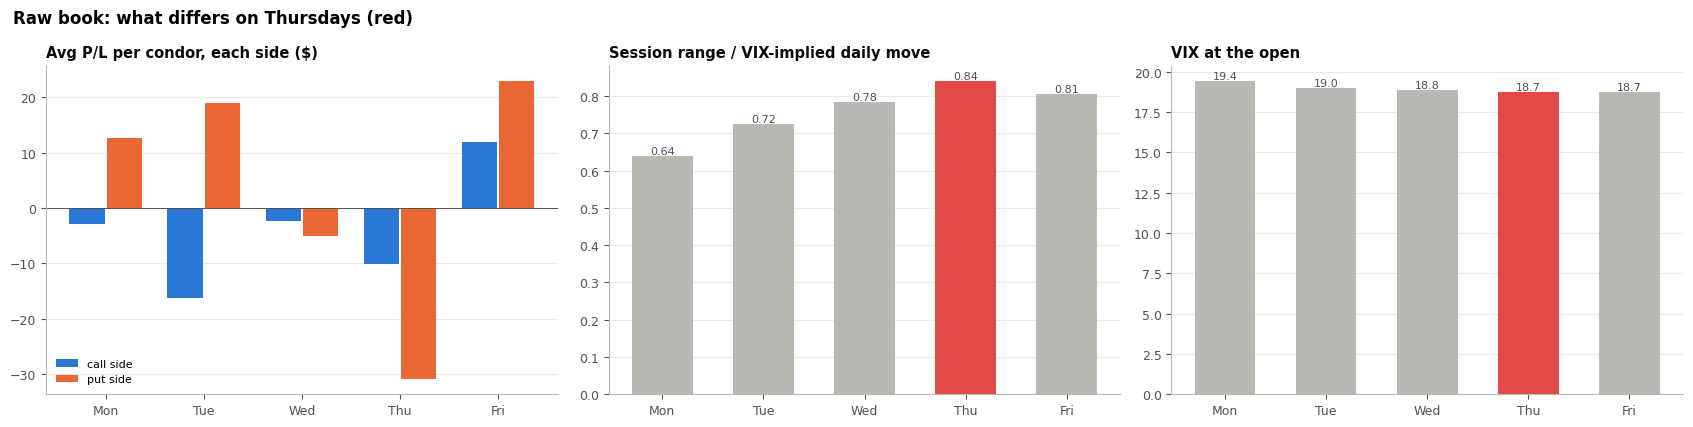

weekday,Monday,Tuesday,Wednesday,Thursday,Friday
sessions,185.00,207.00,205.00,199.00,202.00
trades,7356.00,8262.00,8154.00,7926.00,7996.00
avg_pl,9.61,2.57,-7.38,-41.14,34.93
avg_pl_call,-2.95,-16.33,-2.39,-10.16,11.94
avg_pl_put,12.56,18.90,-4.98,-30.98,22.99
call_breached_pct,28.96,30.48,25.97,28.44,24.94
put_breached_pct,22.10,20.89,21.17,23.74,19.06
vix_open,19.39,18.96,18.84,18.74,18.73
ts_9d_30_entry,0.98,0.97,0.96,0.95,0.93
above_sma10_pct,66.56,62.91,61.98,62.05,59.20


In [5]:
thu = th.compute(panel)
th.fig_weekdays(thu.profiles["raw book"], "Raw book: what differs on Thursdays (red)"); plt.show()
display(thu.profiles["raw book"].round(2).T)

| raw book, per weekday | Mon | Tue | Wed | **Thu** | Fri |
|---|---|---|---|---|---|
| *known at entry* | | | | | |
| VIX at the open | 19.4 | 19.0 | 18.8 | **18.7** | 18.7 |
| VIX9D/VIX at entry | 0.98 | 0.97 | 0.96 | **0.95** | 0.93 |
| SPX above its SMA10 | 67% | 63% | 62% | **62%** | 59% |
| SPX move since the open at entry | +0.11% | -0.02% | +0.04% | **-0.04%** | +0.02% |
| abs. opening gap | 0.38% | 0.34% | 0.33% | **0.41%** | 0.34% |
| *what happened after* | | | | | |
| avg P/L per condor: call / put side | -$3 / +$13 | -$16 / +$19 | -$2 / -$5 | **-$10 / -$31** | +$12 / +$23 |
| SPX through the short put | 22% | 21% | 21% | **24%** | 19% |
| session range | 0.80% | 0.90% | 0.98% | **1.01%** | 0.97% |
| sessions with a range above 1% | 26% | 31% | 32% | **43%** | 37% |
| range / VIX-implied move | 0.64 | 0.72 | 0.78 | **0.84** | 0.81 |

- **Nothing known at entry sets Thursday apart.** VIX is the same (18.7), the curve is ordinary (0.95), the trend and the move into the entry
  are ordinary. Only the opening gap is a little larger (0.41%).
- **What differs is what happens after:** Thursday has the widest sessions (1.01% on average, and 43% of Thursdays move more than 1% against
  26-37% on other days), the most movement relative to what VIX priced (0.84), and **the put side breaks** (-$31 a condor, the short put
  breached on 24%).

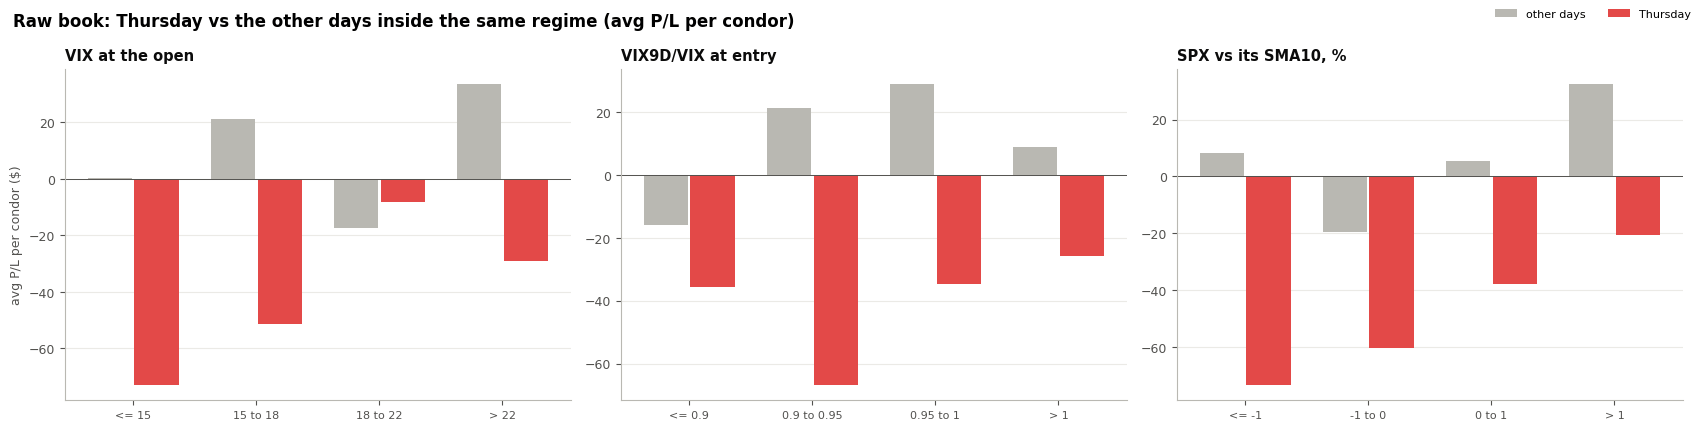

thursday_trades  thursday_avg_pl  other_days_avg_pl  difference  thursday_range_vs_implied  other_range_vs_implied
regime              bucket                                                                                                                         
VIX at the open     <= 15                   1840           -73.08               0.26      -73.35                       0.81                    0.66
                    15 to 18                2462           -51.56              21.05      -72.61                       0.81                    0.69
                    18 to 22                1952            -8.11             -17.40        9.29                       0.87                    0.77
                    > 22                    1672           -29.19              33.52      -62.71                       0.87                    0.86
VIX9D/VIX at entry  <= 0.9                  2038           -35.80             -15.90      -19.91                       0.77                    0.65
                    0.9 to 0.95             2076           -66.90              21.21      -88.11                       0.87                    0.71
                    0.95 to 1               1718           -34.90              28.81      -63.71                       0.99                    0.77
                    > 1                     2094           -25.91               8.68      -34.59                       0.98                    0.88
SPX vs its SMA10, % <= -1                   1482           -73.56               8.19      -81.76                       1.07                    0.94
                    -1 to 0                 1450           -60.42             -19.45      -40.97                       1.00                    0.87
                    0 to 1                  2480           -37.85               5.40      -43.26                       0.90                    0.76
                    > 1                     2438           -20.59              32.54      -53.13                       0.78                    0.69

condor P/L on a Thursday dummy ($ per condor; standard errors clustered by session):


,condors,thursday_effect,se,t,p
model,,,,,
Thursday alone,19847,-50.930,20.566,-2.476,0.013
+ every entry feature,19650,-54.568,20.639,-2.644,0.008
+ the session's range vs implied (an outcome),19650,-19.234,17.937,-1.072,0.284


In [6]:
th.fig_regimes(thu.regimes["raw book"], "Raw book: Thursday vs the other days inside the same regime (avg P/L per condor)"); plt.show()
display(thu.regimes["raw book"].round(2))
print("condor P/L on a Thursday dummy ($ per condor; standard errors clustered by session):")
display(thu.regressions["raw book"].round(3))

**Is it the VIX regime?** No. Inside every VIX, VIX9D/VIX and trend bucket, Thursday is worse than the other days, by $20-88 a condor,
with one exception (VIX 18-22, where both lose). And in every bucket, Thursday's range against the VIX-implied move is higher (for VIX
under 15: 0.81 against 0.66).

**The regression says the same, with a test:**

| condor P/L on a Thursday dummy (raw book) | Thursday effect, $ per condor | t | p |
|---|---|---|---|
| Thursday alone | **-$51** | -2.48 | 0.013 |
| + every feature known at entry (VIX, VIX9D/VIX, move since open, SMA10, gap, credit, entry time) | **-$55** | -2.64 | 0.008 |
| + the session's range vs implied (an outcome) | -$19 | -1.07 | 0.28 |

- **Controlling for everything known at entry doesn't shrink the Thursday effect** (-$51 -> -$55): it isn't the VIX regime, the curve, the
  trend or the morning's move.
- **Controlling for how much the market actually moved removes about two-thirds of it** (-$55 -> -$19, no longer significant): the Thursday
  loss is Thursdays moving more than VIX priced at the open.

In [7]:
c = thu.concentration["raw book"]
display(c["sessions"].round(1))
display(c["worst"].round(0))
display(c["by_year"].round(0))
display(c["worst_days"].round(0))

,median_session_pl,mean_session_pl,winning_sessions_pct
day,,,
Thursday,460.4,-819.2,52.8
other days,1870.4,194.7,63.0


,pl,thursday_total,rest_of_thursdays
worst_n,,,
5,-67438.0,-163022.0,-95584.0
10,-125433.0,-163022.0,-37589.0
20,-227342.0,-163022.0,64320.0


day,Thursday,other days,thursday_sessions
year,,,
2022,-490.0,561.0,32
2023,-1841.0,429.0,51
2024,-453.0,-115.0,50
2025,-239.0,107.0,48
2026,-1075.0,9.0,18


,pl
date,
2025-02-27,-14979.0
2022-06-09,-14283.0
2022-11-10,-13399.0
2023-08-24,-12486.0
2025-01-23,-12293.0
2025-09-04,-11886.0
2023-09-21,-11803.0
2023-03-09,-11549.0
2026-01-29,-11418.0


**A few big days, but every year.**

- **The ten worst Thursdays lose $125.4k of the $163.0k:** the median Thursday session still makes money (+$460, against +$1,870 on other
  days), and 53% of Thursdays win (63% on other days).
- **It repeats every year:** the average Thursday session loses in all five years (-$239 to -$1,841), while the other days make money in
  every year but 2024.
- **The worst Thursdays include known macro days:** 2022-11-10 was a CPI release (SPX +5.5%), 2024-01-11 a CPI release, and 2023-07-27 and
  2023-09-21 the day after a Fed decision. Thursday also carries the weekly 8:30 jobless claims. **This data has no economic calendar**, so
  the macro link is a hypothesis to test, not a finding: what the data shows is that Thursdays realise more movement than VIX prices, on a
  handful of days, every year.

**With the other filters on.** The finished strategy with Thursdays allowed back in: 412 Thursday trades, -$4.5k between them.

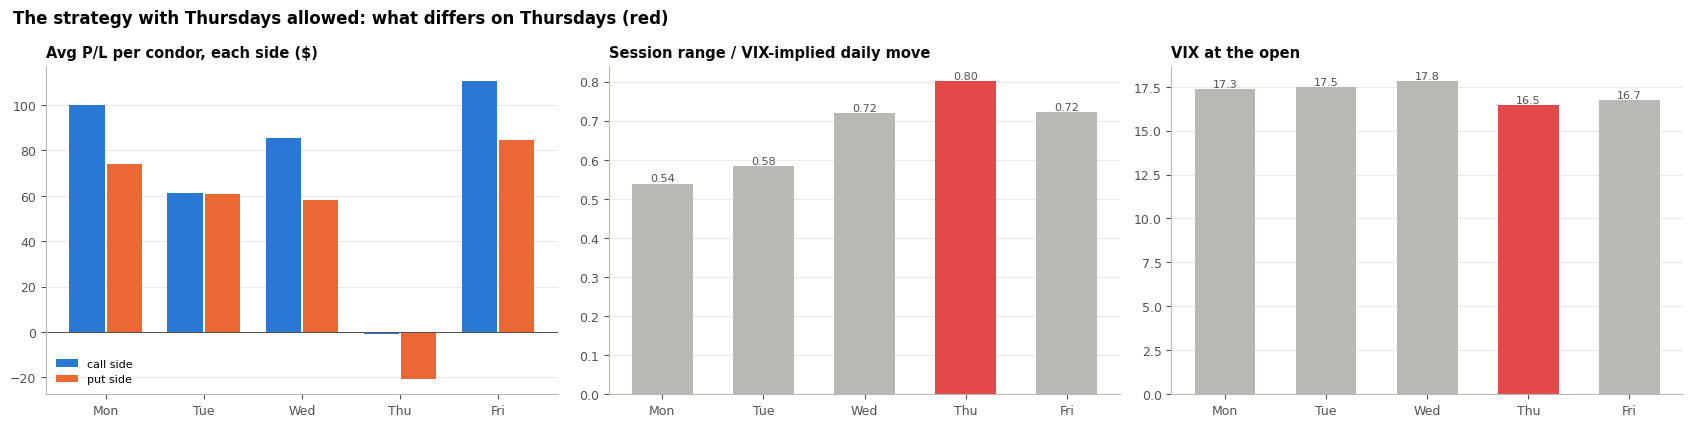

weekday,Monday,Tuesday,Wednesday,Thursday,Friday
sessions,47.00,53.00,48.00,50.00,39.00
trades,352.00,436.00,374.00,412.00,288.00
avg_pl,173.93,121.85,143.22,-21.91,195.04
avg_pl_call,100.06,61.18,85.31,-1.09,110.52
avg_pl_put,73.87,60.67,57.90,-20.82,84.53
call_breached_pct,19.32,22.48,15.51,27.18,15.28
put_breached_pct,14.20,15.60,13.37,22.33,14.58
vix_open,17.35,17.45,17.79,16.47,16.72
ts_9d_30_entry,0.94,0.94,0.95,0.93,0.93
above_sma10_pct,100.00,100.00,100.00,100.00,100.00


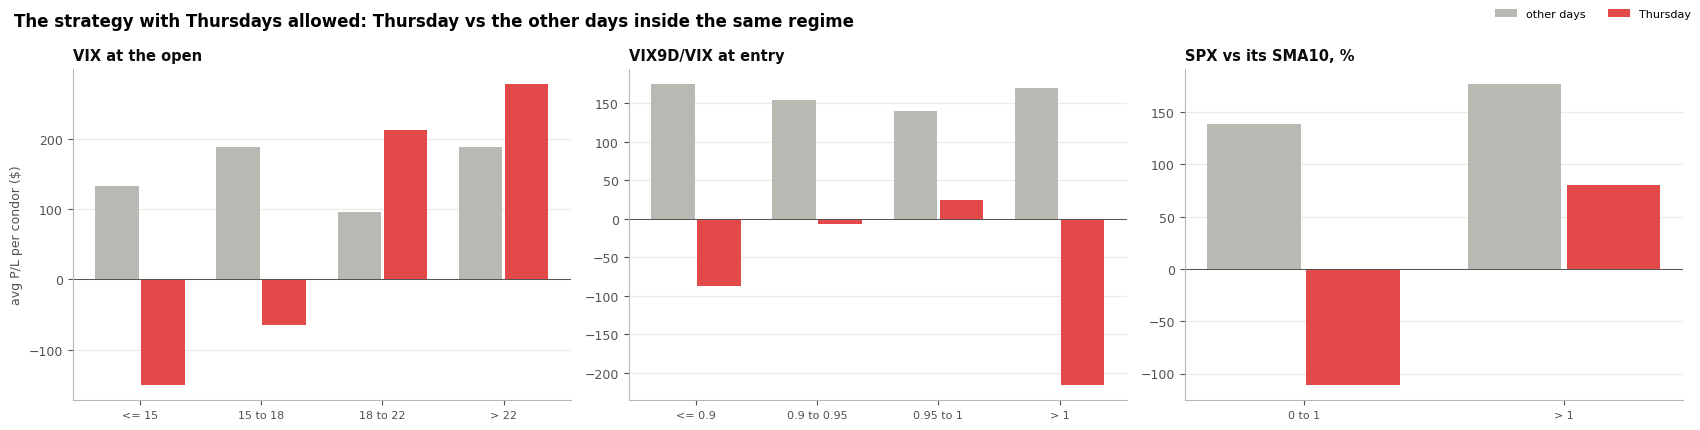

thursday_trades  thursday_avg_pl  other_days_avg_pl  difference  thursday_range_vs_implied  other_range_vs_implied
regime              bucket                                                                                                                         
VIX at the open     <= 15                    148          -150.24             132.92     -283.17                       0.91                    0.66
                    15 to 18                 162           -64.35             188.63     -252.98                       0.78                    0.56
                    18 to 22                  72           212.51              95.54      116.97                       0.72                    0.63
                    > 22                      30           277.79             188.43       89.35                       0.56                    0.72
VIX9D/VIX at entry  <= 0.9                    92           -86.86             175.13     -261.99                       0.79                    0.60
                    0.9 to 0.95              204            -7.13             154.37     -161.50                       0.84                    0.58
                    0.95 to 1                106            24.35             139.80     -115.45                       0.84                    0.70
                    > 1                       10          -216.08             169.18     -385.26                       0.97                    0.82
SPX vs its SMA10, % 0 to 1                   220          -111.16             138.60     -249.76                       0.89                    0.63
                    > 1                      192            80.36             177.01      -96.65                       0.71                    0.64

,condors,thursday_effect,se,t,p
model,,,,,
Thursday alone,931,-176.453,53.185,-3.318,0.001
+ every entry feature,931,-181.069,51.125,-3.542,0.000
+ the session's range vs implied (an outcome),931,-122.292,44.091,-2.774,0.006


,median_session_pl,mean_session_pl,winning_sessions_pct
day,,,
Thursday,201.7,-90.3,56.0
other days,587.2,599.2,76.5


,pl,thursday_total,rest_of_thursdays
worst_n,,,
5,-14918.0,-4513.0,10404.0
10,-24387.0,-4513.0,19874.0
20,-31196.0,-4513.0,26683.0


day,Thursday,other days,thursday_sessions
year,,,
2022,1707.0,843.0,4
2023,-772.0,594.0,13
2024,157.0,464.0,15
2025,-197.0,517.0,14
2026,-229.0,1173.0,4


In [8]:
th.fig_weekdays(thu.profiles["strategy with Thursdays"], "The strategy with Thursdays allowed: what differs on Thursdays (red)"); plt.show()
display(thu.profiles["strategy with Thursdays"].round(2).T)
th.fig_regimes(thu.regimes["strategy with Thursdays"], "The strategy with Thursdays allowed: Thursday vs the other days inside the same regime"); plt.show()
display(thu.regimes["strategy with Thursdays"].round(2))
display(thu.regressions["strategy with Thursdays"].round(3))
c = thu.concentration["strategy with Thursdays"]
display(c["sessions"].round(1))
display(c["worst"].round(0))
display(c["by_year"].round(0))

| strategy with Thursdays, per weekday | Mon | Tue | Wed | **Thu** | Fri |
|---|---|---|---|---|---|
| avg P/L per condor | +$174 | +$122 | +$143 | **-$22** | +$195 |
| call / put side | +$100 / +$74 | +$61 / +$61 | +$85 / +$58 | **-$1 / -$21** | +$111 / +$85 |
| short call / short put breached | 19% / 14% | 22% / 16% | 16% / 13% | **27% / 22%** | 15% / 15% |
| VIX at the open | 17.4 | 17.5 | 17.8 | **16.5** | 16.7 |
| sessions with a range above 1% | 4% | 11% | 23% | **32%** | 26% |
| range / VIX-implied move | 0.54 | 0.58 | 0.72 | **0.80** | 0.72 |

| condor P/L on a Thursday dummy (strategy with Thursdays) | Thursday effect, $ per condor | t | p |
|---|---|---|---|
| Thursday alone | **-$176** | -3.32 | 0.001 |
| + every feature known at entry | **-$181** | -3.54 | <0.001 |
| + the session's range vs implied (an outcome) | -$122 | -2.77 | 0.006 |

- **The same story inside the strategy:** entry conditions are ordinary (VIX is in fact the lowest, 16.5), but Thursdays move more than VIX
  priced (0.80 against 0.54-0.72), both short strikes break more often, and the entry features explain none of the gap.
- **The realized move explains about a third of it here** (-$181 -> -$122, still significant): even for the same range, Thursday condors do
  worse, which fits an intraday shock (a release or a reversal) more than a steady trend.
- **It is a low-VIX problem:** Thursdays lose with VIX under 18 (-$150 and -$64 a condor, against +$133 and +$189 on other days), where VIX
  most underprices them (range / implied 0.91 and 0.78 against 0.66 and 0.56); above 18 the few Thursday trades (102) earn.
- **Five bad Thursdays sink the rest:** the worst five lose $14.9k, more than all Thursdays together (-$4.5k); the other Thursdays make
  +$10.4k. The median Thursday session still wins (+$202), but only 56% of them do, against 77% of other days.

**Why no Thursdays, in one line:** not a VIX regime and nothing visible at entry, but Thursdays realise more movement than VIX prices at the
open, mostly on a few big days each year (macro releases are the likely cause, untested here), and a short-volatility condor has no defence
against that. Skipping the day is the only filter that removes it.

## 4. Step 2: max move up 0%, on the book after step 1

SPX's move since the 09:30 open at the moment the condor enters. Four panels:

1. **avg P/L per condor**, with its interval;
2. **which side earns or loses**: the call spread's P/L against the put spread's (held to expiry);
3. **the mechanism**: what the market did after entry;
4. **total P/L** in each group.

The shaded groups are the ones the setting keeps.

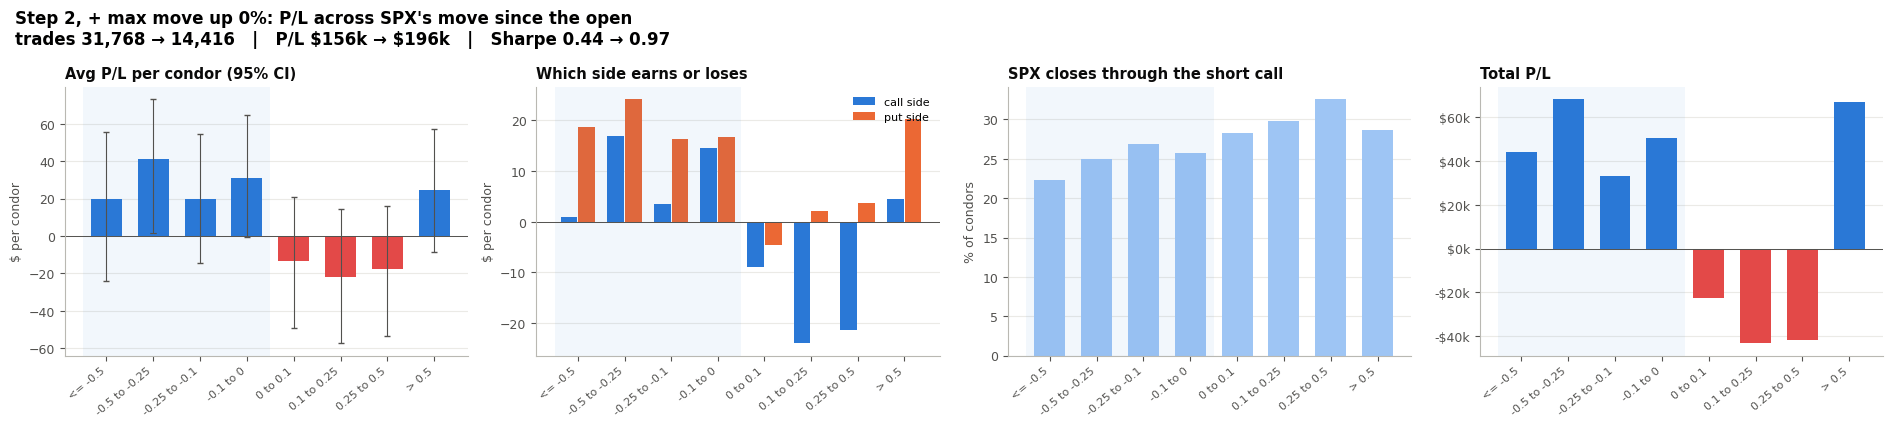

,condors,trades,sessions,avg_pl,ci_low,ci_high,win_rate,avg_pl_to_2024,avg_pl_from_2025,total_pl,avg_pl_call,avg_pl_put,call_breached_pct,put_breached_pct,abs_move_after_entry_pct,day_range_pct,in_strategy
bin,,,,,,,,,,,,,,,,,
<= -0.5,2254,4508,271,19.5,-23.9,55.5,70.5,27.3,2.3,44049.5,1.0,18.6,22.3,19.0,0.4,1.4,True
-0.5 to -0.25,1665,3330,378,41.0,1.8,73.3,71.4,32.5,56.4,68343.8,16.8,24.2,25.0,18.6,0.3,0.9,True
-0.25 to -0.1,1673,3346,482,19.8,-14.5,54.5,67.5,25.8,7.3,33070.8,3.5,16.3,26.9,19.8,0.3,0.7,True
-0.1 to 0,1616,3232,523,31.2,-0.4,64.9,69.2,35.5,22.2,50442.9,14.6,16.6,25.7,19.4,0.3,0.6,True
0 to 0.1,1648,3296,570,-13.6,-49.3,20.6,63.9,3.8,-51.8,-22343.2,-9.0,-4.6,28.3,22.8,0.3,0.7,False
0.1 to 0.25,1972,3944,536,-21.9,-57.4,14.6,63.1,-8.5,-47.7,-43259.4,-24.0,2.0,29.8,22.6,0.4,0.7,False
0.25 to 0.5,2360,4720,456,-17.7,-53.5,16.0,62.7,-20.9,-11.9,-41727.8,-21.3,3.6,32.5,22.7,0.3,0.8,False
> 0.5,2695,5390,307,24.8,-8.7,57.2,68.5,15.4,41.3,66715.4,4.5,20.2,28.6,20.8,0.3,1.2,False


In [9]:
fv.fig_profile(casc.profiles["move"], "spx_move_pct", note=cs.note(ct, "move", "P/L across SPX's move since the open")); plt.show()
display(casc.profiles["move"].round(1))

| SPX since the open at entry | trades | avg P/L | call side | put side | SPX through the short call | total P/L |
|---|---|---|---|---|---|---|
| down more than 0.5% | 4,508 | +$20 | +$1 | +$19 | 22% | +$44.0k |
| **down 0.25-0.5%** | 3,330 | **+$41** | +$17 | +$24 | 25% | +$68.3k |
| **down 0.1-0.25%** | 3,346 | +$20 | +$3 | +$16 | 27% | +$33.1k |
| **down 0-0.1%** | 3,232 | +$31 | +$15 | +$17 | 26% | +$50.4k |
| up 0-0.1% | 3,296 | **-$14** | -$9 | -$5 | 28% | -$22.3k |
| up 0.1-0.25% | 3,944 | **-$22** | **-$24** | +$2 | 30% | -$43.3k |
| up 0.25-0.5% | 4,720 | **-$18** | -$21 | +$4 | **33%** | -$41.7k |
| up more than 0.5% | 5,390 | +$25 | +$5 | +$20 | 29% | +$66.7k |

**Entering after SPX has pulled back is what keeps the call side safe.**

- **Every group at or below the open earns** (+$20 to +$41 a condor); **entries after a 0-0.5% rally lose** (-$14 to -$22), $107.3k
  between them.
- **It's the call side that breaks:** after a rally the call spread loses $9-24 a condor and SPX closes through the short call on 28-33% of
  condors, against 22-27% when SPX is down. In an uptrend an intraday rally tends to keep going into the short call.
- **Big rallies (above +0.5%) earn again**, mostly on the put side, but the 0% cut is the clean rule.

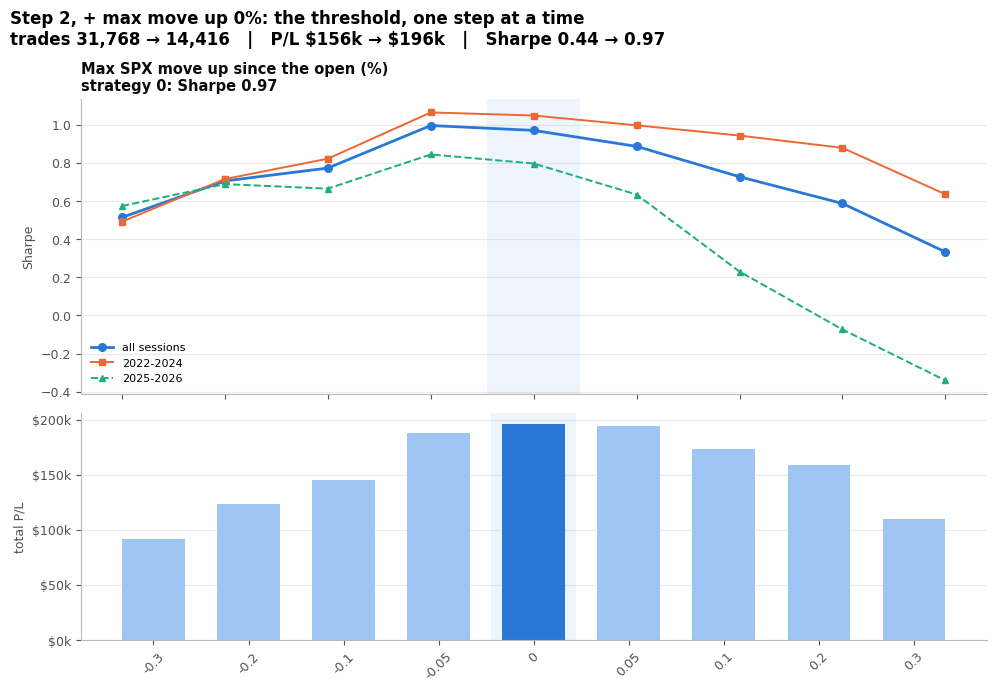

,sessions,trades,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025
max_move,,,,,,,
-0.3,375.0,7034.0,91312.04,0.51,-45124.20,0.49,0.57
-0.2,440.0,8740.0,123366.40,0.71,-38913.72,0.72,0.69
-0.1,543.0,11184.0,145464.04,0.77,-34233.88,0.82,0.67
-0.05,597.0,12660.0,187613.60,1.00,-34167.96,1.07,0.84
0,656.0,14416.0,195906.96,0.97,-33625.72,1.05,0.80
0.05,702.0,16142.0,193891.52,0.89,-35646.00,1.00,0.63
0.1,738.0,17712.0,173563.72,0.73,-35464.80,0.94,0.23
0.2,770.0,20452.0,159178.12,0.59,-46788.04,0.88,-0.07
0.3,788.0,22736.0,110211.16,0.33,-79311.88,0.64,-0.34


In [10]:
fv.fig_sweeps({"max_move": casc.sweeps["max_move"]}, title=cs.note(ct, "move", "the threshold, one step at a time")); plt.show()
display(casc.sweeps["max_move"].drop(columns="is_strategy").round(2))

| max move up | trades | total P/L | Sharpe | 2022-24 / 2025-26 |
|---|---|---|---|---|
| -0.1% | 11,184 | $145.5k | 0.77 | 0.82 / 0.67 |
| -0.05% | 12,660 | $187.6k | **1.00** | 1.07 / 0.84 |
| **0% (strategy)** | **14,416** | **$195.9k** | **0.97** | 1.05 / 0.80 |
| +0.05% | 16,142 | $193.9k | 0.89 | 1.00 / 0.63 |
| +0.1% | 17,712 | $173.6k | 0.73 | 0.94 / 0.23 |
| no limit | 31,768 | $155.6k | 0.44 | 0.58 / 0.13 |

**0% sits at the top**, level with -0.05% (0.97 against 1.00) and with $8.3k more; every step above 0% loses Sharpe fast, above all in
2025-26.

## 5. Step 3: above the 10-day SMA, on the book after steps 1-2

How far SPX sits from its 10-day SMA at the moment of entry, measured the backtester's way (SPX at entry against the average of the last
9 closes and the entry price itself).

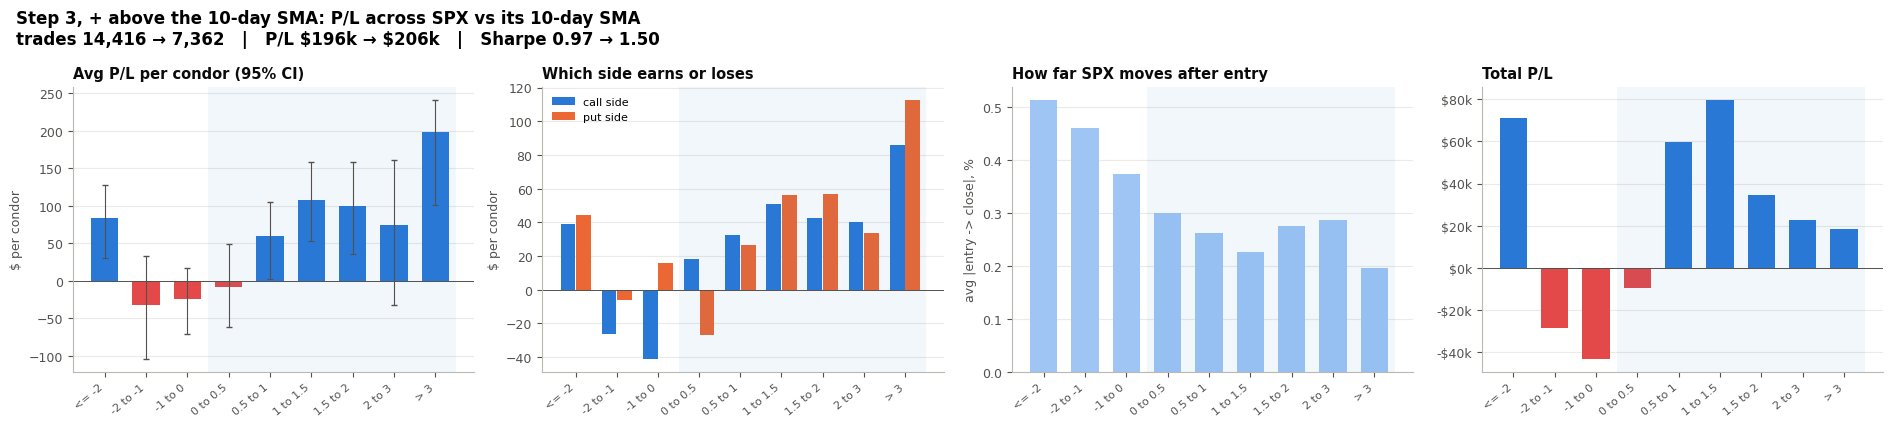

,condors,trades,sessions,avg_pl,ci_low,ci_high,win_rate,avg_pl_to_2024,avg_pl_from_2025,total_pl,avg_pl_call,avg_pl_put,call_breached_pct,put_breached_pct,abs_move_after_entry_pct,day_range_pct,in_strategy
bin,,,,,,,,,,,,,,,,,
<= -2,855,1710,83,83.1,30.2,127.7,81.1,126.2,-31.2,71052.6,39.0,44.1,13.3,13.2,0.5,1.6,False
-2 to -1,870,1740,125,-32.9,-104.6,32.4,67.0,-42.0,-15.4,-28579.6,-26.5,-6.3,23.9,20.7,0.5,1.2,False
-1 to 0,1734,3468,219,-25.0,-70.7,17.4,63.4,-35.5,-1.1,-43400.9,-41.2,16.1,31.6,19.1,0.4,0.9,False
0 to 0.5,1178,2356,180,-8.2,-61.8,49.1,62.3,-16.6,5.4,-9623.6,18.5,-26.7,24.7,25.3,0.3,0.8,True
0.5 to 1,1011,2022,155,59.2,2.6,105.3,71.9,44.0,80.8,59827.3,32.7,26.5,24.7,19.4,0.3,0.7,True
1 to 1.5,745,1490,122,107.2,53.2,158.0,75.8,108.7,102.4,79892.4,51.0,56.2,25.8,19.6,0.2,0.7,True
1.5 to 2,348,696,62,99.1,35.6,159.0,77.0,150.0,-9.7,34481.8,42.4,56.7,25.0,15.5,0.3,0.9,True
2 to 3,307,614,41,74.2,-31.9,160.6,74.9,102.7,25.4,22784.8,40.3,34.0,21.8,16.3,0.3,0.8,True
> 3,92,184,12,198.5,100.9,241.6,89.1,198.9,197.9,18262.0,85.6,112.9,10.9,4.3,0.2,0.7,True


In [11]:
fv.fig_profile(casc.profiles["sma10"], "spx_vs_sma10_pct", note=cs.note(ct, "sma10", "P/L across SPX vs its 10-day SMA")); plt.show()
display(casc.profiles["sma10"].round(1))

**An iron condor is short volatility: it wants SPX to stay still until the close.** Being above the 10-day SMA matters because markets
above their short-term average are calm.

| SPX at entry vs its SMA10 | trades | avg P/L | call side | put side | SPX move after entry | day's range | total P/L |
|---|---|---|---|---|---|---|---|
| below -2% | 1,710 | +$83 | +$39 | +$44 | 0.51% | 1.56% | +$71.1k |
| **-2% to -1%** | 1,740 | **-$33** | -$27 | -$6 | 0.46% | 1.20% | -$28.6k |
| **-1% to 0%** | 3,468 | **-$25** | **-$41** | +$16 | 0.37% | 0.94% | -$43.4k |
| 0% to +0.5% | 2,356 | -$8 | +$18 | -$27 | 0.30% | 0.78% | -$9.6k |
| +0.5% to +1% | 2,022 | +$59 | +$33 | +$26 | 0.26% | 0.69% | +$59.8k |
| +1% to +1.5% | 1,490 | **+$107** | +$51 | +$56 | 0.23% | 0.67% | **+$79.9k** |
| above +1.5% | 1,494 | +$74 to +$199 | | | 0.20-0.29% | 0.74-0.85% | +$75.5k |

- **Below the average SPX moves more after entry** (0.37-0.51% against 0.20-0.30% above) on 0.9-1.6% days.
- **The loss zone is the 2% just below the average:** -$72.0k between the two groups, the call side breaking between -1% and 0%. The filter
  removes it.
- **The first 0.5% above the line is still weak** (-$8 a condor); from +0.5% every group earns, more the further above.
- **Far below (-2% and lower) earns +$83, but all of it in 2022-24 (+$126); in 2025-26 it loses $31 a condor.**

Across **every session with no filter**, the regime split is plain:

In [12]:
display(study.regime.round(3))

,sessions,avg_day_range_pct,day_range_p90_pct,avg_vix,avg_ts_9d_30,avg_session_pl_all_tranches
state,,,,,,
SPX above SMA10,630,0.786,1.393,17.356,0.944,40.151
SPX below SMA10,359,1.168,1.960,21.426,1.010,-122.328


| | sessions | avg day range | 90th pct day range | avg VIX | avg VIX9D/VIX |
|---|---|---|---|---|---|
| **SPX above SMA10** | 630 | **0.79%** | 1.39% | **17.4** | 0.94 |
| SPX below SMA10 | 359 | 1.17% | 1.96% | 21.4 | 1.01 |

Other trend rules in the SMA10 rule's place, on the same book:

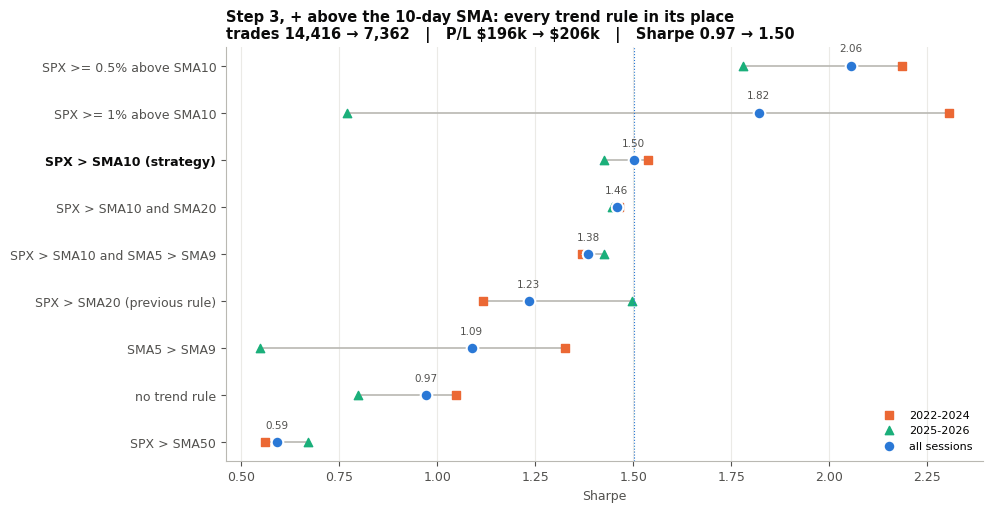

,sessions,trades,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025,sharpe_vs_strategy
no trend rule,656.0,14416.0,195906.96,0.97,-33625.72,1.05,0.80,-0.53
SPX > SMA10 (strategy),404.0,7362.0,205624.72,1.50,-22504.00,1.54,1.43,0.00
SPX >= 0.5% above SMA10,291.0,5006.0,215248.36,2.06,-13105.32,2.19,1.78,0.55
SPX >= 1% above SMA10,182.0,2984.0,155421.04,1.82,-11751.40,2.30,0.77,0.32
SPX > SMA20 (previous rule),437.0,8622.0,188322.32,1.23,-37390.80,1.12,1.50,-0.27
SPX > SMA10 and SMA20,367.0,6652.0,190861.12,1.46,-24526.96,1.46,1.44,-0.04
SPX > SMA50,457.0,10042.0,118131.52,0.59,-44316.56,0.56,0.67,-0.91
SMA5 > SMA9,416.0,9240.0,179532.40,1.09,-38134.16,1.33,0.55,-0.41
SPX > SMA10 and SMA5 > SMA9,337.0,6486.0,184210.16,1.38,-23526.32,1.37,1.43,-0.12


In [13]:
fv.fig_trend(casc.trend, note=cs.note(ct, "sma10", "every trend rule in its place")); plt.show()
display(casc.trend.round(2))

| trend rule (on the book after steps 1-2) | trades | total P/L | Sharpe | 2022-24 / 2025-26 | max drawdown |
|---|---|---|---|---|---|
| no trend rule | 14,416 | $195.9k | 0.97 | 1.05 / 0.80 | -$33.6k |
| **SPX above SMA10 (strategy)** | **7,362** | $205.6k | 1.50 | 1.54 / 1.43 | -$22.5k |
| SPX >= 0.5% above SMA10 | 5,006 | **$215.2k** | **2.06** | 2.19 / 1.78 | **-$13.1k** |
| SPX >= 1% above SMA10 | 2,984 | $155.4k | 1.82 | 2.30 / 0.77 | -$11.8k |
| SPX above SMA20 (the previous rule) | 8,622 | $188.3k | 1.23 | 1.12 / 1.50 | -$37.4k |
| SPX above SMA10 and SMA20 | 6,652 | $190.9k | 1.46 | 1.46 / 1.44 | -$24.5k |
| SPX above SMA10 and SMA5 > SMA9 | 6,486 | $184.2k | 1.38 | 1.37 / 1.43 | -$23.5k |
| SMA5 > SMA9 | 9,240 | $179.5k | 1.09 | 1.33 / 0.55 | -$38.1k |
| SPX above SMA50 | 10,042 | $118.1k | 0.59 | 0.56 / 0.67 | -$44.3k |

- **The SMA10 rule takes Sharpe from 0.97 to 1.50** for $9.7k more and a third off the drawdown; the 20-day in its place scores 1.23.
- **At this step a +0.5% bar scores higher** (2.06, more money, a smaller drawdown): it skips the weak first 0.5% above the line. But the
  band isn't on yet; with everything on, 0% is back at the top (Section 10).

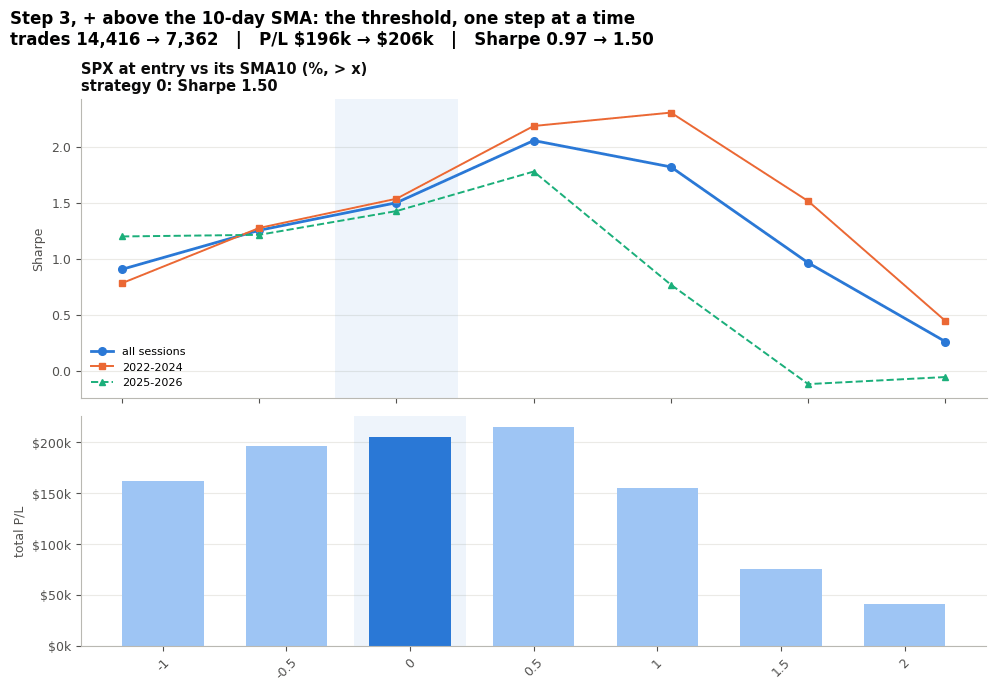

,sessions,trades,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025
sma10_min,,,,,,,
-1,535.0,10830.0,162223.80,0.91,-24304.16,0.78,1.20
-0.5,479.0,9346.0,196631.76,1.26,-26311.64,1.28,1.21
0,404.0,7362.0,205624.72,1.50,-22504.00,1.54,1.43
0.5,291.0,5006.0,215248.36,2.06,-13105.32,2.19,1.78
1,182.0,2984.0,155421.04,1.82,-11751.40,2.30,0.77
1.5,93.0,1494.0,75528.64,0.97,-10057.40,1.52,-0.12
2,48.0,798.0,41046.88,0.26,-6322.08,0.45,-0.05
off,656.0,14416.0,195906.96,0.97,-33625.72,1.05,0.80


In [14]:
fv.fig_sweeps({"sma10_min": casc.sweeps["sma10_min"]}, title=cs.note(ct, "sma10", "the threshold, one step at a time")); plt.show()
display(casc.sweeps["sma10_min"].drop(columns="is_strategy").round(2))

**The 20-day SMA at this step.** The same book with the 20-day SMA in the 10-day's place: P/L across SPX vs its 20-day SMA (not a
filter of the strategy, so nothing is shaded), and both SMAs moved through the same thresholds.

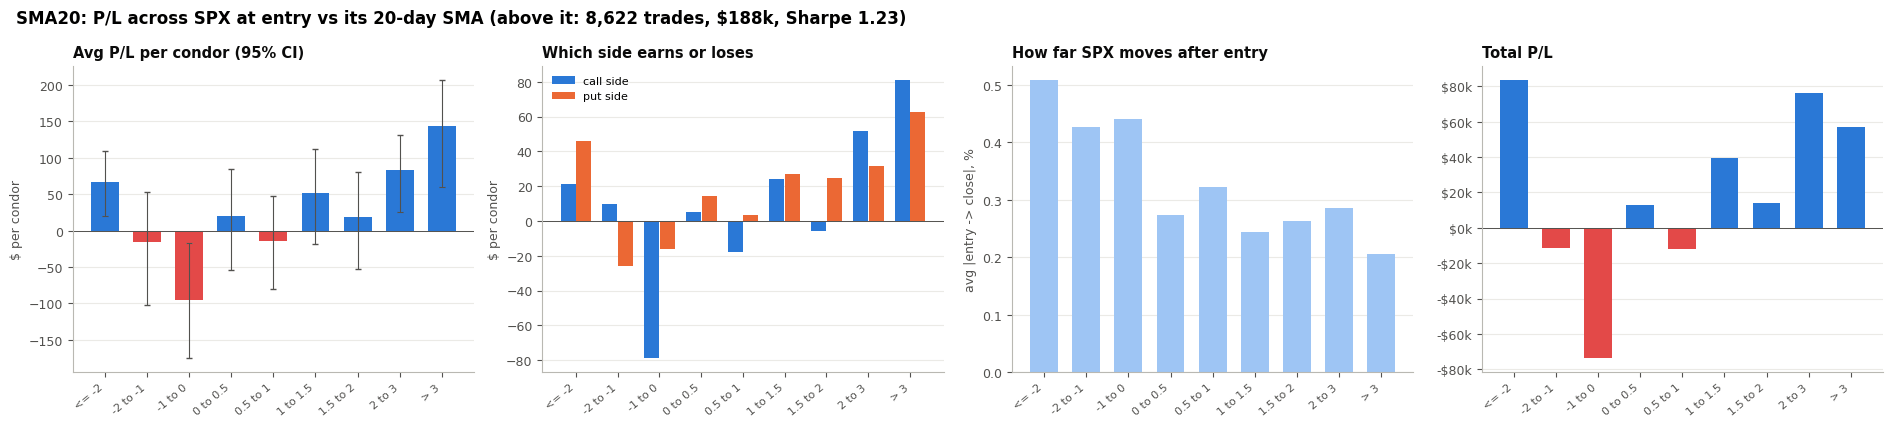

,condors,trades,sessions,avg_pl,ci_low,ci_high,win_rate,avg_pl_to_2024,avg_pl_from_2025,total_pl,avg_pl_call,avg_pl_put,call_breached_pct,put_breached_pct,abs_move_after_entry_pct,day_range_pct,in_strategy
bin,,,,,,,,,,,,,,,,,
<= -2,1247,2494,120,67.2,20.0,109.1,78.8,82.3,28.0,83759.6,21.3,45.9,16.2,13.6,0.5,1.5,False
-2 to -1,710,1420,93,-16.2,-101.6,52.8,68.6,-54.8,45.1,-11524.8,9.8,-26.1,21.4,21.5,0.4,1.2,False
-1 to 0,777,1554,102,-94.8,-175.1,-16.5,57.5,-65.8,-144.7,-73683.8,-78.8,-16.0,31.8,20.3,0.4,1.0,False
0 to 0.5,656,1312,103,19.5,-53.6,84.1,65.5,28.4,3.3,12795.7,4.9,14.6,30.3,21.0,0.3,0.8,False
0.5 to 1,811,1622,141,-14.5,-79.5,48.1,63.3,-27.8,4.5,-11732.7,-17.8,3.3,29.7,22.2,0.3,0.8,False
1 to 1.5,779,1558,109,51.0,-17.7,112.5,70.2,-2.9,137.6,39729.5,24.1,26.9,26.1,20.2,0.2,0.7,False
1.5 to 2,753,1506,122,18.7,-52.3,81.1,64.8,1.5,59.3,14084.4,-5.7,24.5,29.3,21.0,0.3,0.6,False
2 to 3,914,1828,114,83.5,26.2,131.4,73.9,103.0,20.5,76333.7,51.8,31.7,25.7,20.4,0.3,0.7,False
> 3,398,796,49,143.5,59.3,207.2,81.9,195.0,59.2,57111.8,81.1,62.3,16.1,15.8,0.2,0.7,False


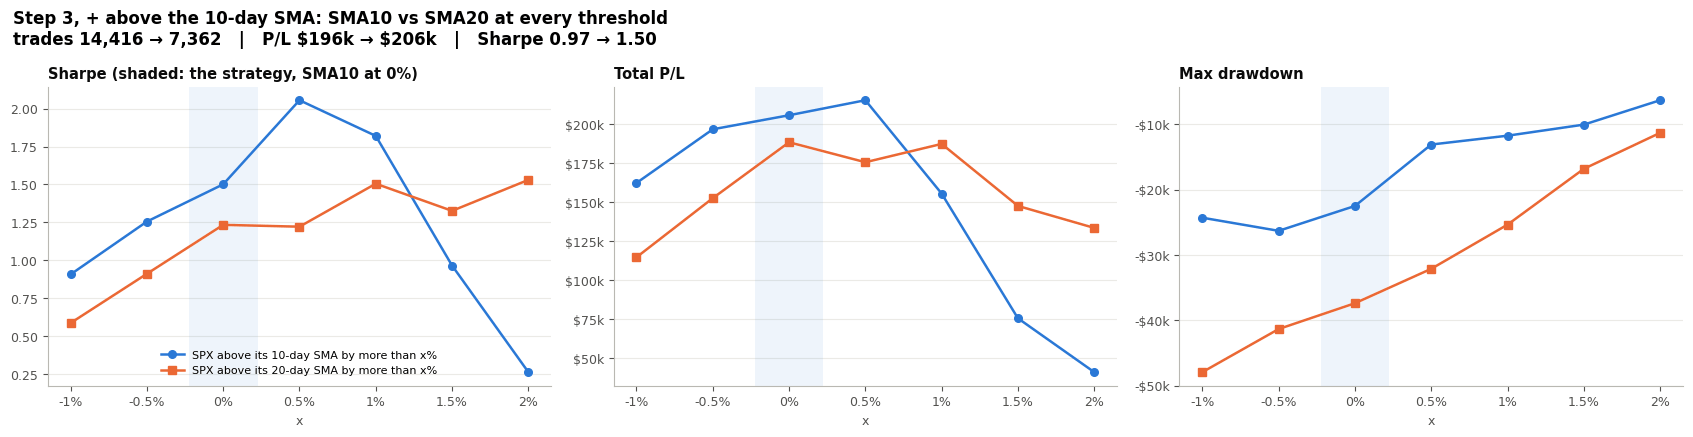

SMA10                                                                            SMA20                                                                        
     sessions   trades   total_pl sharpe max_drawdown sharpe_to_2024 sharpe_from_2025 sessions   trades   total_pl sharpe max_drawdown sharpe_to_2024 sharpe_from_2025
-1      535.0  10830.0  162223.80   0.91    -24304.16           0.78             1.20    493.0  10176.0  114638.56   0.59    -47938.12           0.67             0.41
-0.5    479.0   9346.0  196631.76   1.26    -26311.64           1.28             1.21    468.0   9426.0  152496.56   0.91    -41343.12           0.90             0.94
0       404.0   7362.0  205624.72   1.50    -22504.00           1.54             1.43    437.0   8622.0  188322.32   1.23    -37390.80           1.12             1.50
0.5     291.0   5006.0  215248.36   2.06    -13105.32           2.19             1.78    382.0   7310.0  175526.60   1.22    -32126.84           1.03             1.70
1       182.0   2984.0  155421.04   1.82    -11751.40           2.30             0.77    296.0   5688.0  187259.28   1.51    -25365.64           1.34             1.96
1.5      93.0   1494.0   75528.64   0.97    -10057.40           1.52            -0.12    229.0   4130.0  147529.80   1.33    -16824.08           1.61             0.64
2        48.0    798.0   41046.88   0.26     -6322.08           0.45            -0.05    153.0   2624.0  133445.44   1.53    -11317.16           2.14             0.14
off     656.0  14416.0  195906.96   0.97    -33625.72           1.05             0.80    656.0  14416.0  195906.96   0.97    -33625.72           1.05             0.80

In [15]:
s20 = casc.sma_sweeps["SMA20"].loc["0"]
fv.fig_profile(casc.profiles["sma20"], "spx_vs_sma20_pct",
               note=f"SMA20: P/L across SPX at entry vs its 20-day SMA (above it: {int(s20['trades']):,} trades, "
                    f"{fv._k(s20['total_pl'])}, Sharpe {s20['sharpe']:.2f})".replace("$", r"\$")); plt.show()
display(casc.profiles["sma20"].round(1))
cs.fig_sma_sweeps(casc.sma_sweeps, cs.note(ct, "sma10", "SMA10 vs SMA20 at every threshold")); plt.show()
display(pd.concat(casc.sma_sweeps, axis=1).round(2))

| SPX at entry vs its SMA20 | trades | avg P/L | call side | put side | total P/L |
|---|---|---|---|---|---|
| below -2% | 2,494 | +$67 | +$21 | +$46 | +$83.8k |
| -2% to -1% | 1,420 | -$16 | +$10 | -$26 | -$11.5k |
| **-1% to 0%** | 1,554 | **-$95** | **-$79** | -$16 | **-$73.7k** |
| 0% to +0.5% | 1,312 | +$20 | +$5 | +$15 | +$12.8k |
| +0.5% to +1% | 1,622 | -$14 | -$18 | +$3 | -$11.7k |
| +1% to +2% | 3,064 | +$19 to +$51 | | | +$53.8k |
| above +2% | 2,624 | +$84 to +$144 | | | +$133.4k |

| SPX above its SMA by more than | SMA10: trades | Sharpe | P/L | max DD | SMA20: trades | Sharpe | P/L | max DD |
|---|---|---|---|---|---|---|---|---|
| -1% | 10,830 | 0.91 | $162.2k | -$24.3k | 10,176 | 0.59 | $114.6k | -$47.9k |
| -0.5% | 9,346 | 1.26 | $196.6k | -$26.3k | 9,426 | 0.91 | $152.5k | -$41.3k |
| **0%** | **7,362** | **1.50** | **$205.6k** | -$22.5k | 8,622 | 1.23 | $188.3k | -$37.4k |
| +0.5% | 5,006 | **2.06** | **$215.2k** | -$13.1k | 7,310 | 1.22 | $175.5k | -$32.1k |
| +1% | 2,984 | 1.82 | $155.4k | -$11.8k | 5,688 | 1.51 | $187.3k | -$25.4k |
| +1.5% | 1,494 | 0.97 | $75.5k | -$10.1k | 4,130 | 1.33 | $147.5k | -$16.8k |
| no trend rule | 14,416 | 0.97 | $195.9k | -$33.6k | | | | |

- **The 20-day's loss zone is the 1% just below it** (-$95 a condor, -$73.7k), and its +0.5% to +1% band loses too.
- **At this step the 10-day scores higher at every threshold up to +1%**, with less than two-thirds of the 20-day's drawdown; the 20-day only
  wins far above the line (+1.5%), where the 10-day keeps few trades.
- **This is before the band, the tranches and the ratio cap.** With every setting on the 10-day wins in every year: Section 13.

## 6. Step 4: the VIX9D/VIX band, on the book after steps 1-3

**VIX9D / VIX measures how stressed the next week is against the next month**, at the minute each condor enters. Below 1 the curve is in
contango; near or above 1 it is flat or inverted, which is what it does in a selloff.

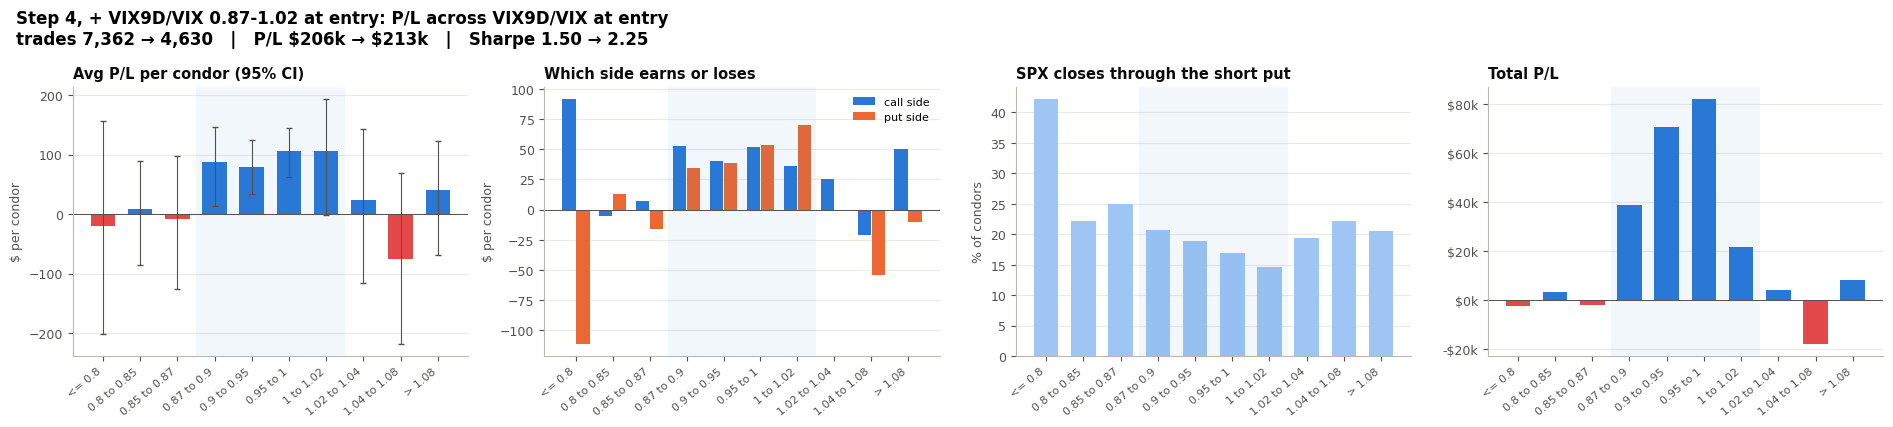

,condors,trades,sessions,avg_pl,ci_low,ci_high,win_rate,avg_pl_to_2024,avg_pl_from_2025,total_pl,avg_pl_call,avg_pl_put,call_breached_pct,put_breached_pct,abs_move_after_entry_pct,day_range_pct,in_strategy
bin,,,,,,,,,,,,,,,,,
<= 0.8,133,266,22,-19.5,-201.6,156.1,59.4,-90.9,23.5,-2597.0,91.9,-111.4,18.8,42.1,0.2,0.5,False
0.8 to 0.85,389,778,58,8.0,-85.2,89.6,64.0,26.3,-9.6,3117.7,-5.0,13.0,35.5,22.1,0.2,0.6,False
0.85 to 0.87,232,464,59,-9.0,-126.6,97.9,62.1,-56.5,66.0,-2080.2,7.1,-16.1,28.4,25.0,0.2,0.6,False
0.87 to 0.9,443,886,85,87.3,12.9,145.7,71.8,140.9,35.0,38682.2,52.8,34.5,24.6,20.8,0.2,0.6,True
0.9 to 0.95,889,1778,156,79.4,33.1,124.1,71.4,72.5,91.6,70546.7,40.5,38.8,26.7,18.9,0.2,0.6,True
0.95 to 1,778,1556,123,105.7,61.7,144.7,76.5,95.6,132.7,82245.4,52.0,53.8,21.1,16.8,0.2,0.8,True
1 to 1.02,205,410,54,106.4,-2.3,193.6,80.0,98.3,153.2,21804.6,35.9,70.5,22.0,14.6,0.4,1.0,True
1.02 to 1.04,171,342,38,24.4,-115.6,143.5,69.0,11.6,78.1,4173.5,25.1,-0.7,20.5,19.3,0.3,0.9,False
1.04 to 1.08,239,478,48,-74.9,-218.1,69.2,61.1,-0.6,-265.6,-17895.3,-20.8,-54.1,24.3,22.2,0.4,1.0,False


In [16]:
fv.fig_profile(casc.profiles["band"], fv.TS_9D_30, note=cs.note(ct, "band", "P/L across VIX9D/VIX at entry")); plt.show()
display(casc.profiles["band"].round(1))

| VIX9D / VIX at entry | trades | avg P/L | call side | put side | SPX through the short put | total P/L |
|---|---|---|---|---|---|---|
| <= 0.80 | 266 | -$20 | +$92 | **-$111** | **42%** | -$2.6k |
| 0.80-0.87 | 1,242 | -$9 to +$8 | -$5 to +$7 | -$16 to +$13 | 22-25% | +$1.0k |
| **0.87-0.90** | 886 | **+$87** | +$53 | +$35 | 21% | +$38.7k |
| **0.90-0.95** | 1,778 | **+$79** | +$41 | +$39 | 19% | +$70.5k |
| **0.95-1.00** | 1,556 | **+$106** | +$52 | +$54 | 17% | **+$82.2k** |
| **1.00-1.02** | 410 | **+$106** | +$36 | +$71 | 15% | +$21.8k |
| 1.02-1.04 | 342 | +$24 | +$25 | -$1 | 19% | +$4.2k |
| 1.04-1.08 | 478 | **-$75** | -$21 | **-$54** | 22% | **-$17.9k** |
| above 1.08 | 398 | +$41 | +$51 | -$10 | 21% | +$8.1k |

- **Inside the band every group earns** (+$79 to +$106 a condor), $213.3k in all; outside it the condors lose $7.2k.
- **Both tails lose on the put side.** Below 0.80 SPX breaks the short put on 42% of condors (a calm curve that breaks); just past the cap
  (1.04-1.08) the put side loses $54 a condor, and the group loses $266 a condor in 2025-26. Above 1.08 the curve is in full stress: SPX
  moves 0.66% after entry on 1.5% days.
- **On the raw book the band did nothing** (step 1 of the greedy search: -0.11): its losing groups were hidden among Thursdays, rally
  entries and below-trend markets. Once those are gone it adds +0.75 Sharpe, the most of any step.

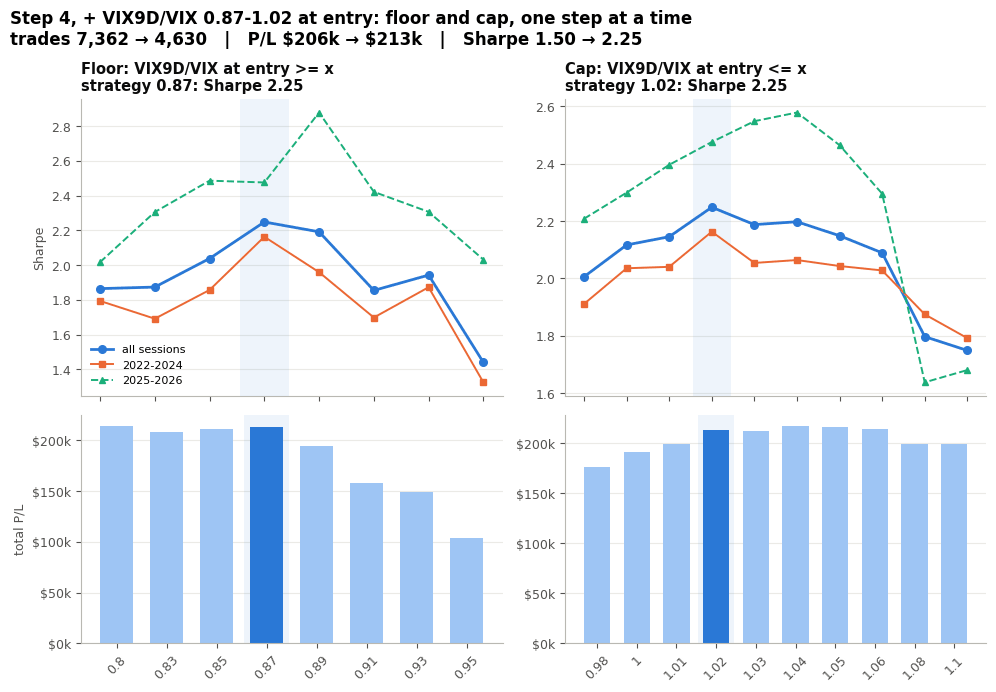

,sessions,trades,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025
ts_low,,,,,,,
0.8,343.0,5872.0,214316.32,1.86,-14130.12,1.79,2.02
0.83,331.0,5482.0,207863.92,1.87,-16273.96,1.69,2.31
0.85,315.0,5094.0,211198.64,2.04,-17007.32,1.86,2.49
0.87,294.0,4630.0,213278.80,2.25,-15130.04,2.16,2.48
0.89,267.0,4016.0,194393.96,2.19,-12802.16,1.96,2.88
0.91,241.0,3384.0,157541.04,1.85,-14611.96,1.70,2.42
0.93,192.0,2724.0,149398.44,1.94,-12457.60,1.87,2.31
0.95,149.0,1966.0,104049.96,1.44,-12738.72,1.33,2.03
off,350.0,6138.0,211719.28,1.76,-14619.20,1.70,1.87


,sessions,trades,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025
ts_high,,,,,,,
0.98,238.0,3740.0,176307.40,2.01,-15291.76,1.91,2.21
1,268.0,4220.0,191474.20,2.12,-16004.24,2.04,2.30
1.01,278.0,4406.0,199453.36,2.15,-15203.52,2.04,2.40
1.02,294.0,4630.0,213278.80,2.25,-15130.04,2.16,2.48
1.03,300.0,4826.0,212412.56,2.19,-13764.08,2.05,2.55
1.04,304.0,4972.0,217452.32,2.20,-13391.84,2.06,2.58
1.05,311.0,5086.0,216688.16,2.15,-16772.84,2.04,2.46
1.06,319.0,5192.0,214305.52,2.09,-17570.00,2.03,2.30
1.08,332.0,5450.0,199557.00,1.80,-23348.80,1.88,1.64


In [17]:
fv.fig_sweeps({"ts_low": casc.sweeps["ts_low"], "ts_high": casc.sweeps["ts_high"]},
              title=cs.note(ct, "band", "floor and cap, one step at a time")); plt.show()
display(casc.sweeps["ts_low"].drop(columns="is_strategy").round(2))
display(casc.sweeps["ts_high"].drop(columns="is_strategy").round(2))

| floor | trades | Sharpe | | cap | trades | Sharpe |
|---|---|---|---|---|---|---|
| 0.85 | 5,094 | 2.04 | | 1.00 | 4,220 | 2.12 |
| **0.87 (strategy)** | **4,630** | **2.25** | | 1.01 | 4,406 | 2.15 |
| 0.89 | 4,016 | 2.19 | | **1.02 (strategy)** | **4,630** | **2.25** |
| 0.91 | 3,384 | 1.85 | | 1.03 | 4,826 | 2.19 |
| no floor | 6,138 | 1.76 | | 1.04 | 4,972 | 2.20 |
| | | | | no cap | 5,848 | 1.81 |

- **Both edges are at the top of their sweeps** at this step: 0.87 and 1.02.
- **In 2025-26 a slightly wider cap scores higher** (1.04: 2.58 against 2.48), and so does a 0.89 floor (2.88): the band's edges are
  sharpest in 2022-24.

## 7. Step 5: the tranches, on the book after steps 1-4

The book so far trades all 20 entry times. This step keeps the strategy's **7 tranches: 11:33, 11:53, 12:13, 13:13, 13:53, 14:13 and
14:53**. They are the first seven tranches forward selection adds on this book (below). First, each tranche on this book and how
correlated they are.

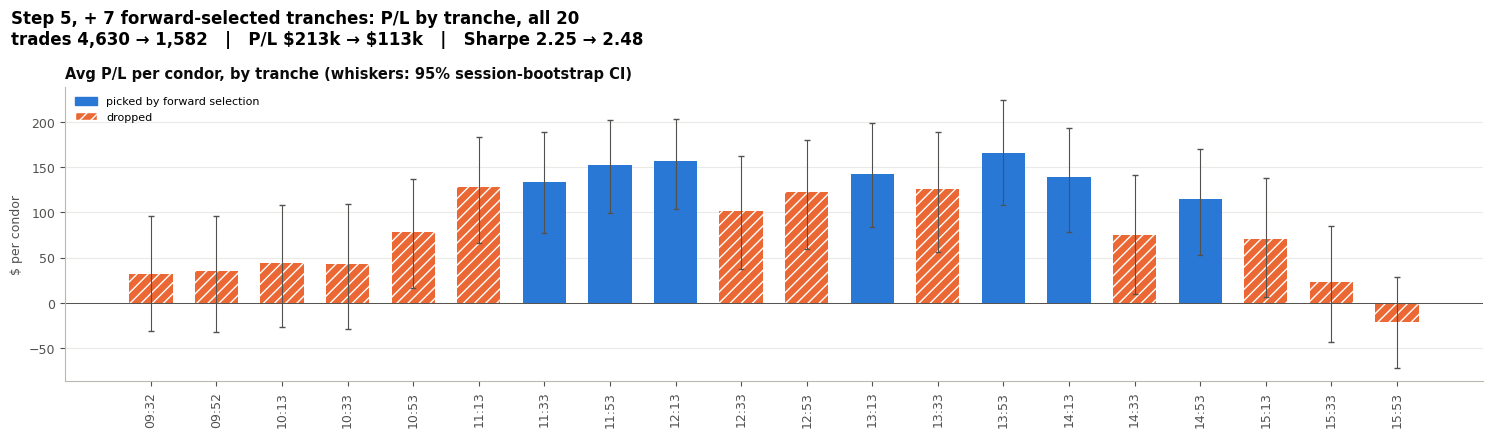

,condors,trades,avg_pl,ci_low,ci_high,total_pl,sharpe_if_dropped,status
entry_time,,,,,,,,
09:32,139,278,31.85,-31.26,96.27,4427.68,0.04,dropped
09:52,131,262,34.85,-31.65,95.74,4565.72,0.04,dropped
10:13,112,224,43.86,-26.94,108.33,4912.44,0.05,dropped
10:33,122,244,43.01,-29.20,109.34,5246.64,0.07,dropped
10:53,131,262,78.01,16.48,136.45,10218.72,0.00,dropped
11:13,115,230,128.06,65.88,183.16,14726.80,-0.06,dropped
11:33,122,244,133.44,77.09,188.55,16279.64,-0.09,traded
11:53,119,238,151.93,99.79,202.39,18079.28,-0.10,traded
12:13,110,220,156.40,103.37,203.10,17204.20,-0.09,traded


In [18]:
cs.fig_tranches(casc.tranches, note=cs.note(ct, "tranches", "P/L by tranche, all 20")); plt.show()
display(fv.highlight_dropped(casc.tranches, 2))

- **The strategy keeps six of the seven best earners:** 13:53 (+$166 a condor), 12:13 (+$156), 11:53 (+$152), 13:13 (+$142), 14:13 (+$139)
  and 11:33 (+$133), plus 14:53 (+$114). 11:13, 13:33 and 12:53 earn a little more than 14:53 (+$122-128), but forward selection adds 14:53
  first: it adds more to the book's Sharpe.
- **The first hour earns the least:** 09:32-10:33 make $32-44 a condor. The last two are weak (15:33 +$23, 15:53 -$21).

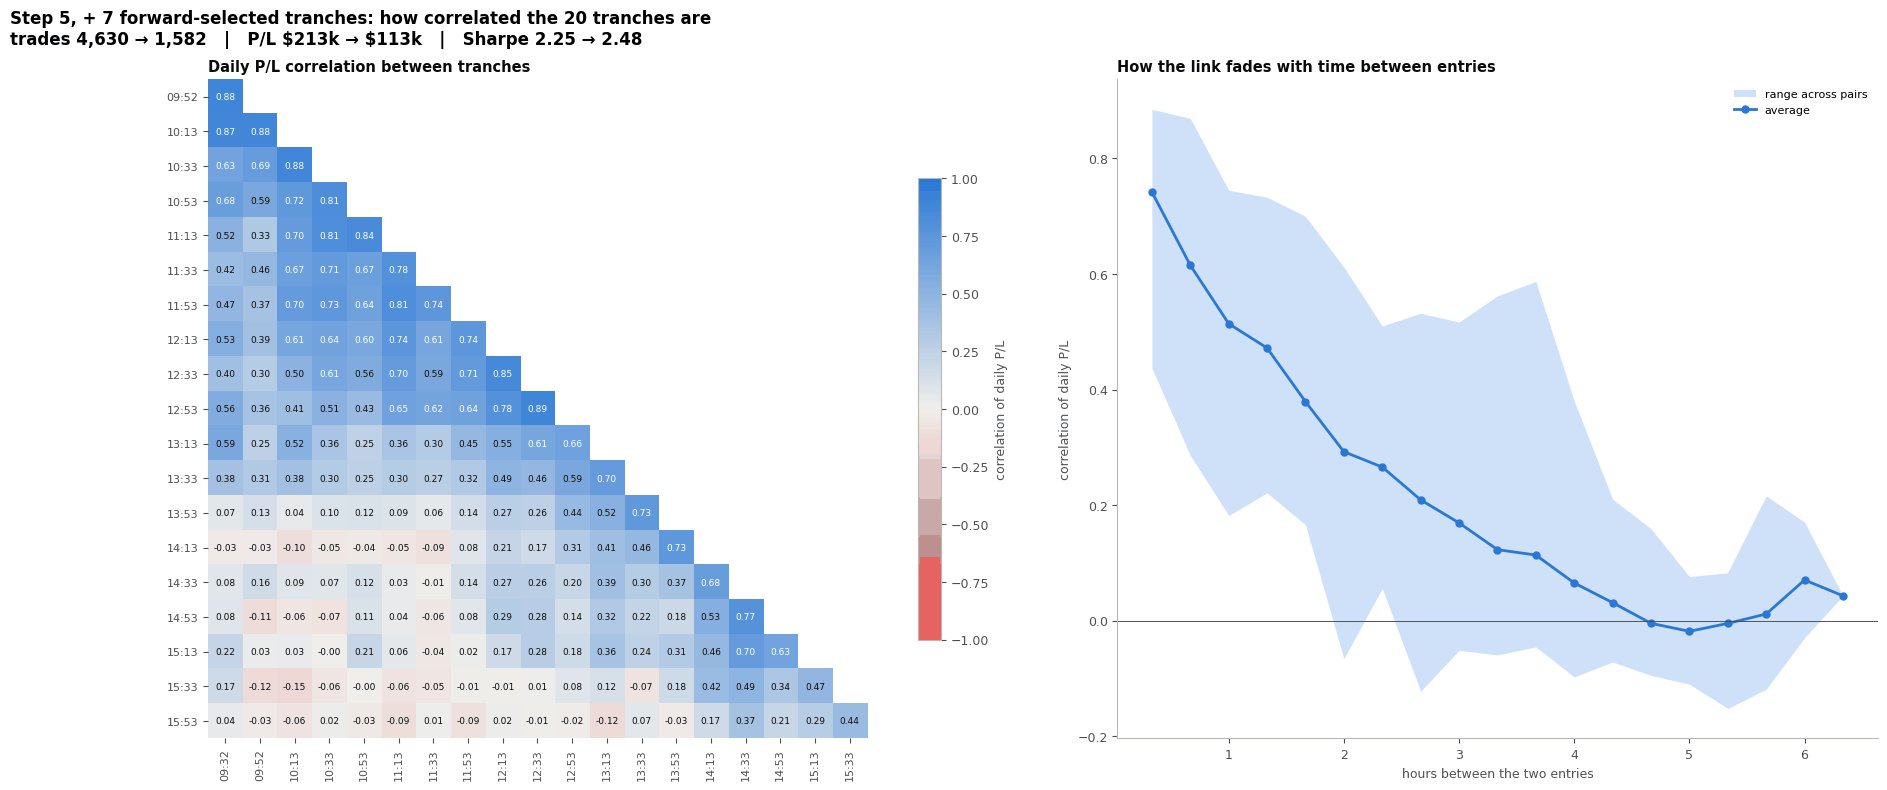

20 tranches, average pairwise correlation 0.33 -> about 2.8 independent bets a day; 24 pairs above 0.7


,from,to,tranches,members,avg_rho_inside
block,,,,,
1,09:32,10:33,4,"09:32, 09:52, 10:13, 10:33",0.80
2,10:53,12:53,7,"10:53, 11:13, 11:33, 11:53, 12:13, 12:33, 12:53",0.70
3,13:13,13:33,2,"13:13, 13:33",0.70
4,13:53,14:13,2,"13:53, 14:13",0.73
5,14:33,15:13,3,"14:33, 14:53, 15:13",0.70
6,15:33,15:33,1,15:33,NaN
7,15:53,15:53,1,15:53,NaN


,mean,median,min,max,pairs
gap_minutes,,,,,
20,0.74,0.74,0.44,0.89,19
40,0.61,0.64,0.29,0.87,18
60,0.51,0.55,0.18,0.74,17
80,0.47,0.44,0.22,0.73,16
100,0.38,0.32,0.17,0.70,15
120,0.29,0.31,-0.07,0.61,14
140,0.27,0.27,0.06,0.51,13
160,0.21,0.26,-0.12,0.53,12
180,0.17,0.12,-0.05,0.52,11


In [19]:
corr = casc.tranche_corr
fv.fig_tranche_corr(corr, fv.tranche_corr_by_gap(corr), note=cs.note(ct, "tranches", "how correlated the 20 tranches are")); plt.show()
t = fv.tranche_summary(corr)
print(f"{t['tranches']} tranches, average pairwise correlation {t['avg_pairwise_rho']:.2f} -> "
      f"about {t['effective_independent_tranches']:.1f} independent bets a day; {t['pairs_above_0.7']} pairs above 0.7")
display(fv.tranche_blocks(corr).round(2))
display(fv.tranche_corr_by_gap(corr).round(2))

**Neighbouring tranches are close to the same trade.** Entries 20 minutes apart correlate 0.74 on average; 1 hour apart 0.51, 2 hours
0.29, 3 hours 0.17, 4 hours 0.07. The 20 tranches are about **2.8 independent bets a day** (average pairwise correlation 0.33). The 7 are
spread from 11:33 to 14:53, never more than an hour apart, so they share most of each day's risk: what they give up against all 20 is
mostly the first and the last hour, the weakest tranches.

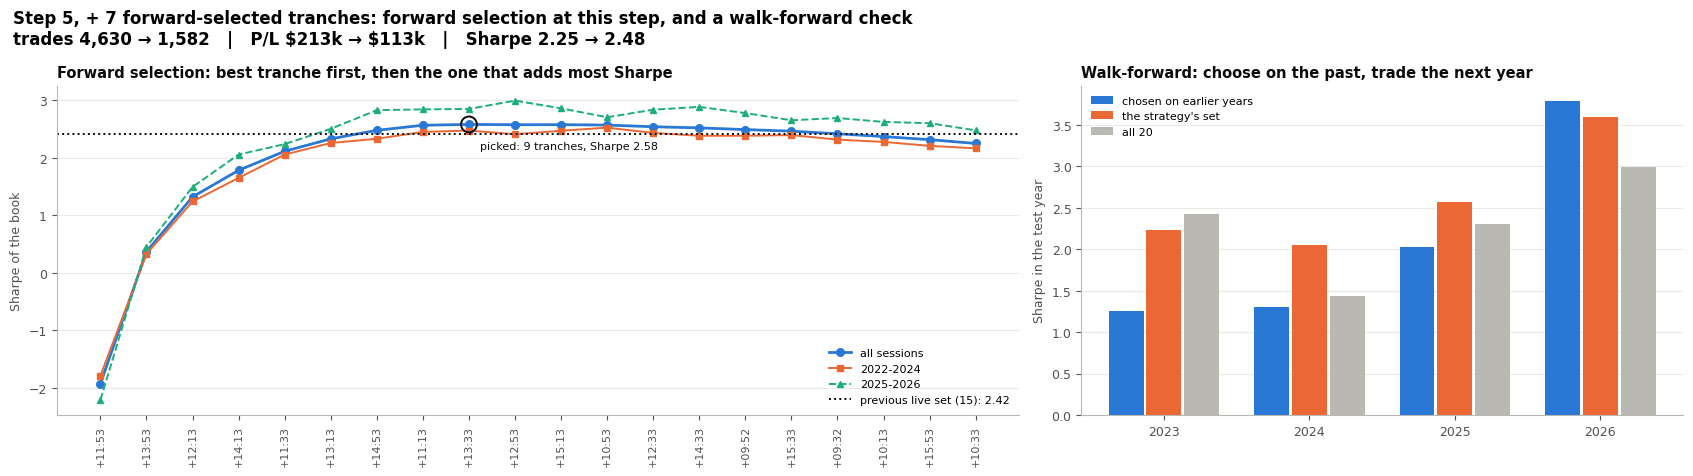

forward selection on this book peaks at: 11:13, 11:33, 11:53, 12:13, 13:13, 13:33, 13:53, 14:13, 14:53
every step: the book's Sharpe if each remaining tranche were added (the one picked is highlighted)


,picked,09:32,09:52,10:13,10:33,10:53,11:13,11:33,11:53,12:13,12:33,12:53,13:13,13:33,13:53,14:13,14:33,14:53,15:13,15:33,15:53
step,,,,,,,,,,,,,,,,,,,,,
1,11:53,-2.98,-3.15,-3.44,-3.15,-2.60,-2.32,-2.03,-1.93,-2.24,-2.71,-2.19,-2.10,-2.30,-2.02,-2.27,-3.05,-2.82,-3.35,-4.39,-5.91
2,13:53,-0.73,-0.74,-0.72,-0.64,-0.26,0.09,0.20,,0.29,-0.15,0.07,0.23,0.02,0.37,0.17,-0.48,-0.13,-0.58,-1.13,-1.76
3,12:13,0.54,0.56,0.59,0.58,0.88,1.15,1.24,,1.32,0.97,1.09,1.25,1.05,,1.20,0.81,1.12,0.79,0.47,0.14
4,14:13,1.28,1.30,1.31,1.26,1.50,1.70,1.76,,,1.53,1.62,1.78,1.61,,1.78,1.49,1.74,1.51,1.30,1.10
5,11:33,1.72,1.73,1.75,1.70,1.90,2.05,2.11,,,1.89,1.95,2.08,1.93,,,1.81,2.03,1.86,1.71,1.59
6,13:13,2.03,2.03,2.04,1.97,2.13,2.25,,,,2.15,2.19,2.33,2.20,,,2.12,2.31,2.17,2.05,1.95
7,14:53,2.24,2.25,2.25,2.19,2.34,2.43,,,,2.32,2.35,,2.35,,,2.32,2.48,2.36,2.27,2.20
8,11:13,2.39,2.40,2.40,2.36,2.48,2.56,,,,2.46,2.49,,2.49,,,2.41,,2.45,2.40,2.35
9,13:33,2.48,2.50,2.48,2.43,2.53,,,,,2.53,2.56,,2.58,,,2.51,,2.55,2.51,2.46


,added,tranches,condors,trades,total_pl,sharpe,sharpe_to_2024,sharpe_from_2025,max_drawdown,win_rate_spread,win_rate_condor,avg_pl_condor
step,,,,,,,,,,,,
1,11:53,1,119,238,18079.28,-1.93,-1.79,-2.21,-2052.68,89.08,84.03,151.93
2,13:53,2,226,452,35815.12,0.37,0.33,0.45,-2378.04,87.39,82.30,158.47
3,12:13,3,336,672,53019.32,1.32,1.24,1.49,-3965.36,87.20,81.85,157.80
4,14:13,4,447,894,68493.64,1.78,1.65,2.05,-4037.84,86.24,80.76,153.23
5,11:33,5,569,1138,84773.28,2.11,2.05,2.24,-4817.12,86.82,81.20,148.99
6,13:13,6,684,1368,101142.08,2.33,2.25,2.50,-5515.52,86.70,80.70,147.87
7,14:53,7,791,1582,113370.92,2.48,2.33,2.83,-4888.92,85.65,79.14,143.33
8,11:13,8,906,1812,128097.72,2.56,2.45,2.84,-5252.32,86.20,79.47,141.39
9,13:33,9,1016,2032,141923.92,2.58,2.47,2.85,-8413.48,86.17,79.23,139.69


,train,tranches_selected,dropped_by_selection,selected_sharpe,live_sharpe,all20_sharpe,selected_pl,live_pl,all20_pl
test_year,,,,,,,,,
2023,2022-05 to 2022,11.0,"09:32, 10:13, 10:33, 10:53, 11:13, 11:33, 11:5...",1.25,2.24,2.43,24240.60,27291.64,56324.20
2024,2022-05 to 2023,13.0,"09:32, 10:33, 10:53, 12:53, 13:53, 14:33, 15:53",1.31,2.05,1.44,27810.76,25997.60,39950.48
2025,2022-05 to 2024,12.0,"09:32, 09:52, 10:13, 10:33, 12:33, 12:53, 14:3...",2.03,2.57,2.31,31527.00,27280.52,49777.28
2026,2022-05 to 2025,12.0,"09:32, 09:52, 10:13, 10:33, 12:33, 14:33, 15:3...",3.78,3.59,3.00,17551.44,11734.36,20006.92
out of sample,expanding,NaN,-,1.69,2.39,2.11,101129.80,92304.12,166058.88


chosen-each-year vs all 20, out of sample: Sharpe difference 95% interval -0.79 to -0.04; better in 2% of resamples


In [20]:
fwd, wf = casc.selection, casc.walk_forward
cs.fig_walk_forward(fwd, wf, note=cs.note(ct, "tranches", "forward selection at this step, and a walk-forward check")); plt.show()
print(f"forward selection on this book peaks at: {', '.join(sorted(fwd.attrs['best']))}")
print("every step: the book's Sharpe if each remaining tranche were added (the one picked is highlighted)")
display(fv.forward_trials_view(fwd))
display(fwd.round(2))
display(wf.round(2))
print(f"chosen-each-year vs all 20, out of sample: Sharpe difference 95% interval "
      f"{wf.attrs['selected_vs_all20_ci'][0]:+.2f} to {wf.attrs['selected_vs_all20_ci'][1]:+.2f}; "
      f"better in {wf.attrs['p_selected_better']:.0%} of resamples")

**Forward selection on this book:** it starts with 11:53 (the best tranche alone), then adds 13:53, 12:13, 14:13, 11:33, 13:13 and 14:53:
**the strategy's 7, in that order** (Sharpe 2.48 at step 7). It goes on to 11:13 (2.56) and 13:33, where it peaks (2.58, 9 tranches), is
flat to 12 tranches and falls after.

**Walk-forward:** for each year from 2023, the selection is re-run on every earlier year only and its pick traded in the next year.

| test year | tranches chosen | chosen on earlier years | the strategy's 7 | all 20 |
|---|---|---|---|---|
| 2023 | 11 | 1.25 ($24.2k) | 2.24 ($27.3k) | 2.43 ($56.3k) |
| 2024 | 13 | 1.31 ($27.8k) | 2.05 ($26.0k) | 1.44 ($40.0k) |
| 2025 | 12 | 2.03 ($31.5k) | 2.57 ($27.3k) | 2.31 ($49.8k) |
| 2026 | 12 | 3.78 ($17.6k) | 3.59 ($11.7k) | 3.00 ($20.0k) |
| **2023-26** | | **1.69 ($101.1k)** | **2.39 ($92.3k)** | 2.11 ($166.1k) |

- **Re-chosen each year, the selection does worse than trading all 20** (1.69 against 2.11 out of sample; better in only 2% of resamples):
  with little history it keeps too few tranches, and not always the right ones.
- **The strategy's 7 score 2.39 over the same years**, ahead of all 20 (2.11), but that set was chosen on all the data, so part of its edge
  is hindsight. It makes $92.3k against all 20's $166.1k.
- **What holds every year is the first hour:** every walk-forward pick drops 09:32 and 10:33, and three of four drop 10:13.

**Forward selection by drawdown, on its own terms.** A separate search that takes nothing from the strategy's tranche set: **every other
setting on (the ratio cap included), all 20 tranches available**. It starts with the tranche whose own **P/L per $ of max drawdown** is
highest, then adds the tranche that raises the book's P/L per $ of drawdown most, until all 20 are in, and keeps the set where that ratio
peaks. (Minimising the drawdown alone would just pick the tranches that barely trade.)

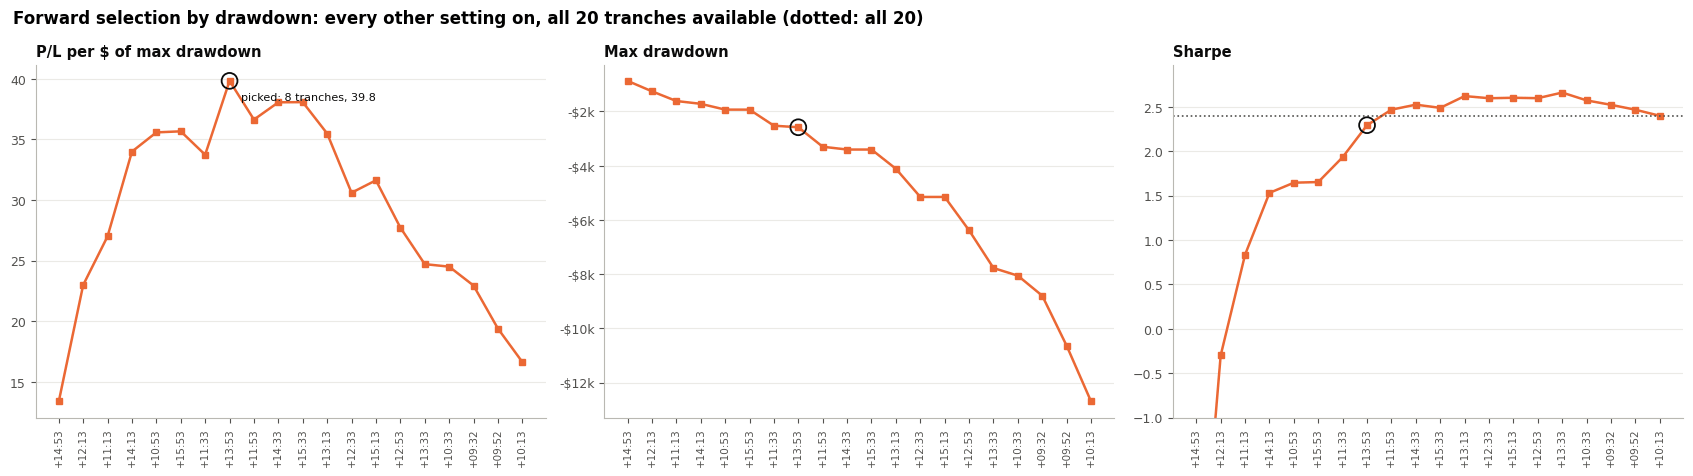

forward selection by drawdown peaks at: 10:53, 11:13, 11:33, 12:13, 13:53, 14:13, 14:53, 15:53
every step: the book's P/L per $ of drawdown if each remaining tranche were added


,09:32,09:52,10:13,10:33,10:53,11:13,11:33,11:53,12:13,12:33,12:53,13:13,13:33,13:53,14:13,14:33,14:53,15:13,15:33,15:53
step,,,,,,,,,,,,,,,,,,,,
1,1.4,1.9,1.4,2.0,6.8,12.3,8.8,8.8,9.6,4.4,8.3,9.5,6.8,11.1,9.8,6.1,13.4,3.7,0.0,NaN
2,4.6,5.8,7.1,7.0,11.9,15.8,20.1,16.8,23.0,8.9,12.5,14.0,12.7,13.4,14.6,9.6,NaN,8.8,12.7,13.6
3,9.4,13.9,13.5,15.5,21.7,27.0,22.8,20.5,NaN,14.3,16.9,18.5,17.3,17.4,23.6,17.8,NaN,17.0,19.2,23.1
4,13.5,18.1,16.9,18.3,22.8,NaN,24.5,22.3,NaN,20.8,20.3,24.7,20.2,31.9,34.0,17.4,NaN,16.8,27.0,27.1
5,17.5,25.2,23.3,23.8,35.6,NaN,31.3,26.6,NaN,26.4,25.5,30.5,26.7,32.3,NaN,21.5,NaN,21.1,34.0,34.1
6,17.6,24.1,23.4,20.3,NaN,NaN,33.7,29.9,NaN,28.3,30.9,31.6,30.3,31.5,NaN,28.7,NaN,27.9,31.6,35.7
7,17.6,24.1,23.5,20.4,NaN,NaN,33.7,29.9,NaN,28.3,30.9,31.6,30.3,31.6,NaN,28.8,NaN,27.9,31.7,NaN
8,22.6,24.8,24.3,20.9,NaN,NaN,NaN,31.3,NaN,30.4,29.3,31.6,26.8,39.8,NaN,30.5,NaN,24.3,26.3,NaN
9,23.7,29.3,28.7,24.4,NaN,NaN,NaN,36.6,NaN,35.9,34.6,35.8,31.1,NaN,NaN,36.6,NaN,28.2,30.7,NaN


,added,tranches,condors,trades,total_pl,sharpe,sharpe_to_2024,sharpe_from_2025,max_drawdown,avg_pl_condor,pl_per_dd
step,,,,,,,,,,,
1,14:53,1,67,134,11656.04,-3.58,-4.21,-2.36,-870.76,173.97,13.39
2,12:13,2,177,354,28860.24,-0.30,-0.69,0.55,-1255.52,163.05,22.99
3,11:13,3,292,584,43587.04,0.83,0.60,1.34,-1614.28,149.27,27.00
4,14:13,4,383,766,58368.96,1.53,1.26,2.09,-1717.44,152.40,33.99
5,10:53,5,513,1026,68705.56,1.65,1.58,1.78,-1931.64,133.93,35.57
6,15:53,6,514,1028,68872.68,1.65,1.59,1.78,-1931.64,133.99,35.66
7,11:33,7,636,1272,85152.32,1.93,1.95,1.89,-2524.92,133.89,33.72
8,13:53,8,737,1474,102826.44,2.29,2.28,2.31,-2582.60,139.52,39.82
9,11:53,9,856,1712,120905.72,2.47,2.46,2.49,-3301.32,141.24,36.62


In [21]:
sdd = casc.selection_dd
cs.fig_selection_dd(sdd, note="Forward selection by drawdown: every other setting on, all 20 tranches available (dotted: all 20)"); plt.show()
print(f"forward selection by drawdown peaks at: {', '.join(sorted(sdd.attrs['best']))}")
print("every step: the book's P/L per $ of drawdown if each remaining tranche were added")
display(sdd.attrs["trials"].round(1))
display(sdd.drop(columns=["win_rate_spread", "win_rate_condor"], errors="ignore").round(2))

**The drawdown path:**

| step | added | trades | P/L | Sharpe | max drawdown | P/L per $ of drawdown |
|---|---|---|---|---|---|---|
| 1 | 14:53 | 134 | $11.7k | | -$0.9k | 13.4 |
| 2 | 12:13 | 354 | $28.9k | | -$1.3k | 23.0 |
| 3 | 11:13 | 584 | $43.6k | 0.83 | -$1.6k | 27.0 |
| 4 | 14:13 | 766 | $58.4k | 1.53 | -$1.7k | 34.0 |
| 5 | 10:53 | 1,026 | $68.7k | 1.65 | -$1.9k | 35.6 |
| 6 | 15:53 | 1,028 | $68.9k | 1.65 | -$1.9k | 35.7 |
| 7 | 11:33 | 1,272 | $85.2k | 1.93 | -$2.5k | 33.7 |
| **8** | **13:53** | **1,474** | **$102.8k** | **2.29** | **-$2.6k** | **39.8** |
| 9 | 11:53 | 1,712 | $120.9k | 2.47 | -$3.3k | 36.6 |
| 12 | 13:13 | 2,156 | $145.9k | 2.62 | -$4.1k | 35.5 |
| 16 | 13:33 | 2,934 | $192.1k | 2.66 | -$7.8k | 24.7 |
| 20 | all | 3,940 | $211.4k | 2.40 | -$12.7k | 16.6 |

- **It peaks at 8 tranches: 10:53, 11:13, 11:33, 12:13, 13:53, 14:13, 14:53 and 15:53**, at $39.8 of P/L per $ of drawdown: 1,474 trades,
  $102.8k, Sharpe 2.29 (2.28 / 2.31 in the two halves), drawdown -$2.6k.
- **15:53 is a passenger:** with the ratio cap on it trades twice in four years, so it neither helps nor hurts; the working set is the
  other seven.
- **Past the peak, each tranche adds more drawdown than profit:** 11:53 and 13:13 still raise Sharpe (to 2.62 at 12) but deepen the
  drawdown to -$4.1k; from 13 tranches on the drawdown grows fast (-$5.2k to -$12.7k).
- **Drawdown and Sharpe point to different sizes:** the ratio peaks at 8 tranches with Sharpe 2.29; Sharpe keeps rising to 2.66 at 16
  tranches, where the drawdown is three times as deep.

**Your 7 against the other sets, with every other setting on** (the finished strategy, only the tranches changed):

In [22]:
display(casc.tranche_sets.drop(columns="tranches").astype(float).round(2))

,trades,total_pl,sharpe,sharpe_to_2024,sharpe_from_2025,max_drawdown,pl_per_dd
the strategy's 7,1450.0,112044.00,2.60,2.44,2.92,-3808.68,29.42
forward selection's peak (9),1892.0,141864.52,2.73,2.64,2.93,-5975.20,23.74
forward selection by drawdown (8),1474.0,102826.44,2.29,2.28,2.31,-2582.60,39.82
previous live set (15),2704.0,180418.24,2.69,2.64,2.82,-6545.16,27.57
all 20,3940.0,211370.40,2.40,2.30,2.61,-12700.72,16.64


| tranche set (everything else on) | trades | total P/L | Sharpe | 2022-24 / 2025-26 | max drawdown | P/L per $ of drawdown |
|---|---|---|---|---|---|---|
| **the strategy's 7** | **1,450** | $112.0k | 2.60 | 2.44 / 2.92 | -$3.8k | 29.4 |
| forward selection's peak (the 7 + 11:13, 13:33) | 1,892 | $141.9k | **2.73** | 2.64 / 2.93 | -$6.0k | 23.7 |
| forward selection by drawdown (8) | 1,474 | $102.8k | 2.29 | 2.28 / 2.31 | **-$2.6k** | **39.8** |
| previous live set (15) | 2,704 | $180.4k | 2.69 | 2.64 / 2.82 | -$6.5k | 27.6 |
| all 20 | 3,940 | **$211.4k** | 2.40 | 2.30 / 2.61 | -$12.7k | 16.6 |

- **The drawdown pick has the smallest drawdown (-$2.6k) and the most P/L per $ of drawdown (39.8)**, but the lowest Sharpe here (2.29)
  and the weakest 2025-26 (2.31).
- **The 7 come next on drawdown (-$3.8k, 29.4)**, with the best 2025-26 Sharpe alongside the Sharpe pick.
- **They don't have the highest Sharpe:** adding 11:13 and 13:33 (the 9) scores 2.73 for $29.8k more, and the previous 15 score 2.69 for
  $68.4k more, each with a drawdown $2-3k deeper. Fewer tranches means fewer trading days, and every idle day pays the 4% hurdle.
- **The trade-off is size against depth:** the 7 are the smallest, steadiest book; the 9 and the 15 score a higher Sharpe but draw down
  further.

## 8. Step 6: the short/long ratio <= 4, on the book after steps 1-5

The backtester caps one short/long ratio for the whole condor: the two short strikes' prices over the two long strikes'.

,spearman_condor,ci_low,ci_high,spearman_session,pearson_condor,p60_ratio,spearman_below_p60,spearman_above_p60
whole condor,0.156,0.049,0.262,0.09,-0.11,2.651,0.507,-0.078


partial rank correlation with P/L, controlling for what the ratio moves with:


,whole condor
controlling for,
none,0.156
credit,-0.055
strike distance (both sides),0.044
entry time,0.149
VIX9D,0.167
"credit, VIX9D, entry time",-0.019


what the ratio moves with (rank correlation):


,whole condor
credit,0.89
otm_points_call,-0.95
otm_points_put,-0.96
mins_from_open,0.50
vix9d_open,-0.48
vvix_prev,-0.42


rank correlation with P/L by year:


,whole condor
date,
2022,0.576
2023,-0.006
2024,-0.012
2025,0.207
2026,0.586


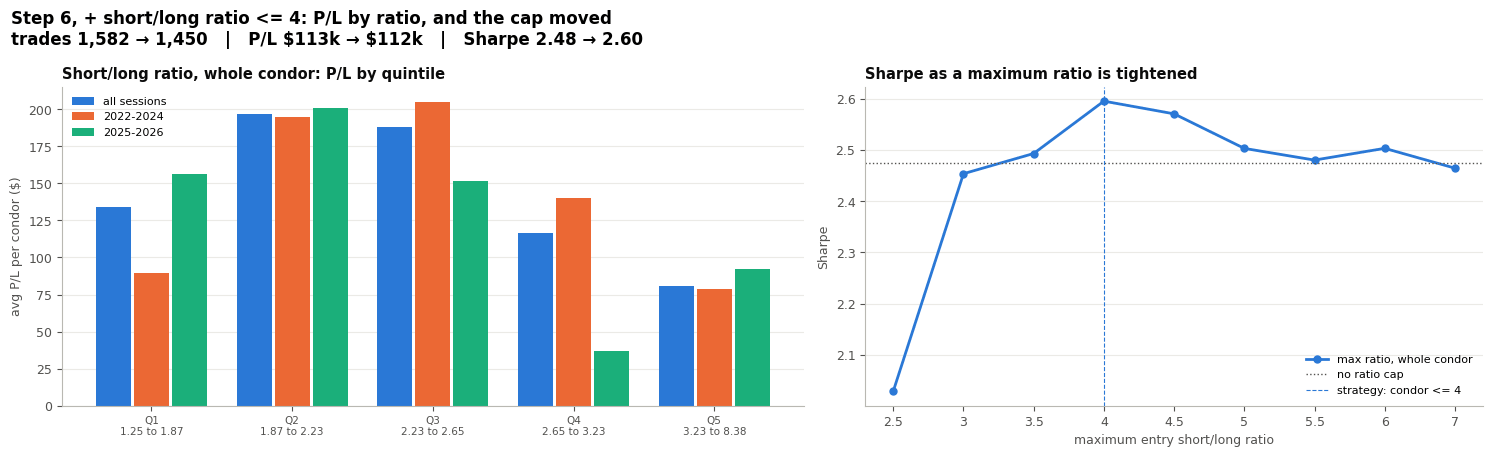

,side,quintile,range,condors,trades,sessions,win_rate,avg_pl,total_pl,avg_pl_to_2024,avg_pl_from_2025
0,whole condor,1,1.25 to 1.87,159,318,67,89.9,134.2,21345.1,89.3,156.1
1,whole condor,2,1.87 to 2.23,158,316,86,86.7,197.0,31123.0,195.0,200.8
2,whole condor,3,2.23 to 2.65,158,316,95,82.3,187.7,29660.0,205.0,151.5
3,whole condor,4,2.65 to 3.23,158,316,90,71.5,116.7,18437.0,140.2,37.1
4,whole condor,5,3.23 to 8.38,158,316,79,65.2,81.1,12806.0,78.8,92.5


kept_pct  trades   total_pl  sharpe  max_drawdown  sharpe_to_2024  sharpe_from_2025
side         max_ratio                                                                                     
whole condor 2.5           54.36     860   73415.60    2.03      -3012.16            1.62              2.72
             3             73.96    1170   94966.20    2.45      -2357.04            2.30              2.73
             3.5           85.34    1350  104427.00    2.49      -3271.64            2.33              2.82
             4             91.66    1450  112044.00    2.60      -3808.68            2.44              2.92
             4.5           94.94    1502  113803.12    2.57      -4716.16            2.45              2.84
             5             98.10    1552  112994.12    2.50      -5195.04            2.36              2.83
             5.5           98.74    1562  112785.72    2.48      -4888.92            2.33              2.83
             6             99.37    1572  113926.32    2.50      -4888.92            2.37              2.83
             7             99.87    1580  112947.80    2.46      -4888.92            2.31              2.83
             off          100.00    1582  113370.92    2.48      -4888.92            2.33              2.83

In [23]:
c = casc.ratio_corr
display(c["summary"].round(3))
print("partial rank correlation with P/L, controlling for what the ratio moves with:")
display(c["partial"].round(3))
print("what the ratio moves with (rank correlation):")
display(c["related"].round(2))
print("rank correlation with P/L by year:")
display(c["by_year"].round(3))
fv.fig_slratio(casc.ratio_quintiles, casc.ratio_caps, note=cs.note(ct, "ratio", "P/L by ratio, and the cap moved")); plt.show()
display(casc.ratio_quintiles.round(1))
display(casc.ratio_caps.round(2))

**On the 7 tranches the ratio's relationship with P/L is a hump.** Rank correlation with condor P/L +0.16 (interval +0.05 to +0.26);
below its 60th percentile (2.65) +0.51, above it -0.08. The ratio is strike distance in another form (-0.95 to -0.96 with how far the shorts
sit from spot, +0.89 with the credit).

| condor short/long ratio | trades | avg P/L | win rate | 2022-24 / 2025-26 |
|---|---|---|---|---|
| 1.25-1.87 | 318 | +$134 | 90% | +$89 / +$156 |
| 1.87-2.23 | 316 | **+$197** | 87% | +$195 / +$201 |
| 2.23-2.65 | 316 | +$188 | 82% | +$205 / +$152 |
| 2.65-3.23 | 316 | +$117 | 72% | +$140 / +$37 |
| above 3.23 | 316 | +$81 | **65%** | +$79 / +$93 |

| maximum ratio | trades | total P/L | Sharpe | max drawdown |
|---|---|---|---|---|
| 3.5 | 1,350 | $104.4k | 2.49 | -$3.3k |
| **4 (strategy)** | **1,450** | **$112.0k** | **2.60** | -$3.8k |
| 4.5 | 1,502 | $113.8k | 2.57 | -$4.7k |
| 5 | 1,552 | $113.0k | 2.50 | -$5.2k |
| no cap | 1,582 | $113.4k | 2.48 | -$4.9k |

- **On the 7 tranches the cap removes only 132 trades.** Those earn little ($1.3k between them) and add risk: a cap of 4 is the peak (2.60
  against 2.48 with no cap), and the drawdown is $1.1k smaller.

## 9. The call and put stops: why the strategy uses neither

Not a step: the strategy holds every condor to expiry. Here the finished strategy (all six settings) gets a call-side stop at every level,
replayed the backtester's way: it fires when the call spread's worst intraday loss reached X% of its credit (never on the 16:00 settlement
print) and fills where the option chain first crossed it, plus **$0.20 per contract ($20) slippage** and fees (blue); $0 slippage for
reference (grey); the dotted line is the strategy, with no stop. Every level trades the same 1,450 trades.

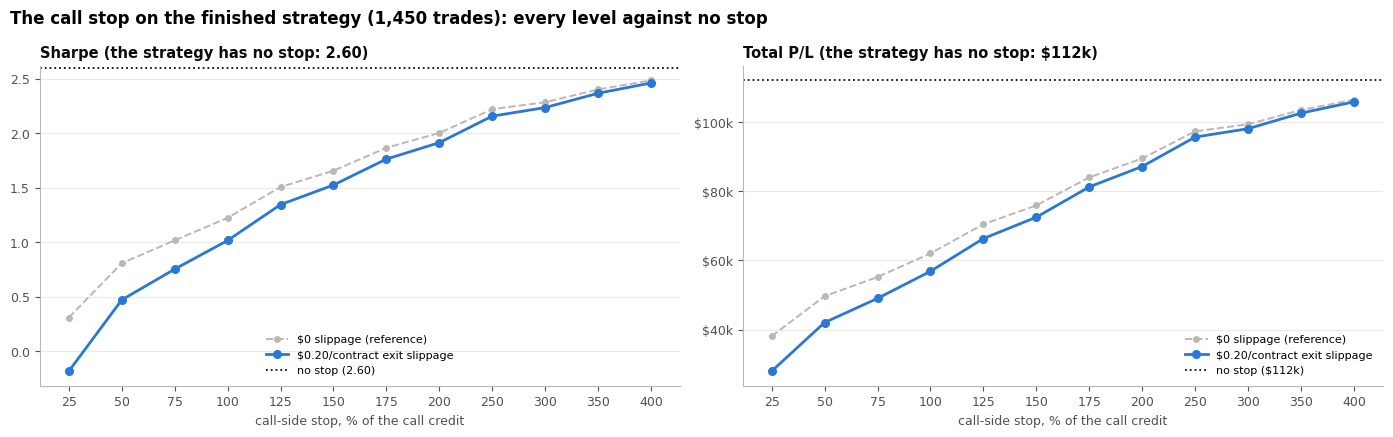

,call_stop_hit_rate,sessions,trades,win_rate,avg_pl,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025
stop_pct,,,,,,,,,,
off,0.00,187,1450,80.97,154.54,112044.00,2.60,-3808.68,2.44,2.92
25,69.79,187,1450,82.07,38.58,27973.08,-0.18,-6408.37,-0.27,0.02
50,52.41,187,1450,65.24,57.99,42039.20,0.47,-4868.86,0.34,0.78
75,42.62,187,1450,53.79,67.60,49010.97,0.75,-4292.98,0.55,1.21
100,35.59,187,1450,54.48,78.41,56848.43,1.02,-4292.98,0.76,1.52
125,28.55,187,1450,60.41,91.47,66316.24,1.35,-4392.98,1.09,1.84
150,23.59,187,1450,64.69,99.98,72482.71,1.52,-4392.98,1.30,1.97
175,19.03,187,1450,68.97,112.06,81243.63,1.76,-4450.50,1.58,2.12
200,16.14,187,1450,71.59,120.19,87141.21,1.91,-3882.56,1.77,2.20


In [24]:
fv.fig_stop(study.stops, note=f"The call stop on the finished strategy ({int(ct.iloc[-1]['trades']):,} trades): every level against no stop"); plt.show()
display(study.stops.loc[fv.EXIT_SLIPPAGE].round(2))

| call stop at $0.20 slippage | fires on | total P/L | Sharpe | max drawdown | 2022-24 / 2025-26 |
|---|---|---|---|---|---|
| **none (strategy)** | | **$112.0k** | **2.60** | **-$3.8k** | **2.44 / 2.92** |
| 100% | 36% of condors | $56.8k | 1.02 | -$4.3k | 0.76 / 1.52 |
| 200% | 16% | $87.1k | 1.91 | -$3.9k | 1.77 / 2.20 |
| 300% | 9% | $98.1k | 2.23 | -$4.0k | 2.21 / 2.29 |
| 400% | 4% | $105.8k | 2.46 | -$3.8k | 2.36 / 2.67 |

- **Every stop level lowers Sharpe and P/L, in both halves, and none makes the drawdown smaller.** The 400% stop the strategy used until now
  costs 0.14 Sharpe and $6.2k for the same -$3.8k drawdown.
- **The entry filters already do the stop's job:** with SPX at or below the open and above its 10-day SMA, the call side rarely runs away, so a
  stopped call usually would have recovered by the close. Tight stops are ruined by slippage and real fills (at 25-100% the stop fires on
  36-70% of condors and Sharpe falls to -0.18 to 1.02).
- **What the backtest can't show is a day far worse than any in these four years.** Going without a stop accepts that risk; the -$3.8k
  drawdown is the worst the data shows, not the worst possible.

### The same test on the puts

The same replay on the put side: a put-side stop at every level, filled where the option chain first crossed it, plus $0.20 per contract
slippage and fees (blue; $0 slippage in grey), the call side held to expiry. The dotted line is the strategy, with no stop. Same 1,450
trades at every level.

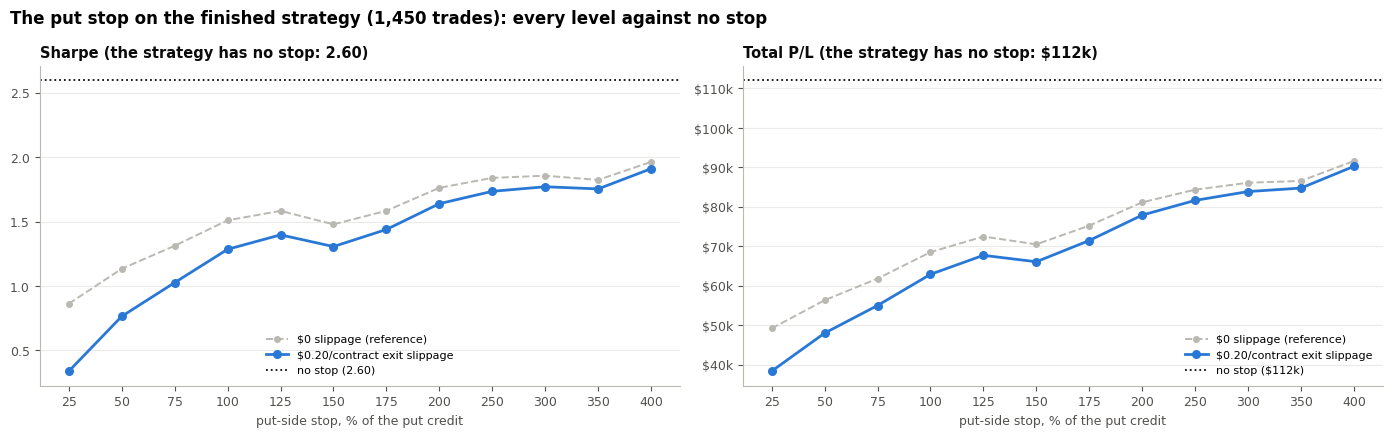

,put_stop_hit_rate,sessions,trades,win_rate,avg_pl,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025
stop_pct,,,,,,,,,,
off,0.00,187,1450,80.97,154.54,112044.00,2.60,-3808.68,2.44,2.92
25,74.76,187,1450,84.00,52.85,38313.67,0.34,-4098.26,0.40,0.22
50,57.52,187,1450,82.21,66.15,47958.01,0.77,-3926.68,0.92,0.47
75,47.03,187,1450,71.17,75.81,54964.50,1.03,-3191.60,1.29,0.49
100,38.76,187,1450,63.45,86.71,62867.32,1.29,-4687.50,1.57,0.72
125,32.83,187,1450,59.03,93.36,67687.65,1.40,-5564.73,1.73,0.72
150,30.48,187,1450,59.31,91.11,66053.96,1.31,-7358.33,1.63,0.67
175,26.07,187,1450,62.62,98.54,71441.15,1.44,-8558.52,1.90,0.53
200,22.34,187,1450,65.79,107.43,77883.22,1.64,-7830.13,2.11,0.72


In [25]:
fv.fig_stop(study.stops_put, note=f"The put stop on the finished strategy ({int(ct.iloc[-1]['trades']):,} trades): every level against no stop", side="put"); plt.show()
display(study.stops_put.loc[fv.EXIT_SLIPPAGE].round(2))

| put stop at $0.20 slippage | fires on | total P/L | Sharpe | max drawdown | 2022-24 / 2025-26 |
|---|---|---|---|---|---|
| **none (strategy)** | | **$112.0k** | **2.60** | **-$3.8k** | **2.44 / 2.92** |
| 100% | 39% of condors | $62.9k | 1.29 | -$4.7k | 1.57 / 0.72 |
| 200% | 22% | $77.9k | 1.64 | -$7.8k | 2.11 / 0.72 |
| 300% | 16% | $83.9k | 1.77 | -$4.6k | 2.07 / 1.13 |
| 400% | 10% | $90.2k | 1.91 | -$4.5k | 2.10 / 1.51 |

| a 400% stop on each side | fires on | spreads stopped | of them, would have expired winning | P/L of the stopped spreads: stopped / held | cost of the stop | Sharpe |
|---|---|---|---|---|---|---|
| call side | 4% of condors | 32 | 31% | -$21.1k / -$14.9k | -$6.2k | 2.46 |
| **put side** | **10%** | **71** | **42%** | **-$41.7k / -$19.9k** | **-$21.8k** | **1.91** |

- **A put stop costs far more than a call stop:** the 400% put stop takes Sharpe from 2.60 to 1.91 and P/L down $21.8k (the call stop:
  2.46, -$6.2k), and it makes the drawdown deeper (-$4.5k), not shallower. Even with no slippage the best put stop scores 1.96. Only the 75%
  level trims the drawdown (to -$3.2k), at a Sharpe of 1.03.
- **The put side touches its stop twice as often and recovers more often:** 71 put spreads reached 400% against 32 calls, and 42% of
  those puts would have expired winning (31% of the calls). Stopping them turns -$19.9k of held losses into -$41.7k.
- **The reason is the entry rule:** the strategy sells its condor after SPX has dipped below its open, in an uptrend (above its 10-day
  SMA). Those intraday dips usually revert by the close, so a put that is deep in trouble at 13:00 is often fine at 16:00, and a stop
  sells it at the worst point.
- **It hurts most in 2025-26** (2.92 -> 1.51 at 400%).
- **The 2026 drawdown (Section 14) can't be tested here:** its two put-side days (2026-06-16 and 06-17) are after the option-chain data
  ends. Whether a put stop would have cut them is a question for the backtester, but over 2022-2026 a put stop costs much more than it
  saves.

## 10. With everything on: is each threshold still at its best?

The cascade judges each threshold on the book built so far, before the later settings are added. Some look off mid-cascade (a +0.5% SMA10
bar at step 3). The real test is with **everything** on: each threshold moved one step at a time, every other setting fixed.

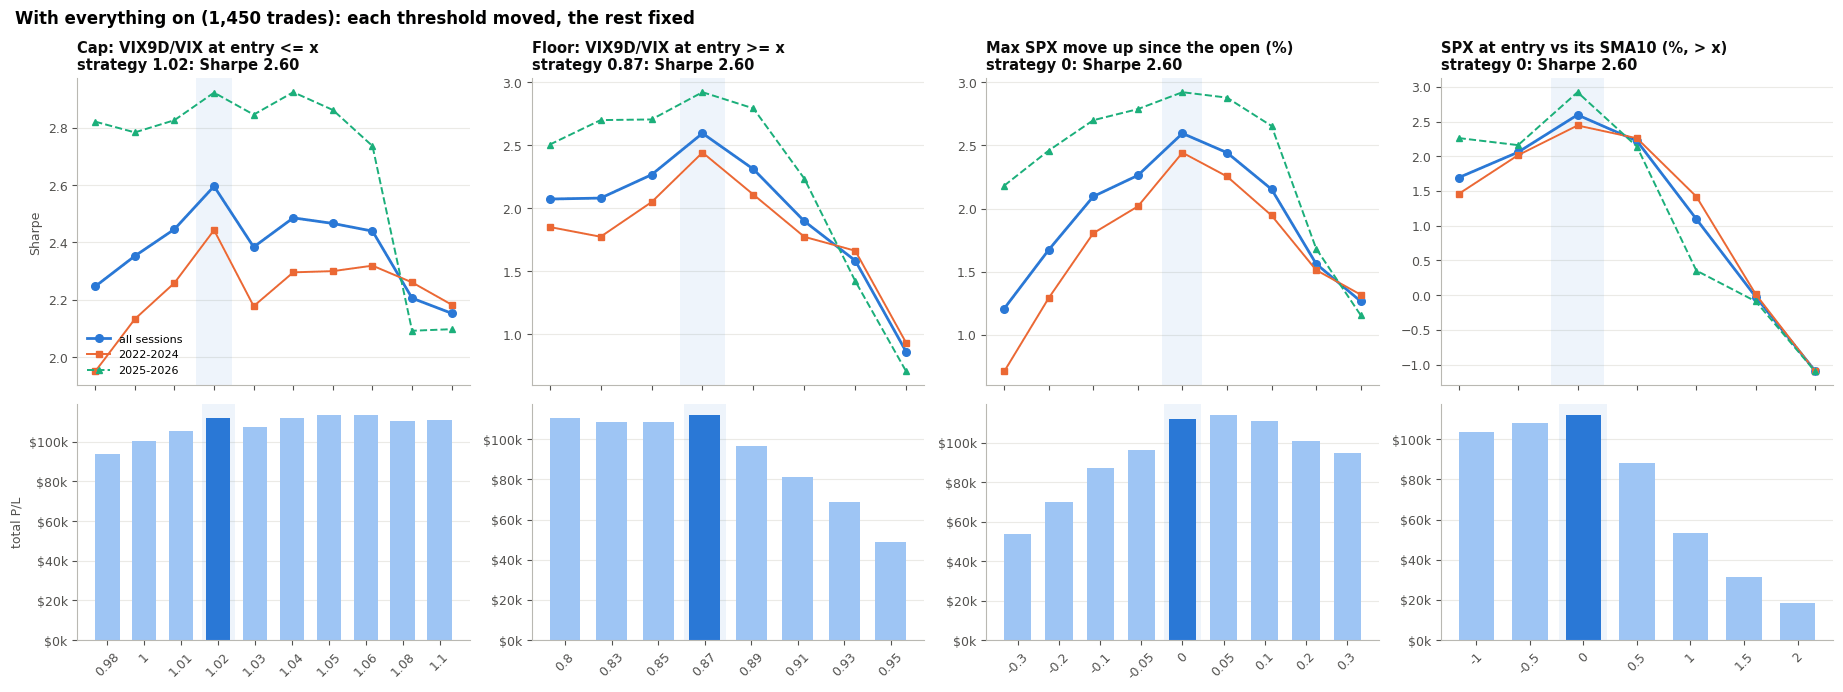

,strategy_value,strategy_sharpe,best_value,best_sharpe,best_sharpe_to_2024,best_sharpe_from_2025
threshold,,,,,,
ts_high,1.02,2.6,1.02,2.6,1.02,1.04
ts_low,0.87,2.6,0.87,2.6,0.87,0.87
max_move,0,2.6,0,2.6,0,0
sma10_min,0,2.6,0,2.6,0,0


kept_pct  trades   total_pl  sharpe  max_drawdown  sharpe_to_2024  sharpe_from_2025
side         max_ratio                                                                                     
whole condor 2.5           54.36     860   73415.60    2.03      -3012.16            1.62              2.72
             3             73.96    1170   94966.20    2.45      -2357.04            2.30              2.73
             3.5           85.34    1350  104427.00    2.49      -3271.64            2.33              2.82
             4             91.66    1450  112044.00    2.60      -3808.68            2.44              2.92
             4.5           94.94    1502  113803.12    2.57      -4716.16            2.45              2.84
             5             98.10    1552  112994.12    2.50      -5195.04            2.36              2.83
             5.5           98.74    1562  112785.72    2.48      -4888.92            2.33              2.83
             6             99.37    1572  113926.32    2.50      -4888.92            2.37              2.83
             7             99.87    1580  112947.80    2.46      -4888.92            2.31              2.83
             off          100.00    1582  113370.92    2.48      -4888.92            2.33              2.83

In [26]:
fv.fig_sweeps(study.sweeps, title=f"With everything on ({int(ct.iloc[-1]['trades']):,} trades): each threshold moved, the rest fixed"); plt.show()
display(study.sweep_verdict.round(2))
display(study.sl_caps.round(2))

| threshold | strategy | Sharpe | nearest alternatives | verdict |
|---|---|---|---|---|
| floor (VIX9D/VIX >=) | 0.87 | **2.60** | 0.85: 2.27; 0.89: 2.31 | **at the peak** |
| cap (VIX9D/VIX <=) | 1.02 | **2.60** | 1.03: 2.38; 1.04: 2.49 | **at the peak** |
| max move up | 0% | **2.60** | -0.05%: 2.26; +0.05%: 2.44 | **at the peak** |
| SMA10 bar | 0% | **2.60** | -0.5%: 2.06; +0.5%: 2.22 | **at the peak** |
| short/long cap | 4 | **2.60** | 3.5: 2.49; 4.5: 2.57 | **at the peak** |

**With everything on, every threshold is at the top of its sweep, by a clear margin.** The +0.5% SMA10 bar that led at step 3 was ahead only
because the band wasn't on yet.

## 11. Drawdowns by tranche: where the losses come from, and whether to cut the 7 further

Everything in this section is on **the finished strategy** (all six settings, held to expiry): 1,450 trades, $112.0k, Sharpe 2.60, max
drawdown -$3.8k. First, the book's drawdowns: the equity curve, the curve below its last peak, and its five deepest drawdowns.

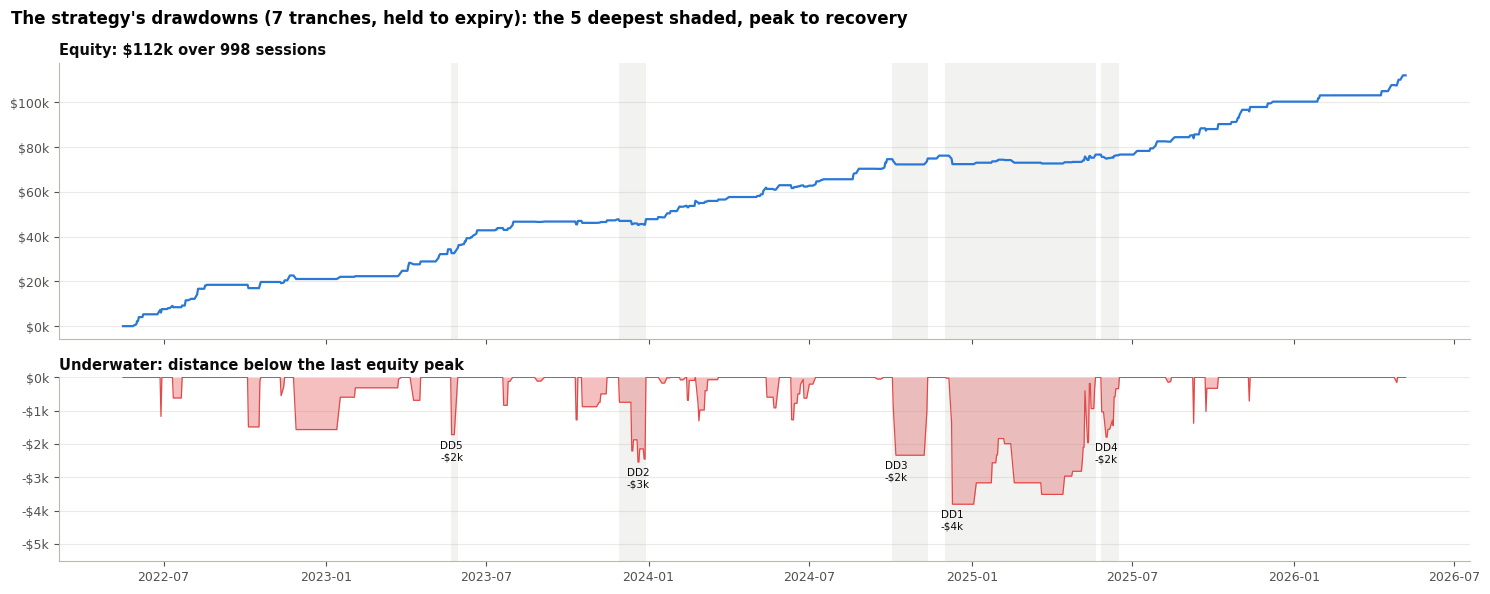

,peak,trough,recovered,depth,sessions_to_trough,sessions_under
drawdown,,,,,,
DD1,2024-12-02,2024-12-10,2025-05-21,-3809.0,6,115
DD2,2023-11-28,2023-12-20,2023-12-29,-2543.0,16,21
DD3,2024-10-03,2024-10-07,2024-11-12,-2338.0,2,27
DD4,2025-05-27,2025-06-02,2025-06-17,-1796.0,4,14
DD5,2023-05-22,2023-05-23,2023-05-30,-1721.0,1,4


In [27]:
tdd = td.compute(panel)
td.fig_underwater(tdd.daily, tdd.episodes); plt.show()
display(tdd.episodes.round(0))

| drawdown | peak | trough | recovered | depth | sessions to the trough |
|---|---|---|---|---|---|
| **DD1** | 2024-12-02 | 2024-12-10 | 2025-05-21 | **-$3.8k** | 6 (115 under water) |
| DD2 | 2023-11-28 | 2023-12-20 | 2023-12-29 | -$2.5k | 16 |
| DD3 | 2024-10-03 | 2024-10-07 | 2024-11-12 | -$2.3k | 2 |
| DD4 | 2025-05-27 | 2025-06-02 | 2025-06-17 | -$1.8k | 4 |
| DD5 | 2023-05-22 | 2023-05-23 | 2023-05-30 | -$1.7k | 1 |

- **The deepest drawdown is -$3.8k, reached in six sessions in December 2024**; recovering took until May 2025 (115 sessions).
- **The others are -$1.7k to -$2.5k**, each recovered within six weeks.

**Which tranches lost money in each drawdown**, from its peak to its trough:

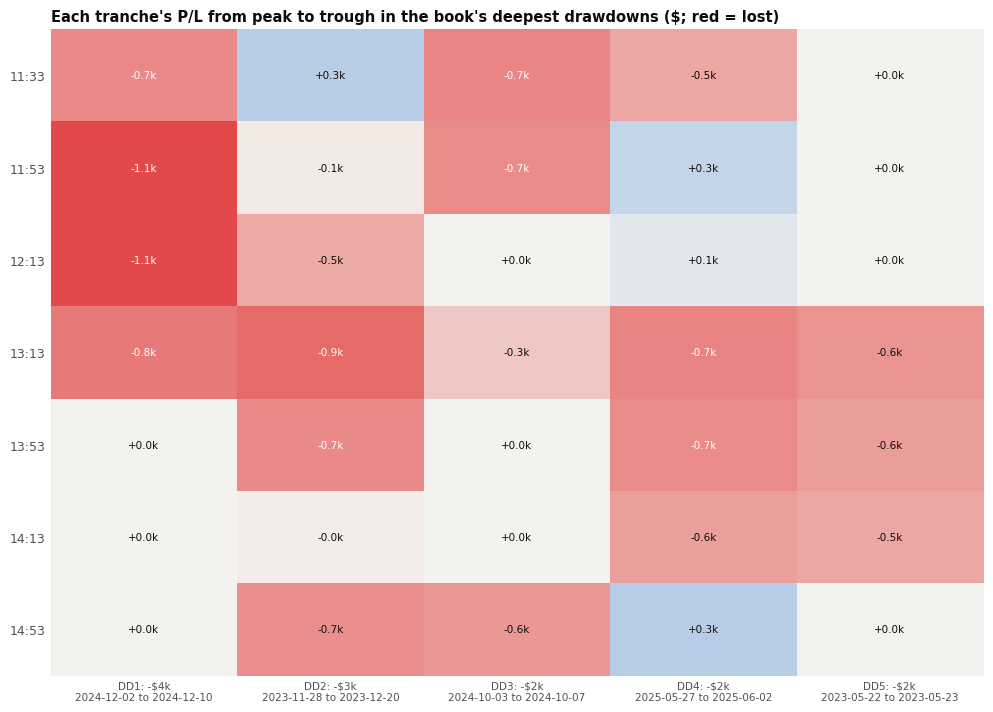

,DD1,DD2,DD3,DD4,DD5
tranche,,,,,
11:33,-702.0,336.0,-729.0,-513.0,0.0
11:53,-1150.0,-61.0,-699.0,271.0,0.0
12:13,-1145.0,-486.0,0.0,101.0,0.0
13:13,-813.0,-919.0,-296.0,-744.0,-634.0
13:53,0.0,-707.0,0.0,-699.0,-581.0
14:13,0.0,-38.0,0.0,-559.0,-506.0
14:53,0.0,-669.0,-614.0,346.0,0.0
book,-3809.0,-2543.0,-2338.0,-1796.0,-1721.0


In [28]:
td.fig_episode_heatmap(tdd.contrib, tdd.episodes); plt.show()
display(tdd.contrib.round(0))

- **DD1 is the late-morning tranches:** 11:53 (-$1.15k), 12:13 (-$1.14k), 13:13 (-$0.8k) and 11:33 (-$0.7k); the three afternoon tranches
  didn't lose in it.
- **The others are spread out:** 13:13 lost in all five (-$0.3k to -$0.9k), and with 13:53-14:53 it carries most of DD2, DD4 and DD5.

Each tranche's own drawdown, on one scale, and its P/L year by year:

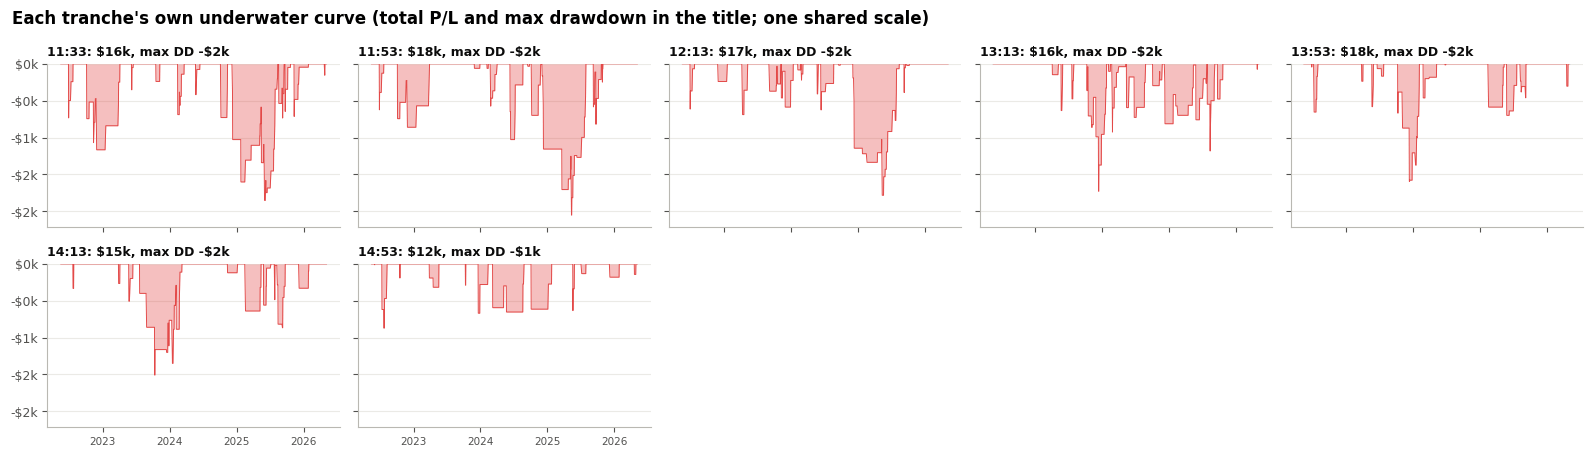

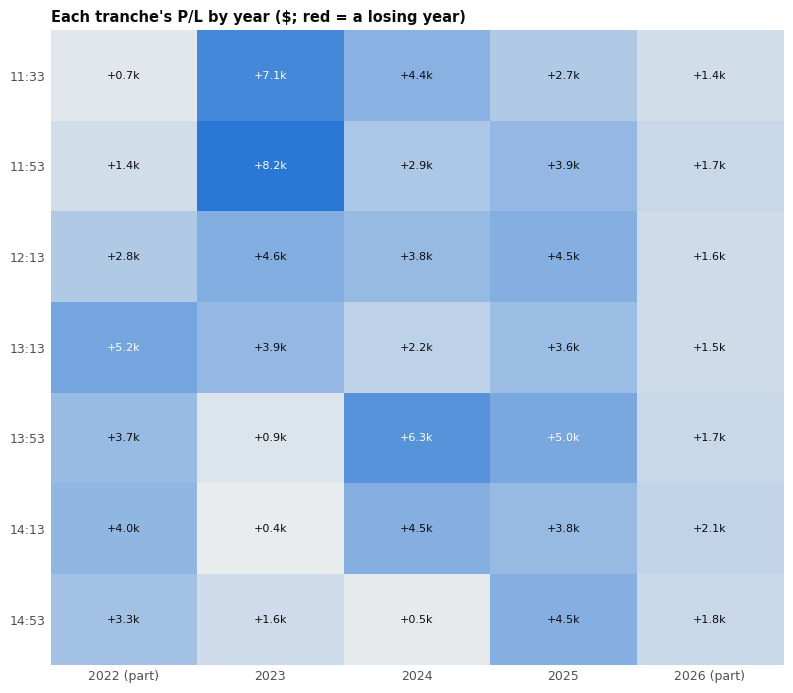

,trades,total_pl,max_drawdown,pl_per_dd,worst_day,pl_in_worst_dd,share_of_worst_dd_pct,pl_on_20_worst_days,pl_in_top_dds,sharpe_if_dropped,pl_if_dropped,max_dd_if_dropped
tranche,,,,,,,,,,,,
11:33,244,16279.64,-1853.68,8.78,-758.88,-701.64,18.42,-5317.32,-1607.16,-0.20,-16279.64,701.64
11:53,238,18079.28,-2052.68,8.81,-798.88,-1149.64,30.18,-6134.20,-1638.28,-0.22,-18079.28,807.24
12:13,220,17204.20,-1783.04,9.65,-758.88,-1144.64,30.05,-3985.32,-1529.40,-0.21,-17204.20,975.40
13:13,230,16368.80,-1729.04,9.47,-743.88,-812.76,21.34,-5624.44,-3405.04,-0.16,-16368.80,812.76
13:53,202,17674.12,-1595.52,11.08,-723.88,0.00,-0.00,-2638.04,-1986.52,-0.28,-17674.12,0.00
14:13,182,14781.92,-1508.64,9.80,-648.88,0.00,-0.00,-1766.04,-1102.64,-0.22,-14781.92,0.00
14:53,134,11656.04,-870.76,13.39,-668.88,0.00,-0.00,-51.40,-936.64,-0.20,-11656.04,-594.08


,2022,2023,2024,2025,2026,losing_years
tranche,,,,,,
11:33,721.0,7093.0,4362.0,2741.0,1363.0,0
11:53,1393.0,8215.0,2865.0,3862.0,1744.0,0
12:13,2751.0,4635.0,3762.0,4487.0,1569.0,0
13:13,5168.0,3873.0,2242.0,3590.0,1496.0,0
13:53,3700.0,900.0,6336.0,4987.0,1750.0,0
14:13,4042.0,440.0,4473.0,3768.0,2059.0,0
14:53,3292.0,1575.0,544.0,4491.0,1754.0,0


In [29]:
td.fig_tranche_underwater(tdd.daily); plt.show()
td.fig_by_year(tdd.by_year); plt.show()
display(tdd.table.round(2))
display(tdd.by_year.round(0))

| tranche | trades | total P/L | own max drawdown | P/L per $ of drawdown | losing years | in DD1 | book without it: Sharpe / P/L / max DD |
|---|---|---|---|---|---|---|---|
| 11:33 | 244 | $16.3k | -$1.9k | 8.8 | 0 | -$0.7k | -0.20 / -$16.3k / +$0.7k |
| 11:53 | 238 | **$18.1k** | **-$2.1k** | 8.8 | 0 | **-$1.1k** | -0.22 / -$18.1k / +$0.8k |
| 12:13 | 220 | $17.2k | -$1.8k | 9.6 | 0 | **-$1.1k** | -0.21 / -$17.2k / +$1.0k |
| 13:13 | 230 | $16.4k | -$1.7k | 9.5 | 0 | -$0.8k | -0.16 / -$16.4k / +$0.8k |
| 13:53 | 202 | $17.7k | -$1.6k | 11.1 | 0 | $0.0k | **-0.28** / -$17.7k / $0.0k |
| 14:13 | 182 | $14.8k | -$1.5k | 9.8 | 0 | $0.0k | -0.22 / -$14.8k / $0.0k |
| 14:53 | 134 | $11.7k | **-$0.9k** | **13.4** | 0 | $0.0k | -0.20 / -$11.7k / -$0.6k |

(A single tranche's Sharpe isn't shown: on its own it never clears the 4% hurdle on $200k, so P/L per $ of drawdown compares them instead.
"Book without it: max DD" is the change in the book's max drawdown: + means smaller.)

- **All seven made money in every year**, $11.7k to $18.1k each.
- **Dropping any one costs 0.16 to 0.28 Sharpe and $12k-18k.** The four late-morning tranches each carry part of DD1, so dropping one would
  shrink it by $0.7k-1.0k, but each is among the best earners.

**Cutting further, one tranche at a time.** Starting from the 7, each step drops the tranche whose removal gives the best book: by Sharpe
(blue), or by max drawdown (orange). The circle marks where each rule stops: the highest Sharpe, or (by drawdown) the most P/L per $ of
drawdown.

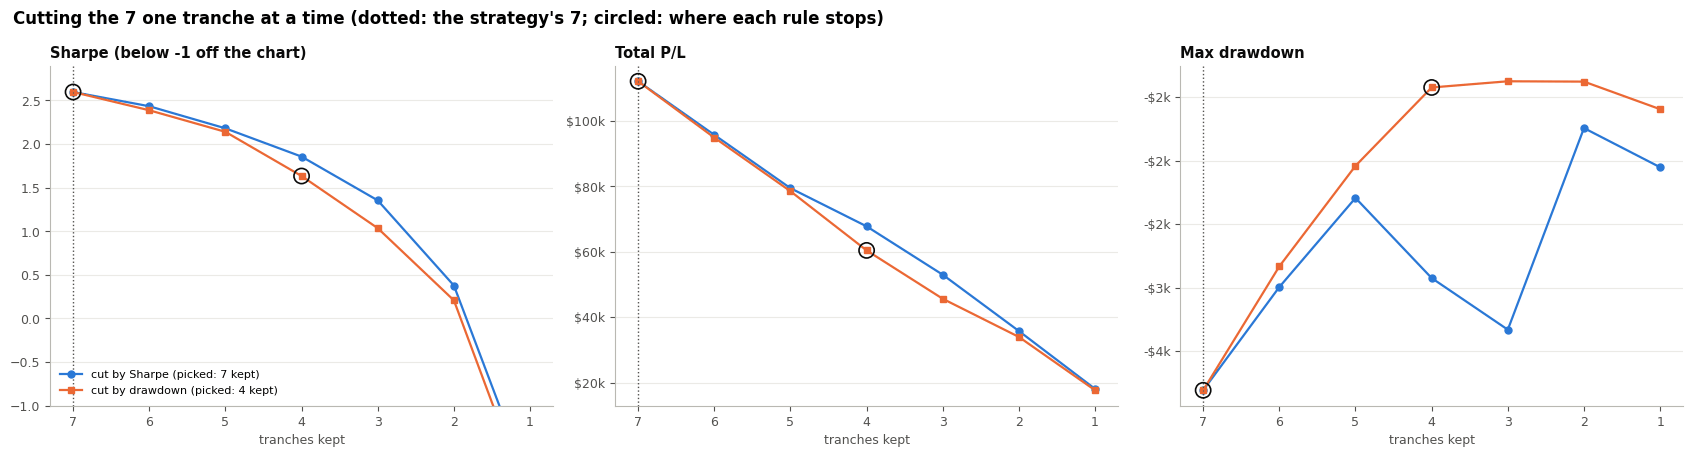

cut by Sharpe: stops at 7 tranches, cutting nothing


,removed,total_pl,sharpe,sharpe_to_2024,sharpe_from_2025,max_drawdown,pl_per_dd
kept,,,,,,,
7,-,112044.00,2.60,2.44,2.92,-3808.68,29.42
6,13:13,95675.20,2.43,2.28,2.73,-2995.92,31.94
5,11:33,79395.56,2.18,1.94,2.64,-2294.28,34.61
4,14:53,67739.52,1.86,1.76,2.03,-2925.08,23.16
3,14:13,52957.60,1.35,1.29,1.49,-3331.48,15.90
2,12:13,35753.40,0.38,0.34,0.45,-1744.16,20.50
1,13:53,18079.28,-1.93,-1.79,-2.21,-2052.68,8.81


cut by drawdown: stops at 4 tranches, cutting 11:53, 12:13, 13:13


,removed,total_pl,sharpe,sharpe_to_2024,sharpe_from_2025,max_drawdown,pl_per_dd
kept,,,,,,,
7,-,112044.00,2.60,2.44,2.92,-3808.68,29.42
6,12:13,94839.80,2.39,2.26,2.65,-2833.28,33.47
5,13:13,78471.00,2.14,2.01,2.39,-2041.64,38.44
4,11:53,60391.72,1.63,1.45,1.97,-1424.40,42.40
3,14:13,45609.80,1.04,0.85,1.39,-1375.64,33.16
2,14:53,33953.76,0.21,0.29,0.04,-1378.28,24.63
1,11:33,17674.12,-2.14,-2.32,-1.78,-1595.52,11.08


In [30]:
td.fig_elimination(tdd.paths); plt.show()
for crit, p in tdd.paths.items():
    print(f"{td.CRITERIA[crit]}: stops at {p.attrs['best']} tranches, cutting {', '.join(p.attrs['cut']) or 'nothing'}")
    display(p.drop(columns="tranches").round(2))

| tranches kept | cut by Sharpe: removed | Sharpe | P/L | max DD | cut by drawdown: removed | Sharpe | P/L | max DD |
|---|---|---|---|---|---|---|---|---|
| **7 (strategy)** | | **2.60** | **$112.0k** | **-$3.8k** | | 2.60 | $112.0k | -$3.8k |
| 6 | 13:13 | 2.43 | $95.7k | -$3.0k | 12:13 | 2.39 | $94.8k | -$2.8k |
| 5 | 11:33 | 2.18 | $79.4k | -$2.3k | 13:13 | 2.14 | $78.5k | -$2.0k |
| 4 | 14:53 | 1.86 | $67.7k | -$2.9k | 11:53 | 1.63 | $60.4k | -$1.4k |

- **By Sharpe there is nothing to cut:** every removal lowers it, so the rule keeps all 7.
- **By drawdown every cut shrinks the drawdown, and the P/L with it:** at 4 tranches the drawdown is -$1.4k but the book makes $60.4k at
  Sharpe 1.63.

**Do the cuts hold out of sample?** The same rules re-run for each year on the earlier years only:

In [31]:
for crit, w in tdd.walk_forward.items():
    lo, hi = w.attrs["cut_vs_strategy_set_ci"]
    print(f"{td.CRITERIA[crit]}: cut vs the strategy's set out of sample, Sharpe difference 95% interval {lo:+.2f} to {hi:+.2f}; "
          f"cut better in {w.attrs['p_cut_better']:.0%} of resamples")
    display(w.round(2))

cut by Sharpe: cut vs the strategy's set out of sample, Sharpe difference 95% interval -0.69 to -0.31; cut better in 0% of resamples


,kept,cut,cut_sharpe,strategy_set_sharpe,cut_pl,strategy_set_pl,cut_max_dd,strategy_set_max_dd
test_year,,,,,,,,
2023,5.0,"11:33, 11:53",0.58,2.48,11424.08,26732.80,-4632.28,-2542.80
2024,7.0,-,2.08,2.08,24584.48,24584.48,-3808.68,-3808.68
2025,7.0,-,2.69,2.69,27925.56,27925.56,-1796.04,-1796.04
2026,7.0,-,3.59,3.59,11734.36,11734.36,-154.88,-154.88
out of sample,NaN,-,2.04,2.53,75668.48,90977.20,-4632.28,-3808.68


cut by drawdown: cut vs the strategy's set out of sample, Sharpe difference 95% interval -1.88 to -0.97; cut better in 0% of resamples


,kept,cut,cut_sharpe,strategy_set_sharpe,cut_pl,strategy_set_pl,cut_max_dd,strategy_set_max_dd
test_year,,,,,,,,
2023,3.0,"11:33, 11:53, 12:13, 14:53",-0.61,2.48,5213.16,26732.80,-3918.08,-2542.80
2024,6.0,13:13,2.11,2.08,22342.00,24584.48,-2995.92,-3808.68
2025,3.0,"11:53, 12:13, 13:13, 14:53",0.87,2.69,11496.64,27925.56,-1770.52,-1796.04
2026,4.0,"11:53, 12:13, 13:13",2.63,3.59,6925.60,11734.36,-237.40,-154.88
out of sample,NaN,-,1.11,2.53,45977.40,90977.20,-3918.08,-3808.68


- **By Sharpe, the rule cuts nothing in 2024-26**; only in 2023, with a single year of history, does it cut (11:33 and 11:53), and that
  year it loses (0.58 against 2.48).
- **By drawdown, the cuts lose out of sample** (1.11 against 2.53, $46.0k against $91.0k).

**What this says about cutting the selection:** nothing. Every one of the 7 made money every year, each one's removal lowers Sharpe, and the
drawdowns are shallow market episodes that a smaller book would only make smaller in proportion.

## 12. Feature ranking and correlation

Every feature on one Sharpe scale, against the finished strategy:

- **the strategy's settings (blue, bold, "ON:"):** the Sharpe **lost** when the setting is removed from the finished strategy;
- **every other feature (orange):** the Sharpe **gained** by its best single cut as a further filter (a min or max at a decile, keeping
  at least 30% of condors). Dark orange means the gain holds in both halves;
- **a noise feature (grey):** a random number per session put through the same search: **whatever it scores is what luck alone finds.**

The red line is the strict noise bar: the 95th percentile of the same search on 200 random features. The candidates are price,
volatility, curve and calendar features, including the 20-day SMA (now a candidate, not a setting) and the vol-regime feature library's
findings (VIX9D gap, month end, rule W, ATR20, low VRP).

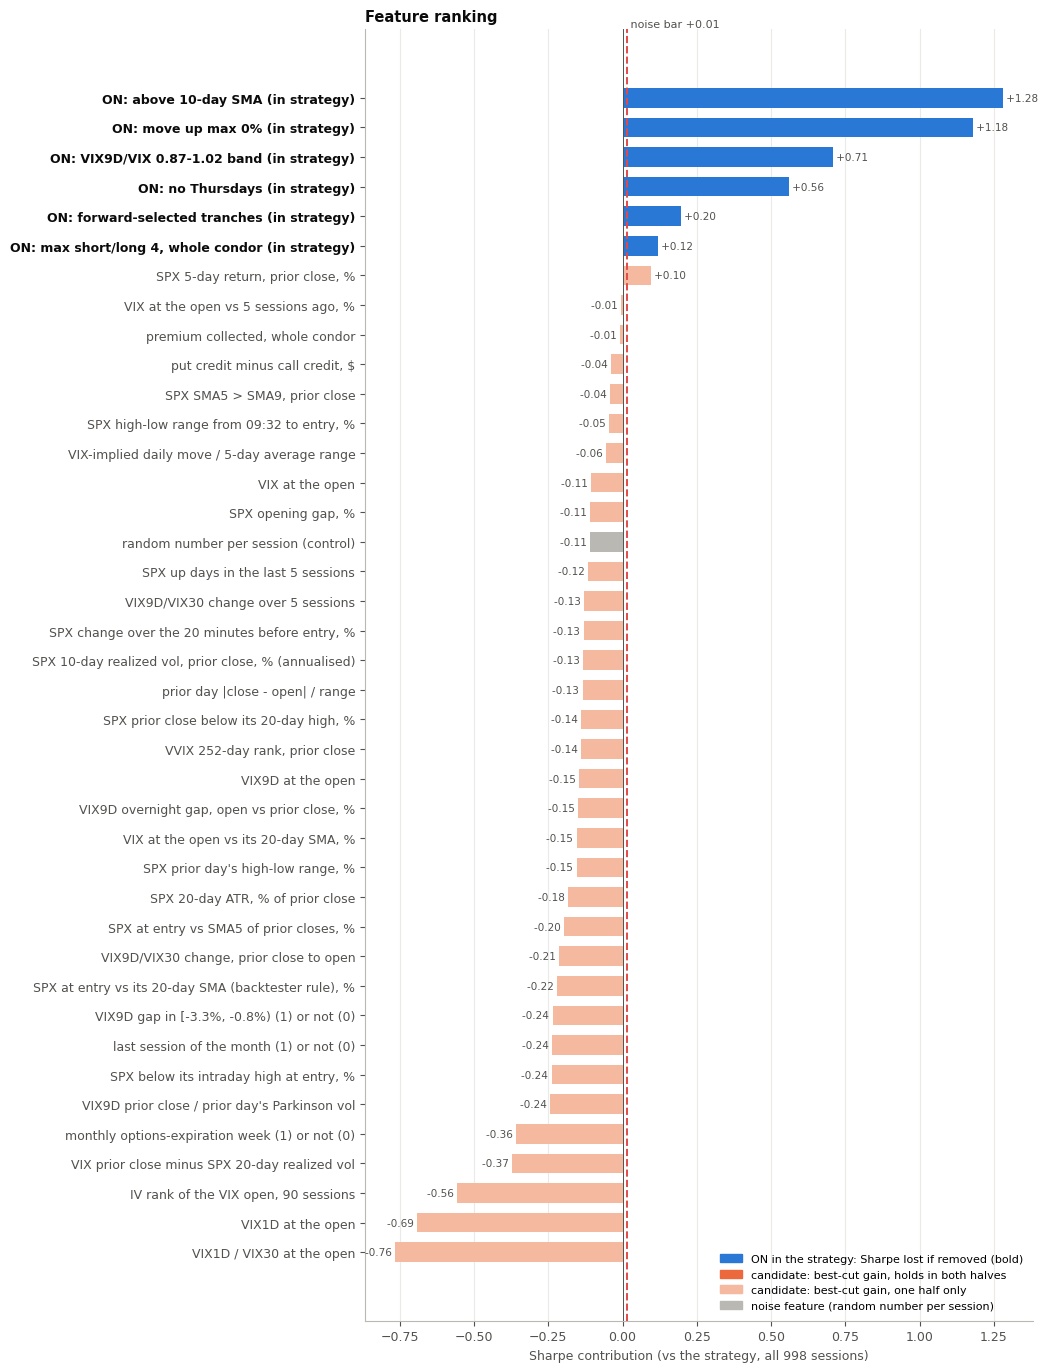

the noise feature gains -0.11; strict noise bar (95th pct of 200 noise features) +0.01


,sessions,trades,win_rate,avg_pl,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025,sharpe_vs_strategy,total_pl_vs_strategy
strategy,187.0,1450.0,80.97,154.54,112044.00,2.60,-3808.68,2.44,2.92,0.00,0.00
with a 400% call stop (not traded),187.0,1450.0,79.59,145.98,105832.53,2.46,-3808.68,2.36,2.67,-0.14,-6211.47
without the band,277.0,2324.0,75.99,100.00,116202.44,1.89,-5095.72,1.84,1.96,-0.71,4158.44
without move <= 0%,365.0,3946.0,70.20,62.05,122433.76,1.42,-11084.88,1.37,1.52,-1.18,10389.76
without SPX > SMA10,319.0,2864.0,73.32,70.42,100836.84,1.32,-11768.68,1.39,1.15,-1.28,-11207.16
trading Thursdays,237.0,1862.0,76.69,115.50,107530.72,2.03,-10773.60,2.02,2.05,-0.56,-4513.28
keeping the morning tranches,288.0,3940.0,76.95,107.29,211370.40,2.40,-12700.72,2.30,2.61,-0.20,99326.40
without short/long ratio <= 4,188.0,1582.0,79.14,143.33,113370.92,2.48,-4888.92,2.33,2.83,-0.12,1326.92


,feature,role,rule,sharpe_contribution,contribution_to_2024,contribution_from_2025,total_pl_effect,holds_in_both_halves,verdict
rank,,,,,,,,,
1,ON: above 10-day SMA (in strategy),in strategy,as set,1.28,1.05,1.77,11207.16,True,filter: pays in both halves
2,ON: move up max 0% (in strategy),in strategy,as set,1.18,1.07,1.40,-10389.76,True,filter: pays in both halves
3,ON: VIX9D/VIX 0.87-1.02 band (in strategy),in strategy,as set,0.71,0.60,0.96,-4158.44,True,filter: pays in both halves
4,ON: no Thursdays (in strategy),in strategy,as set,0.56,0.42,0.87,4513.28,True,filter: pays in both halves
5,ON: forward-selected tranches (in strategy),in strategy,as set,0.20,0.14,0.31,-99326.40,True,filter: pays in both halves
6,"ON: max short/long 4, whole condor (in strategy)",in strategy,as set,0.12,0.11,0.10,-1326.92,True,filter: pays in both halves
7,"SPX 5-day return, prior close, %",candidate,ret5_prev_pct >= 0.302,0.10,-0.03,0.34,-2357.64,False,candidate: not useful
8,"VIX at the open vs 5 sessions ago, %",candidate,vix_5d_chg_pct <= 6.111,-0.01,0.14,-0.32,-5336.76,False,candidate: not useful
9,"premium collected, whole condor",candidate,credit <= 425,-0.01,-0.05,0.05,-5402.32,False,candidate: not useful


In [32]:
fv.fig_ranking(study.ranking); plt.show()
print(f"the noise feature gains {study.addon_scan.loc['noise', 'sharpe_gain']:+.2f}; strict noise bar "
      f"(95th pct of 200 noise features) {study.addon_scan.attrs['noise_p95']:+.2f}")
display(study.leave_one_out.round(2))
display(study.ranking.round(2))

**The noise feature scores -0.11**, and the strict bar is **+0.01**.

| removed from the finished strategy | trades | Sharpe | change | total P/L change |
|---|---|---|---|---|
| above the 10-day SMA | 2,864 | 1.32 | **-1.28** | -$11.2k |
| max move up 0% | 3,946 | 1.42 | **-1.18** | +$10.4k |
| the VIX9D/VIX band | 2,324 | 1.89 | **-0.71** | +$4.2k |
| no Thursdays | 1,862 | 2.03 | **-0.56** | -$4.5k |
| the 7 tranches (trade all 20) | 3,940 | 2.40 | -0.20 | +$99.3k |
| short/long ratio <= 4 | 1,582 | 2.48 | -0.12 | +$1.3k |
| *added: a 400% call stop* | 1,450 | 2.46 | *-0.14* | *-$6.2k* |

- **Every setting pays, in both halves.** The 10-day SMA is now the most important: without it Sharpe falls to 1.32, the book loses $11.2k
  and the drawdown triples (-$3.8k to -$11.8k).
- **No candidate adds in both halves.** SPX's 5-day return (+0.10) clears the noise bar overall but only from 2025 (-0.03 in 2022-24).
  SMA5 > SMA9 loses (-0.04).

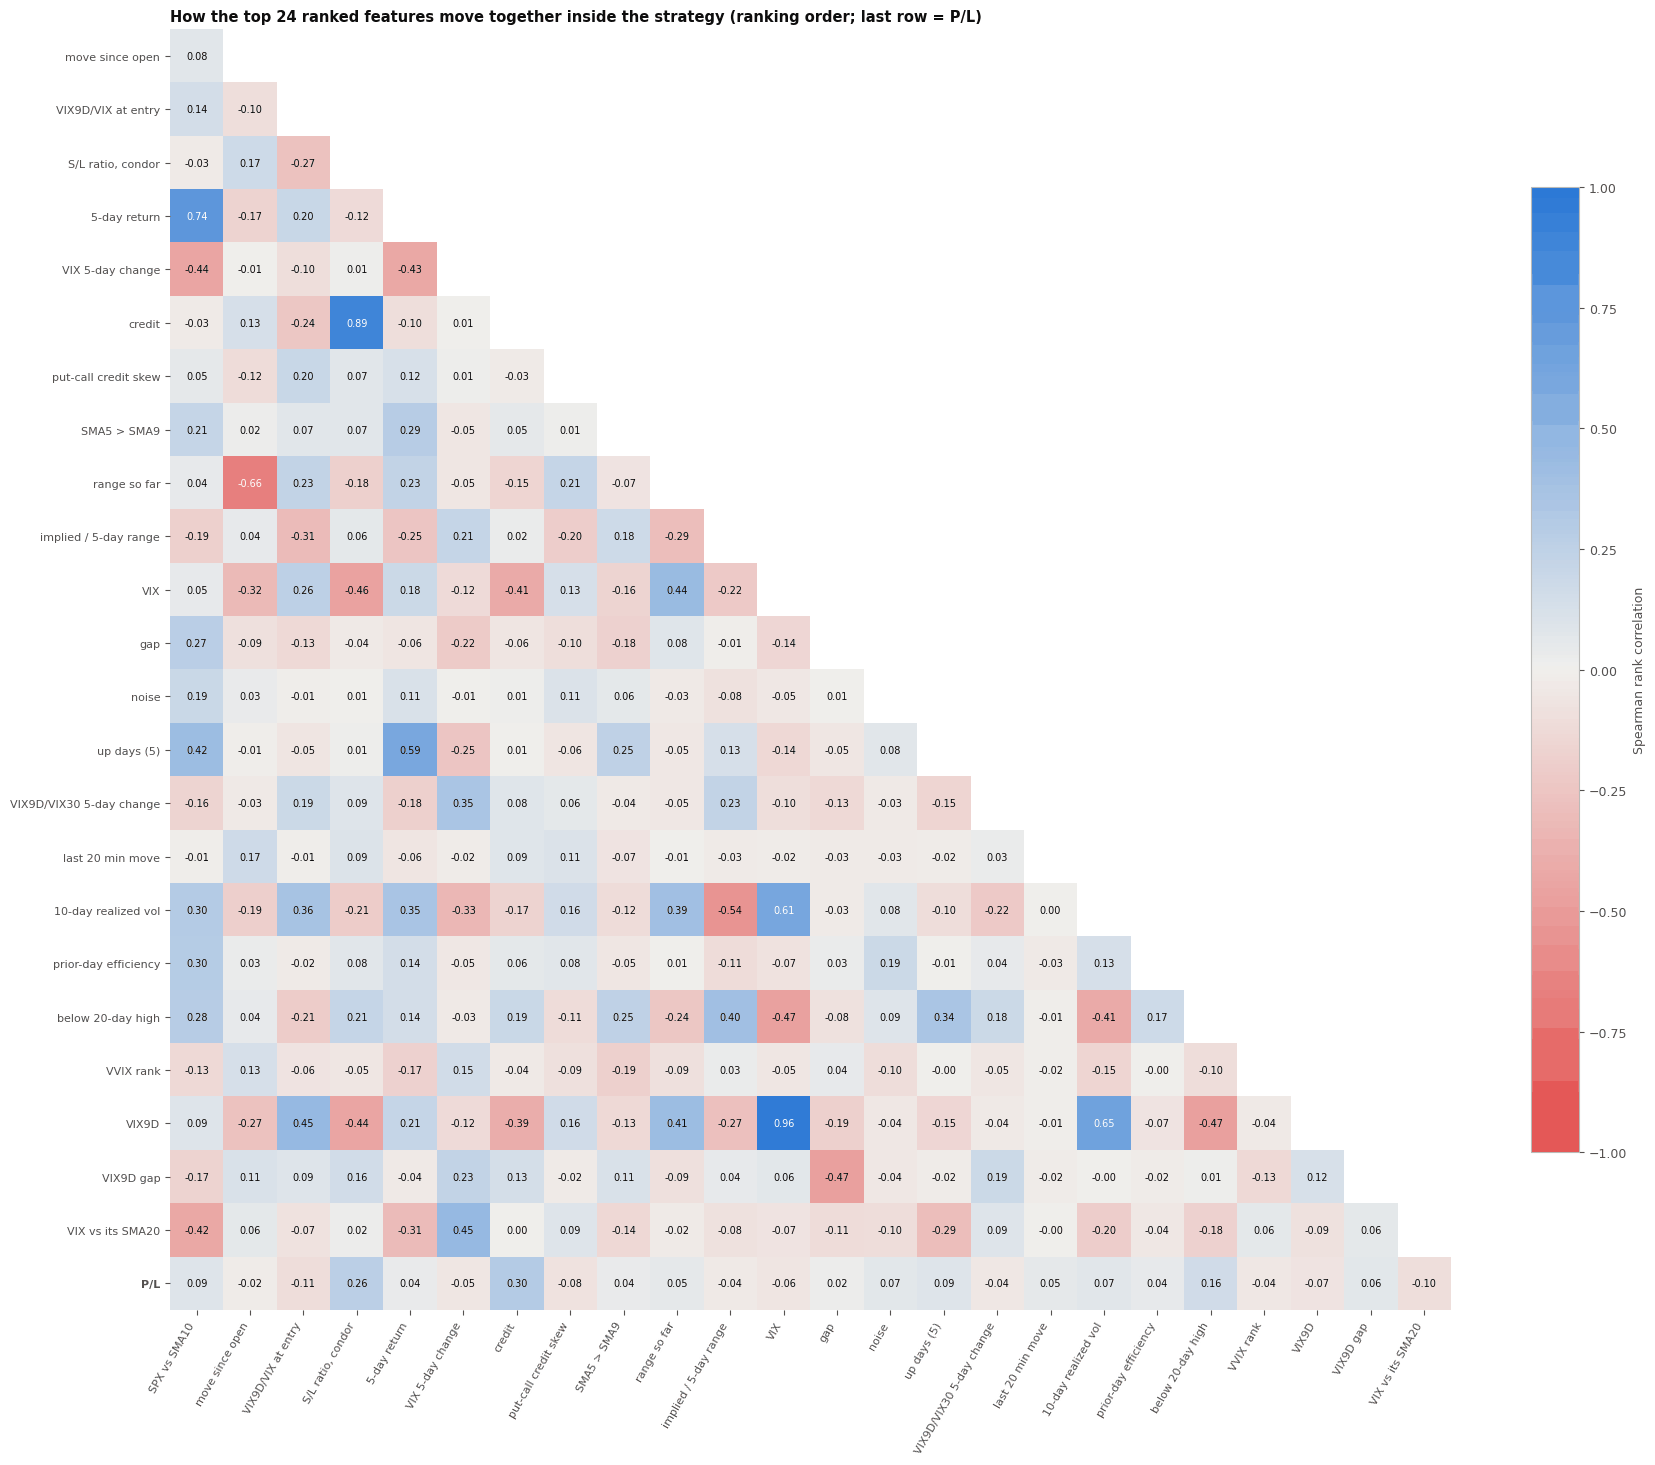

,feature_a,feature_b,spearman,corr_with_pl_a,corr_with_pl_b
0,VIX,VIX9D,0.96,-0.06,-0.07
1,VIX9D gap,VIX9D/VIX30 overnight,0.91,0.06,0.06
2,prior-day range,VIX9D / Parkinson vol,-0.89,0.03,-0.07
3,"S/L ratio, condor",credit,0.89,0.26,0.30
4,range so far,below intraday high,-0.80,0.05,-0.02
5,VIX9D,ATR20,0.80,-0.07,0.00
6,VIX1D,VIX1D/VIX30,0.77,-0.12,-0.06
7,SPX vs SMA10,SPX at entry vs SMA5,0.77,0.09,0.05
8,10-day realized vol,ATR20,0.77,0.07,0.00
9,VIX,ATR20,0.75,-0.06,0.00


,corr_with_pl
credit,0.30
"S/L ratio, condor",0.26
SPX vs SMA20,0.17
below 20-day high,0.16
IV rank 90,-0.14
VIX1D,-0.12
VIX9D/VIX at entry,-0.11
VIX vs its SMA20,-0.10
SPX vs SMA10,0.09
up days (5),0.09


,sessions,total_pl,sharpe,max_drawdown,sharpe_to_2024,sharpe_from_2025,sharpe_change,sharpe_to_2024_change,sharpe_from_2025_change,total_pl_change,better_in_both_halves
strategy,187.0,112044.00,2.60,-3808.68,2.44,2.92,0.00,0.00,0.00,0.00,False
+ VVIX 252-day rank <= 25,135.0,83062.76,1.93,-4843.48,1.75,2.26,-0.67,-0.70,-0.66,-28981.24,False
+ VVIX 252-day rank <= 30,157.0,101696.60,2.41,-3808.68,2.23,2.77,-0.18,-0.22,-0.16,-10347.40,False
+ VVIX 252-day rank <= 35,166.0,106202.20,2.53,-3808.68,2.36,2.87,-0.07,-0.09,-0.06,-5841.80,False
+ VVIX 252-day rank <= 40,176.0,108349.80,2.56,-3808.68,2.40,2.87,-0.04,-0.04,-0.05,-3694.20,False
+ VVIX 252-day rank <= 50,186.0,111784.76,2.59,-3808.68,2.43,2.92,-0.01,-0.01,0.00,-259.24,False
+ condor credit <= $450,186.0,109223.16,2.59,-3549.80,2.42,2.94,-0.01,-0.03,0.02,-2820.84,False
+ SPX gap >= -0.5%,174.0,108674.80,2.55,-3808.68,2.48,2.71,-0.04,0.03,-0.21,-3369.20,False
+ SPX gap >= -0.25%,155.0,97596.52,2.30,-3808.68,2.21,2.47,-0.30,-0.23,-0.45,-14447.48,False
+ SPX gap >= 0%,111.0,75546.96,1.78,-2440.52,1.64,2.06,-0.81,-0.80,-0.86,-36497.04,False


In [33]:
fv.fig_feature_corr(study.feature_corr); plt.show()
display(study.redundant_pairs.round(2))
display(study.feature_corr["P/L"].drop("P/L").sort_values(key=abs, ascending=False).round(2).to_frame("corr_with_pl"))
display(study.addon_test.round(2))

**The features fall into a few clusters that say the same thing twice:** vol level (VIX and VIX9D: 0.96), premium (credit and the
condor's ratio: 0.89), trend (SPX vs SMA10 with SPX vs SMA5 and the 5-day return: 0.74-0.77), intraday path (range so far, below the
intraday high, move since the open: 0.75-0.80). **VIX9D/VIX at entry stands on its own**: it measures the curve's shape, not its level.
Correlation with P/L is small everywhere (credit +0.30, the ratio +0.26, SPX vs SMA20 +0.17, the rest within ±0.16).

| on top of the strategy | sessions | Sharpe | change | total P/L change | both halves |
|---|---|---|---|---|---|
| SMA5 > SMA9 | 164 | 2.55 | -0.04 | -$5.6k | no (-0.12 in 2022-24, +0.14 in 2025-26) |
| condor credit <= $450 | 186 | 2.59 | -0.01 | -$2.8k | no |
| VVIX rank <= 35 | 166 | 2.53 | -0.07 | -$5.8k | no |
| SPX gap >= 0% | 111 | 1.78 | -0.81 | -$36.5k | no |

**Nothing tested improves the finished strategy.**

## 13. A/B with everything on: above the 10-day SMA vs the 20-day

No cascade here: **every other setting is on** (no Thursdays, max move 0%, VIX9D/VIX 0.87-1.02, the 7 tranches, ratio <= 4, held to
expiry), and only the trend rule changes: SPX at entry above its 10-day SMA (A, the strategy) against above its 20-day SMA (B), and above
both. Both SMAs are measured the backtester's way (the prior N - 1 closes and the entry price). The Sharpe difference gets a paired session
bootstrap, and two t-tests say how significant each difference is (below).

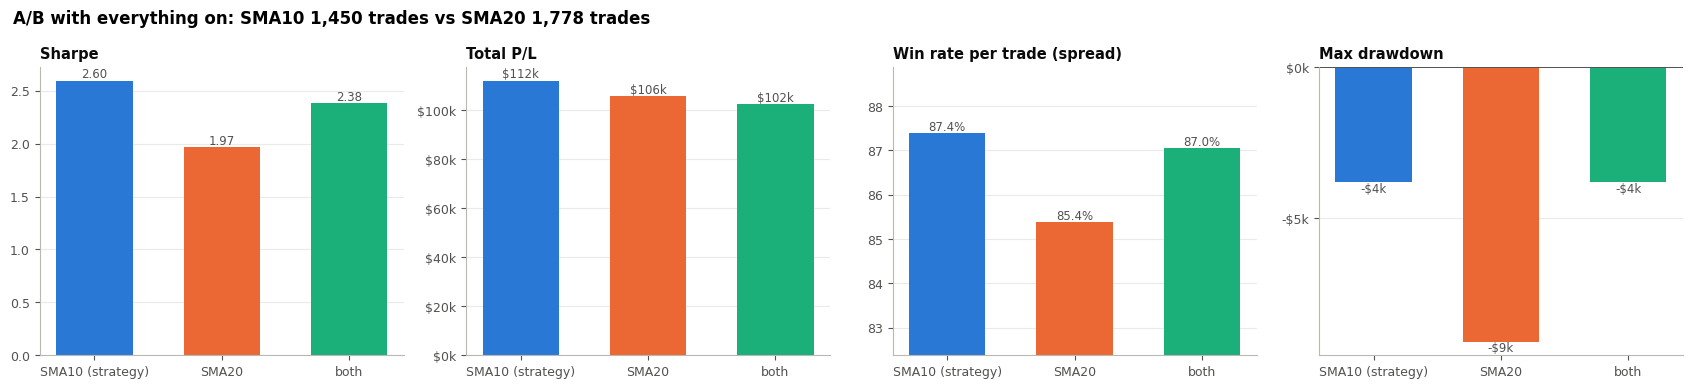

,A: above 10-day SMA (strategy),B: above 20-day SMA,above both
trades,1450.00,1778.00,1320.00
sessions,187.00,212.00,170.00
total_pl,112044.00,105672.68,102361.20
sharpe,2.60,1.97,2.38
sharpe_to_2024,2.44,1.66,2.16
sharpe_from_2025,2.92,2.70,2.83
max_drawdown,-3808.68,-9093.40,-3808.68
win_rate_trade,87.38,85.38,87.05
win_rate_condor,80.97,76.60,80.45
avg_pl_condor,154.54,118.87,155.09


trades only the SMA10 takes: 130 (P/L $10k); only the SMA20 takes: 458 (P/L $3k)


,sharpe A,sharpe B,P/L A,P/L B
year,,,,
2022,2.91,1.81,21066.80,15234.68
2023,2.48,2.36,26732.80,26941.76
2024,2.08,1.18,24584.48,22361.84
2025,2.69,2.46,27925.56,29453.16
2026,3.59,3.57,11734.36,11681.24


significance against A (the strategy's 10-day SMA); a negative t means worse than A:


,sharpe_vs_A,t_sharpe,p_sharpe,t_daily_pl,p_daily_pl
B: above 20-day SMA,-0.628,-1.731,0.083,-0.543,0.587
above both,-0.213,-1.654,0.098,-2.160,0.031


In [34]:
ab = casc.sma_ab
fv.fig_sma_ab(ab, note=f"A/B with everything on: SMA10 {int(ab.iloc[0]['trades']):,} trades vs SMA20 {int(ab.iloc[1]['trades']):,} trades"); plt.show()
view = ab.astype(float).round(2)
view.attrs = {}
display(view.T)
print(f"trades only the SMA10 takes: {ab.attrs['only_sma10']:,} (P/L {fv._k(ab.attrs['only_sma10_pl'])}); "
      f"only the SMA20 takes: {ab.attrs['only_sma20']:,} (P/L {fv._k(ab.attrs['only_sma20_pl'])})")
display(ab.attrs["by_year"].round(2))
tests = ab.iloc[1:][["sharpe_vs_A", "t_sharpe", "p_sharpe", "t_daily_pl", "p_daily_pl"]].astype(float)
tests.attrs = {}
print("significance against A (the strategy's 10-day SMA); a negative t means worse than A:")
display(tests.round(3))

| everything on, trend rule | trades | total P/L | Sharpe | 2022-24 / 2025-26 | max drawdown | win per trade |
|---|---|---|---|---|---|---|
| **A: above the 10-day SMA (strategy)** | 1,450 | **$112.0k** | **2.60** | **2.44 / 2.92** | **-$3.8k** | **87.4%** |
| B: above the 20-day SMA | 1,778 | $105.7k | 1.97 | 1.66 / 2.70 | -$9.1k | 85.4% |
| above both | 1,320 | $102.4k | 2.38 | 2.16 / 2.83 | -$3.8k | 87.1% |

| year | Sharpe A (SMA10) / B (SMA20) | P/L A / B |
|---|---|---|
| 2022 (part) | **2.91** / 1.81 | **$21.1k** / $15.2k |
| 2023 | **2.48** / 2.36 | $26.7k / $26.9k |
| 2024 | **2.08** / 1.18 | **$24.6k** / $22.4k |
| 2025 | **2.69** / 2.46 | $27.9k / **$29.5k** |
| 2026 (part) | 3.59 / 3.57 | $11.7k / $11.7k |

- **On the 7 tranches the 10-day wins on every measure:** higher Sharpe (2.60 against 1.97) in every year, $6.4k more P/L, and well under half
  the drawdown (-$3.8k against -$9.1k).
- **The 20-day's extra trades don't pay:** the 458 trades only the 20-day takes earn $3.3k; the 130 only the 10-day takes earn $9.7k.
- **The 10-day is better in 96% of resamples** (interval -1.33 to +0.07 for SMA20 minus SMA10), just short of a 95% bar.

**Statistical significance.** Two tests, each against the strategy's 10-day SMA on the same 998 sessions (a negative t means worse than the
10-day):

- **t on the Sharpe difference:** the difference over its standard error from the paired session bootstrap, two-sided. It tests the
  question the A/B asks: is one rule's risk-adjusted return higher?
- **t on the daily P/L difference:** a paired t-test on the session-by-session P/L difference, every session (no-trade days as zero),
  two-sided. It tests whether one rule makes more money on an average day, ignoring risk.

| against the 10-day SMA | Sharpe difference | t (Sharpe) | p (Sharpe) | t (daily P/L) | p (daily P/L) |
|---|---|---|---|---|---|
| B: above the 20-day SMA | -0.63 | **-1.73** | 0.08 | -0.54 | 0.59 |
| above both | -0.21 | -1.65 | 0.10 | **-2.16** | **0.03** |

- **SMA10 against SMA20: t = 1.73 on the Sharpe difference (p = 0.08 two-sided, about 0.04 one-sided).** Significant at 10% but not at
  the usual 5% two-sided bar; it says the same as the bootstrap's 96%.
- **The daily P/L barely differs** (t = 0.54, p = 0.59): the two rules make about the same money ($112.0k against $105.7k). **The 10-day's
  edge is risk, not return:** the same money with fewer bad days, hence half the drawdown and the higher Sharpe.
- **Adding the 20-day on top of the 10-day ("above both") makes significantly less money** (t = -2.16, p = 0.03): it drops the 130 trades
  only the 10-day takes, which earn $9.7k, and adds nothing.

**The same A/B on the tranches forward selection by drawdown picks** (Section 7: 10:53, 11:13, 11:33, 12:13, 13:53, 14:13, 14:53, 15:53),
every other setting on, to check the result doesn't depend on the strategy's own tranche set.

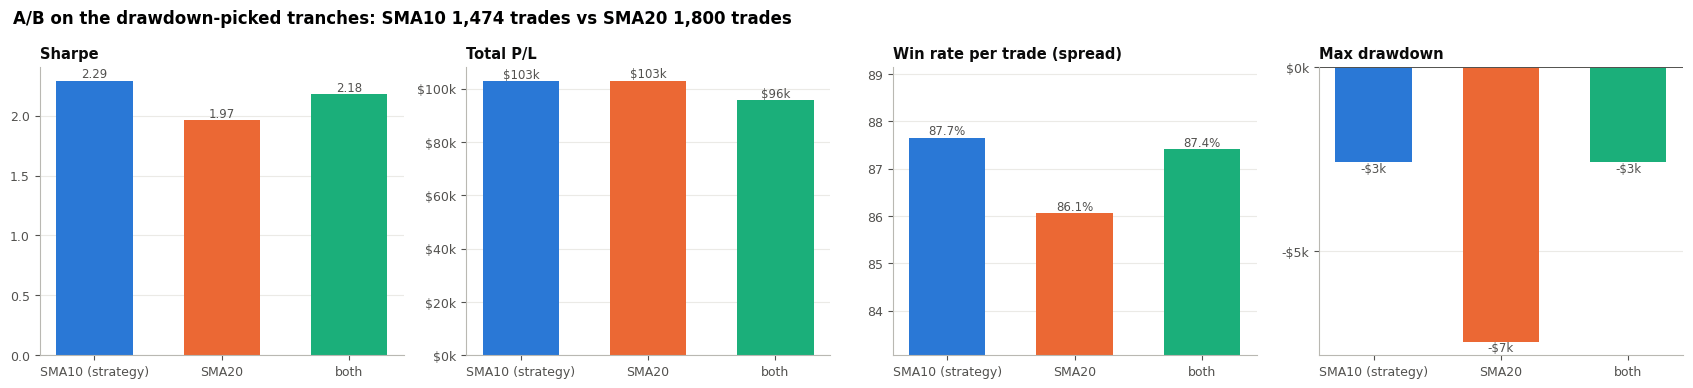

,A: above 10-day SMA (strategy),B: above 20-day SMA,above both
trades,1474.00,1800.00,1350.00
sessions,207.00,231.00,190.00
total_pl,102826.44,103055.00,95840.00
sharpe,2.29,1.97,2.18
sharpe_to_2024,2.28,1.92,2.20
sharpe_from_2025,2.31,2.06,2.15
max_drawdown,-2582.60,-7438.52,-2582.60
win_rate_trade,87.65,86.06,87.41
win_rate_condor,80.19,77.22,80.00
avg_pl_condor,139.52,114.51,141.99


,sharpe A,sharpe B,P/L A,P/L B
year,,,,
2022,1.74,1.27,15174.16,12038.04
2023,2.25,2.65,23814.32,28176.12
2024,2.74,1.80,29480.44,28158.84
2025,2.07,1.81,24298.28,24657.76
2026,3.11,3.10,10059.24,10024.24


In [35]:
ab2 = casc.sma_ab_dd
fv.fig_sma_ab(ab2, note=f"A/B on the drawdown-picked tranches: SMA10 {int(ab2.iloc[0]['trades']):,} trades vs SMA20 {int(ab2.iloc[1]['trades']):,} trades"); plt.show()
view2 = ab2.astype(float).round(2)
view2.attrs = {}
display(view2.T)
by2 = ab2.attrs["by_year"].round(2)
by2.attrs = {}
display(by2)

| drawdown-picked tranches, everything else on | trades | total P/L | Sharpe | 2022-24 / 2025-26 | max drawdown | t (Sharpe) | p | t (daily P/L) | p |
|---|---|---|---|---|---|---|---|---|---|
| **A: above the 10-day SMA** | 1,474 | $102.8k | **2.29** | **2.28 / 2.31** | **-$2.6k** | | | | |
| B: above the 20-day SMA | 1,800 | $103.1k | 1.97 | 1.92 / 2.06 | -$7.4k | -0.89 | 0.38 | +0.02 | 0.98 |
| above both | 1,350 | $95.8k | 2.18 | 2.20 / 2.15 | -$2.6k | -0.65 | 0.52 | -1.40 | 0.16 |

- **The 10-day still leads**, on Sharpe (2.29 against 1.97, ahead in four of five years) and above all on drawdown (-$2.6k against -$7.4k),
  for exactly the same money ($102.8k against $103.1k).
- **But on this tranche set the gap isn't significant** (t = 0.89, p = 0.38; the 10-day is better in 82% of resamples, against 96% on the
  strategy's 7). The 10-day's edge is real in direction and in drawdown, but how big it looks depends on which tranches it's paired with.

## 14. The 2026 drawdown, in the backtester's own log

Everything above is rebuilt from the 20-tranche export, which ends 2026-05-07. **The backtester's log of the live strategy** (the 7
tranches, no Thursdays, held to expiry) runs to 2026-09-28, and it shows a drawdown the rest of this notebook can't see: from a peak on
2026-05-11, **-$13.4k by 2026-06-17**, three and a half times anything in the four years before, and **not recovered** by the end of the
log.

First, a check that the log and this notebook describe the same strategy, on the sessions both cover:

In [36]:
log = lg.load_log()
lc = lg.condors(log)
rec = lg.reconcile(log, panel)
print(f"sessions both cover: {rec.attrs['window'][0]:%Y-%m-%d} to {rec.attrs['window'][1]:%Y-%m-%d}")
display(rec.round(2))

sessions both cover: 2022-05-31 to 2026-05-07


,trades,sessions,total_pl,sharpe,max_drawdown
backtester's log,1446.0,187.0,111335.76,2.51,-3825.52
the study's rebuild,1450.0,187.0,112044.00,2.53,-3808.68


| 2022-05-31 to 2026-05-07 | trades | total P/L | Sharpe | max drawdown |
|---|---|---|---|---|
| the backtester's log | 1,446 | $111.3k | 2.51 | -$3.8k |
| this notebook's rebuild | 1,450 | $112.0k | 2.53 | -$3.8k |

**The rebuild matches the backtester's log almost exactly** (4 trades and $0.7k apart over four years), so the rest of the notebook is the
live strategy. The difference is what came after 2026-05-07.

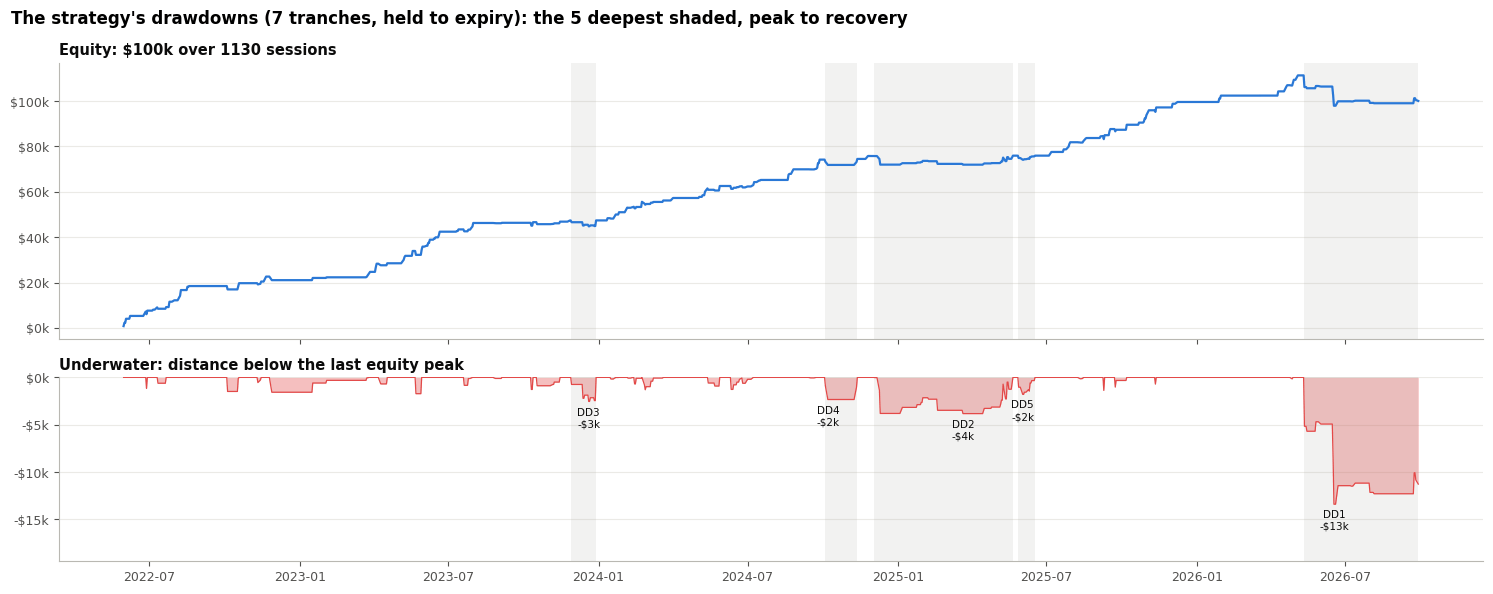

,peak,trough,recovered,depth,sessions_to_trough,sessions_under
drawdown,,,,,,
DD1,2026-05-11,2026-06-17,NaT,-13391.0,27,100
DD2,2024-12-02,2025-03-21,2025-05-21,-3826.0,79,121
DD3,2023-11-28,2023-12-20,2023-12-29,-2543.0,16,22
DD4,2024-10-03,2024-10-07,2024-11-12,-2338.0,2,27
DD5,2025-05-27,2025-06-02,2025-06-17,-1796.0,4,14


,DD1,DD2,DD3,DD4,DD5
tranche,,,,,
11:33,-1526.0,-779.0,336.0,-729.0,-513.0
11:53,-1324.0,-1700.0,-61.0,-699.0,271.0
12:13,-2129.0,-1336.0,-486.0,0.0,101.0
13:13,-2409.0,-698.0,-919.0,-296.0,-744.0
13:53,-1961.0,-45.0,-707.0,0.0,-699.0
14:13,-1227.0,155.0,-38.0,0.0,-559.0
14:53,-2816.0,577.0,-669.0,-614.0,346.0
book,-13391.0,-3826.0,-2543.0,-2338.0,-1796.0


In [37]:
ldaily = lg.daily_matrix(log)
leps = td.episodes(ldaily)
td.fig_underwater(ldaily, leps); plt.show()
display(leps.round(0))
dd_start, dd_end = leps.iloc[0]["peak"] + pd.Timedelta(days=1), leps.iloc[0]["trough"]
display(td.episode_contrib(ldaily, leps).round(0))

| drawdown (backtester's log) | peak | trough | recovered | depth |
|---|---|---|---|---|
| **2026** | **2026-05-11** | **2026-06-17** | **not by 2026-09-28** | **-$13.4k** |
| next deepest | 2024-12-02 | 2025-03-21 | 2025-05-21 | -$3.8k |
| third | 2023-11-28 | 2023-12-20 | 2023-12-29 | -$2.5k |

- **Every tranche lost in it** (-$1.2k to -$2.8k each, 14:53 the most): it isn't one weak tranche, it is whole days going wrong.
- **After the trough the strategy traded 8 sessions to the end of September and made +$2.1k**; the book was still $11.3k below its peak.

**What happened: three days.**

In [38]:
display(lg.before_vs_drawdown(lc, log, dd_start, dd_end).round(2))
display(lg.worst_days(lc).round(2))

,before the drawdown,the drawdown
condors,723.00,31.00
sessions,187.00,6.00
total_pl,111335.76,-13391.28
avg_pl,153.99,-431.98
win_rate_pct,80.91,25.81
avg_win,284.46,216.12
avg_loss,-399.06,-657.40
full_wing_losses,37.00,19.00
credit_per_condor,325.30,245.00
vix_at_entry,17.73,17.26


,pl,condors,full_wing,call_side,put_side,vix,spx_after_entry_pct,weekday
date,,,,,,,,
2026-05-12,-5162.16,7,7,-5978.58,816.42,19.02,0.55,Tuesday
2026-06-17,-4842.16,7,6,671.42,-5513.58,16.85,-1.15,Wednesday
2026-06-16,-3622.16,7,5,1101.42,-4723.58,15.94,-0.34,Tuesday
2024-12-10,-2440.52,4,2,772.24,-3212.76,14.07,-0.29,Tuesday
2023-05-23,-1720.64,3,1,594.18,-2314.82,17.92,-0.46,Tuesday
2022-11-28,-1567.64,3,2,544.18,-2111.82,21.91,-0.64,Monday
2025-05-12,-1557.76,2,2,-1743.88,186.12,19.24,0.74,Monday
2022-10-05,-1487.76,2,2,-1713.88,226.12,29.66,1.16,Wednesday


| the log's worst days | P/L | condors | lost a full wing | side that broke | VIX at entry | SPX from entry to close |
|---|---|---|---|---|---|---|
| **2026-05-12** (Tue) | **-$5.2k** | 7 | **7** | call (-$6.0k) | 19.0 | **+0.55%** |
| **2026-06-17** (Wed) | **-$4.8k** | 7 | **6** | put (-$5.5k) | 16.9 | **-1.15%** |
| **2026-06-16** (Tue) | **-$3.6k** | 7 | **5** | put (-$4.7k) | 15.9 | -0.34% |
| 2024-12-10 (Tue) | -$2.4k | 4 | 2 | put | 14.1 | -0.29% |
| 2023-05-23 (Tue) | -$1.7k | 3 | 1 | put | 17.9 | -0.46% |

- **The whole drawdown is three sessions:** on 2026-05-12, 06-16 and 06-17 all seven tranches were open and SPX ran through one side of
  nearly all of them. Together they lose $13.6k; the other three sessions of the drawdown net +$0.2k.
- **Each of the three is worse than any day in the four years before** (the previous worst, 2024-12-10, lost $2.4k with 4 condors open). A
  day with all seven tranches open and one side broken costs about $5k: that is the strategy's real worst day, and in 2022-2025 it never
  happened.
- **VIX gave no warning:** it was 16-19 at entry, normal for the strategy (17.7 on average before). The moves after entry were 0.3-1.2%,
  against 0.20% on an average day.

| | before the drawdown | the drawdown |
|---|---|---|
| condors / sessions | 723 / 187 | 31 / 6 |
| win rate | 81% | **26%** |
| average loss per losing condor | -$399 | **-$657** |
| condors that lost a full wing | 37 (5%) | **19 (61%)** |
| average credit per condor | $325 | **$245** |
| SPX move from entry to close (absolute) | 0.20% | **0.53%** |
| short put breached | 15% | **48%** |

**Why 2026 hurts more: less credit for each breach.**

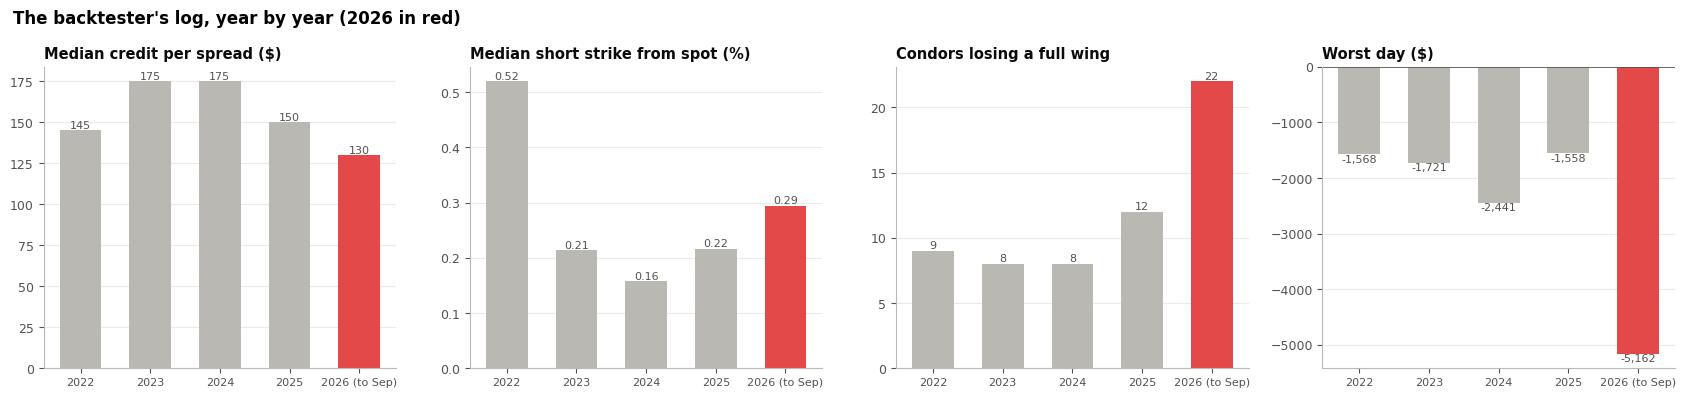

,spx,credit_per_spread,short_dist_pct,vix,breached_pct,condors,avg_pl_condor,full_wing_losses,total_pl,worst_day
year,,,,,,,,,,
2022,3951.05,145.0,0.52,25.43,10.00,115,183.19,9,21066.80,-1567.64
2023,4340.56,175.0,0.21,16.13,19.82,164,160.59,8,26336.68,-1720.64
2024,5309.83,175.0,0.16,13.88,22.63,179,137.34,8,24584.48,-2440.52
2025,6443.70,150.0,0.22,16.77,14.15,212,130.25,12,27613.44,-1557.76
2026,7368.93,130.0,0.29,17.54,18.26,115,4.03,22,463.80,-5162.16


In [39]:
ly = lg.by_year(log, lc)
lg.fig_by_year(ly); plt.show()
display(ly.round(2))

| year | SPX (median) | credit per spread | short strike from spot | condors | full-wing losses | avg P/L per condor | worst day |
|---|---|---|---|---|---|---|---|
| 2022 | 3,951 | $145 | 0.52% | 115 | 9 | +$183 | -$1.6k |
| 2023 | 4,341 | $175 | 0.21% | 164 | 8 | +$161 | -$1.7k |
| 2024 | 5,310 | $175 | 0.16% | 179 | 8 | +$137 | -$2.4k |
| 2025 | 6,444 | $150 | 0.22% | 212 | 12 | +$130 | -$1.6k |
| **2026 (to Sep)** | **7,369** | **$130** | 0.29% | 115 | **22** | **+$4** | **-$5.2k** |

- **The credit has been shrinking since 2024** ($175 -> $150 -> $130 a spread) while the wing stays 10 points: a breached spread now loses
  up to $870 against $825 before, and a winning one pays less. Each full-wing loss takes more winning trades to earn back (about 6.7
  winners in 2026 against 4.7 in 2023-24).
- **The strikes are not closer:** they sit further from spot in 2026 (0.29%) than in 2023-25. What changed is the size of the moves (0.25% from
  entry to close on average in 2026, against 0.18% in 2024-25) and how many hit all seven tranches the same day.
- **22 of the 59 full-wing losses in the whole log came in 2026**, 18 of them in those three days.

**What it says about the strategy:**

- **The risk was always there, it just hadn't shown up.** Seven tranches spread over three hours on one day, with no stop, are close to one
  big position: a day that runs through one side costs ~$5k. The four years before simply had no such day on a day the filters let through.
- **The likely trigger is scheduled news.** 2026-06-16 and 06-17 were the days of a Fed (FOMC) meeting, with the decision on the 17th; the
  Thursday analysis (Section 3) found the same pattern: the strategy's worst days are days the market moves more than VIX priced, often
  macro days. This data has no economic calendar, so this is a hypothesis: **an event-day filter (no trading on FOMC decision days, and
  possibly CPI days) is the change most worth backtesting.**
- **The tranche study (Section 11) said the drawdowns were shallow:** on the rebuild they were (-$3.8k). The log shows the tail those four
  years didn't contain, and it is the number to size the strategy on.

## 15. Summary

**The greedy cascade, step by step:**

| step | trades | P/L | Sharpe | what it does |
|---|---|---|---|---|
| raw book | 39,694 | -$7.5k | -0.12 | wins 66% of condors, but the losses are twice the wins |
| + no Thursdays | 31,768 | $155.6k | 0.44 | removes the weekday where the raw book loses (-$163.0k) |
| + max move 0% | 14,416 | $195.9k | 0.97 | enters on pullbacks, so an intraday rally doesn't run into the short call |
| + above the 10-day SMA | 7,362 | $205.6k | 1.50 | keeps calm markets, where SPX moves less after entry |
| + VIX9D/VIX 0.87-1.02 | 4,630 | $213.3k | 2.25 | keeps a curve that isn't bracing for a move; both tails lose on the put side |
| + the 7 tranches | 1,582 | $113.4k | 2.48 | keeps the late morning and early afternoon; drawdown -$15.1k -> -$4.9k |
| **+ short/long <= 4** | **1,450** | **$112.0k** | **2.60** | skips the richest condors the 7 still take |

**The strategy: 1,450 trades, $112.0k, Sharpe 2.60, -$3.8k drawdown, 87.4% of trades winning**, held to expiry; +$599 on an average trading
day (76% of days positive), an average win of $285 a condor against an average loss of $399.

- **No Thursdays isn't a VIX regime:** nothing known at entry differs on Thursdays, but they move more than VIX prices (the realized range
  explains two-thirds of the loss), on a few big days every year; macro releases are the likely cause, untested here.
- **The settings work together.** The band is the worst entry filter on the raw book and adds the most at step 4; with everything on, every
  threshold is at the top of its sweep.
- **The 10-day SMA is the most important setting:** removing it costs 1.28 Sharpe and triples the drawdown. With everything on it beats the
  20-day in every year (t = 1.73 on the Sharpe difference, p = 0.08: significant at 10%, not at 5%); the edge is lower risk, not more
  money. On the drawdown-picked tranches it still leads (2.29 against 1.97, a third of the drawdown) but not significantly (p = 0.38).
- **No stop:** on this strategy every call-stop level lowers Sharpe and P/L and none reduces the drawdown, and a put stop is worse still
  (400%: Sharpe 1.91, -$21.8k; 42% of the stopped puts would have expired winning) (Section 9). The cost is exposure to a day worse than any
  in this sample.
- **The 7 tranches are the smallest, steadiest set:** the smallest drawdown and the most P/L per $ of drawdown of the sets tested. Adding
  11:13 and 13:33 (forward selection's peak) scores a higher Sharpe (2.73) for $29.8k more and a deeper drawdown; the previous 15, 2.69 for
  $68.4k more. None of the 7 should be cut: each made money every year and each one's removal lowers Sharpe.

- **The backtester's log shows a 2026 drawdown the export doesn't reach:** -$13.4k from 2026-05-11 to 06-17, not recovered by 2026-09-28,
  from three days on which all seven tranches lost a full wing (Section 14). The rebuild matches the log to 2026-05-07; size the strategy on
  that tail, not on the -$3.8k of 2022-2026, and backtest an event-day (FOMC/CPI) filter.

**What this notebook doesn't establish:** out-of-sample performance (apart from the walk-forward checks); the backtester's totals on these
settings (the rules were matched trade by trade against a backtest on earlier settings, with the 20-day SMA; the 10-day and the 7 tranches
haven't been checked against a backtest log); the first sessions, which need SPX closes before the export; and a put stop, which is untested.